The problem is that I should use proper barcode counting, I must see how many of barcodes I am counting from barcode sequencing
Some of those barcodes have N in their sequence and with simple matching you can't use them, there should be proper way to assign them, like minimap2

In [216]:
import itertools
import os
import re
import warnings
from scipy import stats


import sfmap_normal
from scipy.stats import pearsonr, mannwhitneyu, wilcoxon, gaussian_kde, ttest_ind

import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 300  # High resolution
import numpy as np

from datetime import datetime
from collections import Counter

from matplotlib_venn import venn3, venn3_circles


import alignparse.targets
import seaborn as sns
from IPython.display import display, HTML
from matplotlib.backends.backend_pdf import PdfPages


from sklearn.decomposition import PCA
from adjustText import adjust_text

import pandas as pd
from pathlib import Path
from sklearn.metrics import r2_score

from Bio.Seq import Seq
from Bio import SeqIO

import random

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Helvetica'

# Set global font to Helvetica
mpl.rcParams['font.family'] = 'Helvetica'


import yaml
warnings.simplefilter('ignore')

# Push changes to Git

In [217]:
!git add "*.py" "*.ipynb"
!git commit -m "Update notebooks and Python scripts"
!git push origin main

[main e6430f7] Update notebooks and Python scripts
 1 file changed, 70 insertions(+), 5 deletions(-)
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 10 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 100.89 KiB | 561.00 KiB/s, done.
Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/vaslanzadeh/gba1_flowseq.git
   30d0f64..e6430f7  main -> main


In [62]:
def three_to_one_mut(mutation):
    aa_table = {
        'Ala':'A','Arg':'R','Asn':'N','Asp':'D','Cys':'C',
        'Gln':'Q','Glu':'E','Gly':'G','His':'H','Ile':'I',
        'Leu':'L','Lys':'K','Met':'M','Phe':'F','Pro':'P',
        'Ser':'S','Thr':'T','Trp':'W','Tyr':'Y','Val':'V',
        'Ter':'*'
    }

    import re

    # Remove white space if present
    mutation = mutation.strip()
    # Remove leading "p." if present
    mutation = mutation.lstrip('p.')
    match = re.match(r"([A-Za-z]{3})(\d+)([A-Za-z]{3})", mutation)
    if not match:
        return mutation  # return unchanged if format unknown

    ref, pos, alt = match.groups()
    return aa_table.get(ref, ref) + pos + aa_table.get(alt, alt)


def one_to_three_mut(mutation):
    aa_table_reverse = {
        'A': 'Ala', 'R': 'Arg', 'N': 'Asn', 'D': 'Asp', 'C': 'Cys',
        'Q': 'Gln', 'E': 'Glu', 'G': 'Gly', 'H': 'His', 'I': 'Ile',
        'L': 'Leu', 'K': 'Lys', 'M': 'Met', 'F': 'Phe', 'P': 'Pro',
        'S': 'Ser', 'T': 'Thr', 'W': 'Trp', 'Y': 'Tyr', 'V': 'Val',
        '*': 'Ter'
    }

    import re
    
    # Remove white space if present
    mutation = mutation.strip()
    # Remove leading "p." if present (we'll add it back at the end)
    mutation = mutation.lstrip('p.')
    
    # Match patterns like: A123G (standard) or A123* (with Ter)
    match = re.match(r"([A-Za-z\*])(\d+)([A-Za-z\*])", mutation)
    if not match:
        return mutation  # return unchanged if format unknown
    
    ref, pos, alt = match.groups()
    
    # Convert to uppercase for lookup
    ref_upper = ref.upper()
    alt_upper = alt.upper()
    
    # Convert using the reverse table
    ref_three = aa_table_reverse.get(ref_upper, ref)
    alt_three = aa_table_reverse.get(alt_upper, alt)
    
    # Return with "p." prefix
    return f"p.{ref_three}{pos}{alt_three}"

In [63]:
plot_cmap = {
    
    "EmberRed": "#7C1900",
    "TranqMist": "#466058",
    "SapphBlue": "#438CBD",
    "GoldHarmon": "#DACF6D",
    "AmberBurst": "#9E5817",
    "AzureDream": "#61BDD2",
    "CopperSet": "#B99131",
    "TwilightIndigo": "#305CAB",
    "green": "#278343",
    "grey" : "#b7b7b7"
}

Read the configuration file:

In [64]:
with open('config.yaml') as f:
    config = yaml.safe_load(f)

Make output directory for counts:

## Load Codon-Variant table

In [65]:
#read codon_variant_table generated by pacbio sequencing and pbData_analysis
variants = pd.read_table(f'{config["codon_variant_table_file"]}', na_filter=None, sep=',')
        
display(HTML(variants.head().to_html(index=False)))

library,barcode,variant_call_support,number_of_indels,codon_substitutions,aa_substitutions,n_codon_substitutions,n_aa_substitutions,variant_class,aa_substitutions_c
GBA1,AAGCGGACTGCACGTCGTCTTTTTTTTTTT,1,0,,,0,0,wildtype,wildtype
GBA1,ACCATGTATCGACCCTATCATTTTTTTTTT,1,0,CGC78CAG,R78Q,1,1,1 nonsynonymous,R78Q
GBA1,TAAGTCGCTGCGCGGATGTCGTTTTTTTTT,13,0,,,0,0,wildtype,wildtype
GBA1,AGGCAAAACTGCTACTTGCCTGTTTTTTTT,8,0,AGC47TGG,S47W,1,1,1 nonsynonymous,S47W
GBA1,TTGTTTAGCTGTCAACCCCCCGTTTTTTTT,44,0,,,0,0,wildtype,wildtype


In [66]:
x1 = variants[variants['n_aa_substitutions']==1]['aa_substitutions']
x2 = x1[~x1.str.startswith('*')]
x2.nunique()

10444

In [67]:
#The first part of the code filters invalid codon substitutions like CAA440AAG
#position 440 is CAG not CAA
df=variants.copy()
# --------------------------------------------------
# 1. Build reference codons from CDS sequence
# --------------------------------------------------

cds_seq = (
    "ATGGAGTTTTCAAGTCCTTCCAGAGAGGAATGTCCCAAGCCTTTGAGTAGGGTAAGCATCATGGCTGGCAGCCTCACAGGATTGCTTCTACTTCAGGCAGTGTCGTGGGCATCAGGTGCCCGCCCCTGCATCCCTAAAAGCTTCGGCTACAGCTCGGTGGTGTGTGTCTGCAATGCCACATACTGTGACTCCTTTGACCCCCCGACCTTTCCTGCCCTTGGTACCTTCAGCCGCTATGAGAGTACACGCAGTGGGCGACGGATGGAGCTGAGTATGGGGCCCATCCAGGCTAATCACACGGGCACAGGCCTGCTACTGACCCTGCAGCCAGAACAGAAGTTCCAGAAAGTGAAGGGATTTGGAGGGGCCATGACAGATGCTGCTGCTCTCAACATCCTTGCCCTGTCACCCCCTGCCCAAAATTTGCTACTTAAATCGTACTTCTCTGAAGAAGGAATCGGATATAACATCATCCGGGTACCCATGGCCAGCTGTGACTTCTCCATCCGCACCTACACCTATGCAGACACCCCTGATGATTTCCAGTTGCACAACTTCAGCCTCCCAGAGGAAGATACCAAGCTCAAGATACCCCTGATTCACCGAGCCCTGCAGTTGGCCCAGCGTCCCGTTTCACTCCTTGCCAGCCCCTGGACATCACCCACTTGGCTCAAGACCAATGGAGCGGTGAATGGGAAGGGGTCACTCAAGGGACAGCCCGGAGACATCTACCACCAGACCTGGGCCAGATACTTTGTGAAGTTCCTGGATGCCTATGCTGAGCACAAGTTACAGTTCTGGGCAGTGACAGCTGAAAATGAGCCTTCTGCTGGGCTGTTGAGTGGATACCCCTTCCAGTGCCTGGGCTTCACCCCTGAACATCAGCGAGACTTCATTGCCCGTGACCTAGGTCCTACCCTCGCCAACAGTACTCACCACAATGTCCGCCTACTCATGCTGGATGACCAACGCTTGCTGCTGCCCCACTGGGCAAAGGTGGTACTGACAGACCCAGAAGCAGCTAAATATGTTCATGGCATTGCTGTACATTGGTACCTGGACTTTCTGGCTCCAGCCAAAGCCACCCTAGGGGAGACACACCGCCTGTTCCCCAACACCATGCTCTTTGCCTCAGAGGCCTGTGTGGGCTCCAAGTTCTGGGAGCAGAGTGTGCGGCTAGGCTCCTGGGATCGAGGGATGCAGTACAGCCACAGCATCATCACGAACCTCCTGTACCATGTGGTCGGCTGGACCGACTGGAACCTTGCCCTGAACCCCGAAGGAGGACCCAATTGGGTGCGTAACTTTGTCGACAGTCCCATCATTGTAGACATCACCAAGGACACGTTTTACAAACAGCCCATGTTCTACCACCTTGGCCACTTCAGCAAGTTCATTCCTGAGGGCTCCCAGAGAGTGGGGCTGGTTGCCAGTCAGAAGAACGACCTGGACGCAGTGGCACTGATGCATCCCGATGGCTCTGCTGTTGTGGTCGTGCTAAACCGCTCCTCTAAGGATGTGCCTCTTACCATCAAGGATCCTGCTGTGGGCTTCCTGGAGACAATCTCACCTGGCTACTCCATTCACACCTACCTGTGGCGTCGCCAGTGA"
).upper()

# Map codon position (1-based) -> reference codon
ref_codons = {
    i + 1: cds_seq[i*3:(i+1)*3]
    for i in range(len(cds_seq) // 3)
}

def filter_invalid_subs_keep_rows(codon_string, ref_codons, invalid_tracker=None):
    """
    Returns a string of only valid codon substitutions.
    Keeps empty strings for rows that had no valid substitutions.
    """
    if pd.isna(codon_string) or str(codon_string).strip() == "":
        return ""  # keep empty strings for empty/NaN input

    valid_subs = []
    subs = str(codon_string).split()
    for sub in subs:
        m = re.match(r"([ACGT]{3})(\d+)([ACGT]{3})", sub)
        if not m:
            if invalid_tracker is not None:
                invalid_tracker.setdefault('format_errors', set()).add(sub)
            continue

        ref, pos, alt = m.groups()
        pos = int(pos)

        if pos in ref_codons and ref_codons[pos] == ref:
            valid_subs.append(sub)
        else:
            if invalid_tracker is not None:
                # Group by position
                key = f"Position {pos} (expected: {ref_codons.get(pos, 'N/A')})"
                invalid_tracker.setdefault('mismatches', {}).setdefault(key, set()).add(sub)  # Just add the original string

    return " ".join(valid_subs)

# --------------------------------------------------
# Apply to DataFrame
# --------------------------------------------------
print("Processing codon substitutions...")

# Use a dictionary to track invalid substitutions
invalid_tracker = {
    'mismatches': {},  # position description -> set of invalid substitutions
    'format_errors': set()
}

# Process all rows
df['codon_substitutions'] = df['codon_substitutions'].apply(
    lambda x: filter_invalid_subs_keep_rows(x, ref_codons, invalid_tracker)
)

# Print results
print("\nUnique invalid codon substitutions found:")

# Print format errors
if invalid_tracker['format_errors']:
    print("\nInvalid format errors:")
    for error in sorted(invalid_tracker['format_errors']):
        print(f"  Invalid format: '{error}'")

# Print mismatches grouped by position
if invalid_tracker['mismatches']:
    print("\nInvalid reference/position mismatches:")
    
    for position_desc in sorted(invalid_tracker['mismatches'].keys()):
        invalid_subs = sorted(invalid_tracker['mismatches'][position_desc])
        print(f"\n  {position_desc}:")
        
        # Print all substitutions for this position
        for sub in invalid_subs:
            print(f"    {sub}")

print("\nProcessing complete.")


#======------------------------------------------------


def parse_mutation_code(code):
    """Parse a single mutation code like 'AAC235AAT' into components."""
    match = re.match(r'([ACGT]+)(\d+)([ACGT]+)', code)
    if not match:
        raise ValueError(f"Invalid mutation code format: {code}")
    
    ref_bases = match.group(1)
    position = int(match.group(2))
    alt_bases = match.group(3)
    
    return ref_bases, position, alt_bases

def mutation_code_to_hgvs(code_string, transcript_id="NM_004562.3"):
    """
    Convert mutation code(s) to HGVS format.
    """
    codes = code_string.strip().split()
    all_variants = []
    
    for code in codes:
        try:
            ref_bases, position, alt_bases = parse_mutation_code(code)
            base_position = position * 3
            
            for i, (ref_base, alt_base) in enumerate(zip(ref_bases, alt_bases)):
                if ref_base != alt_base:
                    transcript_pos = base_position - (2 - i)
                    variant = f"{transcript_pos}{ref_base}>{alt_base}"
                    all_variants.append(variant)
                    
        except ValueError as e:
            print(f"Warning: {e}")
    
    # Format the HGVS string
    if not all_variants:
        return f"{transcript_id}:c.[]"
    elif len(all_variants) == 1:
        return f"{transcript_id}:c.{all_variants[0]}"
    else:
        all_variants.sort(key=lambda x: int(re.search(r'\d+', x).group()))
        return f"{transcript_id}:c.[{';'.join(all_variants)}]"

def add_hgvs_transcript_column(df, codon_column='codon_substitutions', aa_column='aa_substitutions'):
    """
    Add hgvs_transcript column, omitting rows where aa_substitution is empty.
    
    Parameters:
    df: pandas Frame
    codon_column: str, name of column with codon mutation codes
    aa_column: str, name of column with amino acid substitutions
    
    Returns:
    pandas DataFrame with new 'hgvs_transcript' column
    """
    df = df.copy()
    
    # Filter out rows where aa_substitution is empty (NaN, None, or empty string)
    mask = df[aa_column].notna() & (df[aa_column].astype(str).str.strip() != '')
    
    # Apply conversion only to rows with aa_substitution
    df.loc[mask, 'hgvs_transcript'] = df.loc[mask, codon_column].apply(mutation_code_to_hgvs)
    
    # For rows without aa_substitution, set hgvs_transcript as NaN
    df.loc[~mask, 'hgvs_transcript'] = np.nan
    
    return df

# Example usage
if __name__ == "__main__":
    
    
    # Add hgvs_transcript column
    df_with_hgvs = add_hgvs_transcript_column(df)
    
    print("\nDataFrame with hgvs_transcript column (rows with empty aa_substitution omitted):")

    print("\n" + "="*80)
    print("\nCounts:")
    print(f"Total rows: {len(df)}")
    print(f"Rows with aa_substitution: {df['aa_substitutions'].notna().sum()}")
    print(f"Rows with hgvs_transcript: {df_with_hgvs['hgvs_transcript'].notna().sum()}")
    
    # Show only rows that have hgvs_transcript values
    print("\n" + "="*80)
    print("Rows with hgvs_transcript values:")
    variants = df_with_hgvs



variants.to_csv('mutalyzer/gba1_variants_with_hgvs_transcript.csv', index=False)

Processing codon substitutions...

Unique invalid codon substitutions found:

Processing complete.

DataFrame with hgvs_transcript column (rows with empty aa_substitution omitted):


Counts:
Total rows: 184878
Rows with aa_substitution: 184878
Rows with hgvs_transcript: 123668

Rows with hgvs_transcript values:


Read the PacBio amplicon target sequence and translate it to protein

In [68]:
plot_cmap = {
    
    "EmberRed": "#7C1900",
    "TranqMist": "#466058",
    "SapphBlue": "#438CBD",
    "GoldHarmon": "#DACF6D",
    "AmberBurst": "#9E5817",
    "AzureDream": "#61BDD2",
    "CopperSet": "#B99131",
    "TwilightIndigo": "#305CAB",
    "green": "#278343",
    "grey" : "#b7b7b7"
}




name_map = {
    'gba1_r1': 'gba1_r1 Gcase flowSeq',
}



Classify the variants and flag wt and synonymous variants in aa_substitutions column

In [69]:
#can assign variatn class column if not present in df generated by pbData_analysis.ipynb
def classify_variants(df):
    def classify(row):
        if row["n_codon_substitutions"] == 0:
            return "wildtype"
        elif row["n_codon_substitutions"] > 0 and row["n_aa_substitutions"] == 0:
            return "synonymous"
        elif "*" in str(row["aa_substitutions"]) and row["n_aa_substitutions"]==1:
            return "stop"
        elif row["n_aa_substitutions"] == 1:
            return "1 nonsynonymous"
        else:
            return ">1 nonsynonymous"
    df["variant_class"] = df.apply(classify, axis=1)
    return df


variants=classify_variants(variants)
variants['aa_substitutions']=variants['aa_substitutions'].where(variants['aa_substitutions'] != '', variants['variant_class'])

## Read enrich2 barcode counts (values) for each facs run (key) as dict
We want to see how many of the barcodes per single variant (assigned by PacBio) have got reads after in FACS sorting

In [70]:
col_names = ['barcode','bin1', 'bin2', 'bin3', 'bin4']

barcode_counts={}

gba1_r1=pd.read_table("enrich2_counts/main_barcodes_counts_unfiltered.tsv", names=col_names, skiprows=1)

gba1_r1['total_count'] = gba1_r1[col_names[1:]].sum(axis=1)

barcode_counts['gba1_r1']=gba1_r1

gba1_r1


,barcode,bin1,bin2,bin3,bin4,total_count
0,AAAAAAAACGCCAGATTGAGGAAGACGTAG,1.0,NaN,NaN,NaN,1.0
1,AAAAAAAAGGATTTAAGTAGTGAATGCAGA,1.0,NaN,3.0,226.0,230.0
2,AAAAAAACATCCTGTAAAAAAAGATGGGCC,785.0,393.0,543.0,1.0,1722.0
3,AAAAAAACGCCAGATTGAGGAAGACGTAGA,2492.0,1678.0,566.0,6.0,4742.0
4,AAAAAAACTTGCACGTAGTTAACGTATACA,7.0,998.0,157.0,426.0,1588.0
...,...,...,...,...,...,...
167178,TTTTTTTGCTTCTTGTAACCAAGGCGAACC,16.0,4.0,11.0,10.0,41.0
167179,TTTTTTTGGCCCAAAAGAGGTTTCACATCC,10.0,5.0,4.0,17.0,36.0
167180,TTTTTTTGTATCACGCGGATAGGGACGACG,6.0,7.0,3.0,2.0,18.0
167181,TTTTTTTTGAACAACAGCCGCTTTGCCACC,1355.0,22.0,613.0,421.0,2411.0


## score barcodes individually

In [132]:
barcode_scored={}
stdDict={}
bins = ['bin1', 'bin2', 'bin3', 'bin4']
constan_values=[0.25,0.5,0.75,1]

for library, df in barcode_counts.items():
    count=pd.merge(variants, df, on='barcode', how='left').fillna(0) # merge barcode counts with variant table
    
    count=count[count['total_count']>=150].reset_index(drop=True)


    count[['bin1_freq', 'bin2_freq', 'bin3_freq', 'bin4_freq']] = count[['bin1', 'bin2', 'bin3', 'bin4']].div(count[['bin1', 'bin2', 'bin3', 'bin4']].sum())

    count[['bin1_weighted_freq', 'bin2_weighted_freq', 'bin3_weighted_freq', 'bin4_weighted_freq']] = count[['bin1_freq', 'bin2_freq', 'bin3_freq', 'bin4_freq']].mul([0.25,0.5,0.75,1])

    count['barcode_weighted_avg']=((count[['bin1_weighted_freq', 'bin2_weighted_freq', 'bin3_weighted_freq', 'bin4_weighted_freq']].sum(axis=1))/
                    (count[['bin1_freq', 'bin2_freq', 'bin3_freq', 'bin4_freq']].sum(axis=1)))

    #count.reset_index(inplace=True, drop=True)
    
    
    count=count.reset_index()
    df=count
    
    df_wt=(df[df['aa_substitutions']=='wildtype'])
    
    wt_std=round(np.std(df_wt['barcode_weighted_avg']),3)
    
    df_syn=(df[df['aa_substitutions']=='synonymous'])
    
    syn_std=round(np.std(df_syn['barcode_weighted_avg']),3)
    
    df_nonSyn = df[(df['aa_substitutions'] != 'wildtype') & (df['aa_substitutions'] != 'synonymous')]
    
    df_varCount = len(np.unique(df[df['variant_class']=='1 nonsynonymous']['aa_substitutions']))
    
    nonSyn_std=round(np.std(df_nonSyn['barcode_weighted_avg']),3)
    
    
    stdDict[library] = {
        'ScoredBarcodes': len(df.dropna(subset=["barcode_weighted_avg"])),
        'wt_std': wt_std,
        'syn_std': syn_std,
        'nonSyn_std': nonSyn_std
    }

    print (f'{library} ScoredBarcodes: {len(df.dropna(subset=["barcode_weighted_avg"]))},\
    varCount: {df_varCount} \
    wt_std: {wt_std}, \
    syn_std: {syn_std}, \
    nonSyn_std: {nonSyn_std}')
    
    count['barcode_weighted_avg_var'] = count['barcode_weighted_avg'] * (1 / (wt_std))
    
    barcode_scored[library]=count
    
    
bc_score = barcode_scored['gba1_r1'][['barcode','aa_substitutions','codon_substitutions','barcode_weighted_avg']]
bc_score.rename(columns={'barcode_weighted_avg': 'gba1_r1'}, inplace=True)

for library, df in barcode_scored.items():
    if library != 'gba1_r1':
        
        df=df[['barcode','aa_substitutions','barcode_weighted_avg']]
        df.rename(columns={'barcode_weighted_avg': library}, inplace=True)
    
        bc_score = pd.merge(bc_score, df, on=['barcode','aa_substitutions'], how='outer')

gba1_r1 ScoredBarcodes: 163642,    varCount: 9886     wt_std: 0.134,     syn_std: 0.133,     nonSyn_std: 0.155


In [221]:
bc_score_toSave=bc_score.copy()
bc_score_toSave=bc_score_toSave[~bc_score_toSave['aa_substitutions'].str.startswith('*')]
bc_score_toSave.rename(columns={'gba1_r1': 'barcode_score'}, inplace=True)
bc_score_toSave.to_csv('GBA1_barcode_scores.csv', index=False)

## save averaged barcode scores

In [72]:
df_bcScore=bc_score.copy()
df_bcScore['variant_class']=df_bcScore['aa_substitutions']

df_bcScore.loc[df_bcScore['variant_class'].str.endswith('*'), 'variant_class'] = 'nonsense'
df_bcScore.loc[~df_bcScore['variant_class'].isin(['wildtype','synonymous','nonsense']), 'variant_class'] = 'missense'


df_bcScore_data=df_bcScore.rename(columns=name_map)

df_bcScore_data.to_csv('results/scores/barcode_scores.csv', index=False)

In [73]:
np.unique(df_bcScore['variant_class'])

array(['missense', 'nonsense', 'synonymous', 'wildtype'], dtype=object)

In [119]:
df_bcScore['variant_class'].unique()

array(['wildtype', 'missense', 'synonymous', 'nonsense'], dtype=object)

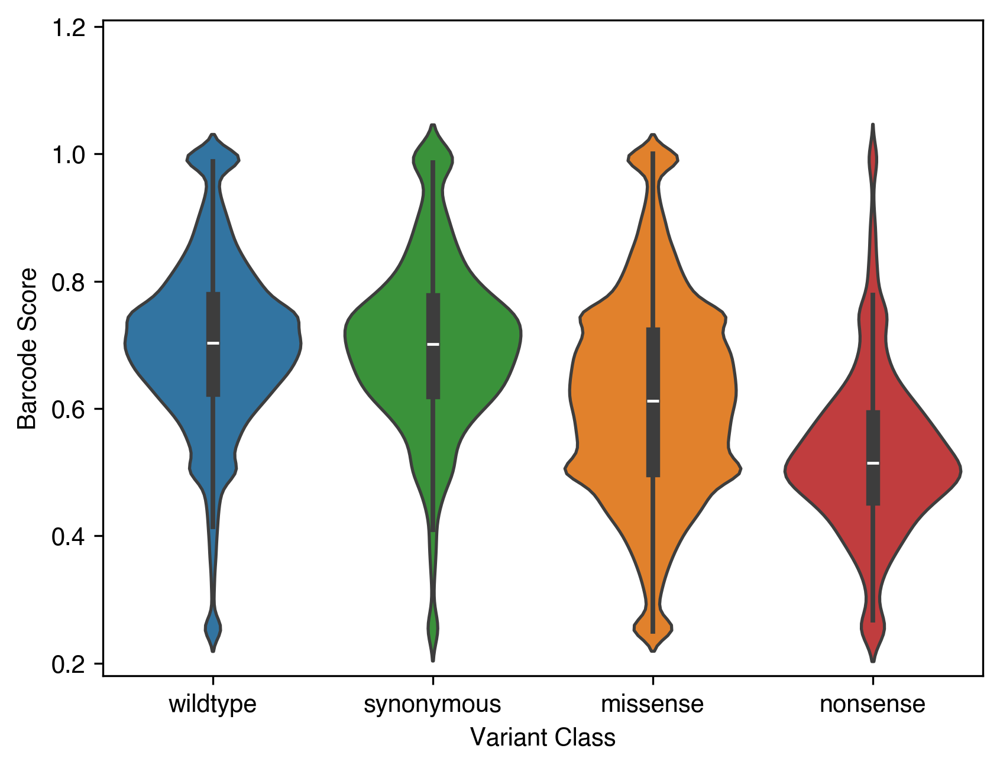

In [130]:
df_bcScore

class_order = ['wildtype',  'synonymous', 'missense','nonsense']

sns.violinplot(data=df_bcScore, x='variant_class', y='gba1_r1', hue='variant_class', order=class_order)
plt.ylim(0.18, 1.21)
plt.ylabel('Barcode Score')
plt.xlabel('Variant Class')

plt.savefig('results/scores/barcode_scores_distribution_violin.pdf')


In [76]:
# Calculating variant score withing each replicate
numeric_cols = bc_score.select_dtypes(include='number').columns

bc_score_grpd=bc_score.groupby('aa_substitutions')[numeric_cols].mean().reset_index()

# Select the rows corresponding to 'wildtype' and 'variants' separately
wildtype_score = bc_score_grpd[bc_score_grpd['aa_substitutions'] == 'wildtype']
variants_score = bc_score_grpd[~bc_score_grpd['aa_substitutions'].isin(['wildtype','synonymous'])]

# Drop 'aa_substitutions' column for division
wildtype_values = wildtype_score.drop(columns='aa_substitutions')
variants_values = variants_score.drop(columns='aa_substitutions')

# Perform division
variants_divided_by_wildtype = variants_values.divide(wildtype_values.iloc[0])

# Update 'variants_row' DataFrame with the result
variants_score.loc[:, variants_divided_by_wildtype.columns] = variants_divided_by_wildtype

variants_score['position']=variants_score['aa_substitutions'].apply(lambda x: int(x[1:-1]))
# calculating variant score for avregaes, here is the place to apply weighting
variants_score['gba1_r1']=np.log2(variants_score['gba1_r1'])

#Synonymous variant score calculation ###########
bc_score_syn=bc_score[bc_score['aa_substitutions']=='synonymous']
bc_score_syn
syn_score=bc_score_syn.groupby('codon_substitutions')[numeric_cols].mean().reset_index()
syn_score
syn_score_values = syn_score.drop(columns='codon_substitutions')

# Perform division
syn_divided_by_wildtype = syn_score_values.divide(wildtype_values.iloc[0])

# Update 'variants_row' DataFrame with the result
syn_score.loc[:, syn_divided_by_wildtype.columns] = syn_divided_by_wildtype
syn_score['gba1_r1']=np.log2(syn_score['gba1_r1'])
#########################################################

variants_score_dict={}
variants_score_dict['gba1_r1']=variants_score[['aa_substitutions','gba1_r1']]



variants_score.to_csv('results/scores/variants_scores.csv', index=False)

# Prepare barcode score for FDR calculations
make a df for each experiment, count number of barcodes they have in each replicates, and then rpeat the barcode scores based on their sum of barcode counts in the replicates

In [77]:
df=bc_score[['barcode','aa_substitutions','gba1_r1']]

df['Rep']=1
df.dropna(subset='gba1_r1', inplace=True)

gba1_r1_WtPool=list(df[df['aa_substitutions']=='wildtype']['gba1_r1'])
gba1_r1_VarRepBarCont=df.groupby('aa_substitutions').size().to_dict()
del gba1_r1_VarRepBarCont['wildtype']
del gba1_r1_VarRepBarCont['synonymous']

numeric_cols = df.select_dtypes(include='number').columns
gba1_r1_VarScore=df.groupby('aa_substitutions')[numeric_cols].mean()['gba1_r1'].to_dict()

# Filter out substitutions starting with '*'
filtered_counts = {
    aa_sub: count
    for aa_sub, count in gba1_r1_VarRepBarCont.items()
    if not aa_sub.startswith('*')
}

# Count how many have 1 vs >=2 barcodes
one_barcode = sum(1 for v in filtered_counts.values() if v == 1)
multi_barcode = sum(1 for v in filtered_counts.values() if v >= 2)

print(f"Number of missense single aa substitutions linked with only one barcode: {one_barcode}")
print(f"Number of missense single aa substitutions linked with two or more barcodes: {multi_barcode}")

Number of missense single aa substitutions linked with only one barcode: 573
Number of missense single aa substitutions linked with two or more barcodes: 9837


## bootstap WT scores 10000 times for each experiment

In [78]:
lib_list=['gba1_r1_WtPool']

lib_list_dict={ 'gba1_r1':[gba1_r1_WtPool, gba1_r1_VarRepBarCont, gba1_r1_VarScore]}
                
                
start_time_clock = datetime.now().strftime("%H:%M:%S")
print("Start time:", start_time_clock)


wt_bootstraps={}
for j, library in enumerate(lib_list_dict.keys()):
    
    wt_pool=lib_list_dict[library][0] #list of wt barcode scores
                

    print ('wildtype bootstrapping for ' + library + ' please wait ...')

    print("current time:", datetime.now().strftime("%H:%M:%S")) 
    
    wt_bc_score_dists = {}
    
    highestNumberOfBarcodesPerVariant = df[~df['aa_substitutions'].isin(['wildtype', 'synonymous'])]['aa_substitutions'].value_counts().max()+1 #number of barcodes to sample from the pool


    for i in range (1, highestNumberOfBarcodesPerVariant): #number of barcodes to sample from the pool
        wt_bc_score_avg_bootstrapped=[]
        
        for _ in range(10000): #bootstrapping size
            wt_bc_score_avg_bootstrapped.append(np.mean(random.sample(wt_pool, i)))
            
        wt_bc_score_dists[i]=wt_bc_score_avg_bootstrapped
    
    wt_bootstraps[lib_list[j]]=wt_bc_score_dists
    pd.DataFrame(wt_bc_score_dists).to_csv(f"results/bootstraps/{library}_wildtype_bootstraps.csv")
    
end_time_clock = datetime.now().strftime("%H:%M:%S")
print("Finish time:", end_time_clock)

Start time: 11:16:33
wildtype bootstrapping for gba1_r1 please wait ...
current time: 11:16:33
Finish time: 11:16:53


## Calculate FDRvalues based on barcode scores and sum of their barcode counts in the replicates using wildtype bootstraps

In [79]:
#Read wildtype bootstrapping results 

wt_bootstraps_new={}
for library in lib_list_dict.keys():       
    
    df = pd.read_csv(f'results/bootstraps/{library}_wildtype_bootstraps.csv', index_col=0,skiprows=1, names=np.arange(1,highestNumberOfBarcodesPerVariant))

    wt_bootstraps_new[library] = df.to_dict(orient='series')
###

def count_greater_smaller(number, lst):
    listMean=np.mean(lst)
    if number <= listMean:
        less_than_mean = [item for item in lst if item < listMean]
        fdr = sum(1 for item in less_than_mean if item < number)
        lst_size=len(less_than_mean)
        
    if number > listMean:
        more_than_mean = [item for item in lst if item > listMean]
        fdr = sum(1 for item in more_than_mean if item > number)
        lst_size=len(more_than_mean)
    if fdr == 0:
        fdr=1
    return (fdr/lst_size)

exclude_values = ['wildtype', 'stop', 'synonymous']



for library in lib_list_dict.keys():
    
    FDRvalues = {}
    print (f'calculating FDR for {library}, please wait...')
    
    start_time_clock = datetime.now().strftime("%H:%M:%S")
    print("Start time:", start_time_clock)
    
    var_list = list(lib_list_dict[library][2].keys())
    var_list.remove('synonymous')
    var_list.remove('wildtype')
   
    WT_bootstraps=wt_bootstraps_new[library]

    for item in var_list:
        
 
        VarCount=lib_list_dict[library][1][item]
        
        VarScore=lib_list_dict[library][2][item]
        
        wt_bootstraps_list=list(WT_bootstraps[VarCount])
                                            
        fdr_1=count_greater_smaller(VarScore, wt_bootstraps_list)
                                             
        FDRvalues[item] = (fdr_1)
    
    print ("writing FDR values to df ...")
    _df = variants_score_dict[library]
    df2 = variants_score
    _df['FDRvalues']='' # this is to set FDRvalues empty 
    for item, value in FDRvalues.items():
        # Update the 'FDRvalues' column where 'aa_substitutions' matches the current item
        _df.loc[_df['aa_substitutions'] == item, 'FDRvalues'] = value
        df2.loc[df2['aa_substitutions'] == item, f'{library}_FDR'] = value
    
    _df.rename(columns={library: 'variant_score'}, inplace=True)
    
    _df=_df.dropna()
    variants_score_dict[library]=_df

    for library in lib_list_dict:
        variants_score_dict[library].to_csv(f"results/bootstraps/{library}_BArcodeScoresWithFDR.csv", index=False)

df2.to_csv('results/scores/variant_scores_withFDRs.csv')

# ── Add SD, barcode_count, confidence — insert after df2.to_csv(...) ──────────

for library in lib_list_dict.keys():

    # ── Get barcode-level scores for this library ─────────────────────────────
    # lib_list_dict[library][0] = barcode scores dict {barcode: score}
    # lib_list_dict[library][1] = barcode count per variant {variant: count}
    # lib_list_dict[library][2] = variant mean score {variant: mean_score}

    # Reconstruct barcode-level dataframe from lib_list_dict
    bc_records = []
    for variant, count in lib_list_dict[library][1].items():
        if variant in ['wildtype', 'synonymous']:
            continue
        # Get all barcodes associated with this variant
        # (need barcode->variant mapping — use barcode_scored equivalent)
    
    # ── Compute SD per variant from barcode scores ────────────────────────────
    # In GBA1 the barcode scores per variant come from the bootstrapping input
    # Use lib_list_dict[library][2] for mean scores and compute SD from raw barcodes
    
    df_out = variants_score_dict[library].copy()
    df_out.rename(columns={'FDRvalues': 'FDR'}, inplace=True)

    # Barcode count from lib_list_dict
    VarRepBarCont = {
        k: v for k, v in lib_list_dict[library][1].items()
        if k not in ['wildtype', 'synonymous']
    }
    df_out['barcode_count'] = df_out['aa_substitutions'].map(VarRepBarCont)

    # ── Confidence classification ─────────────────────────────────────────────
    def classify_confidence(row):
        fdr   = row['FDR']
        count = row['barcode_count']

        if pd.isna(fdr):
            return 'No score'
        if fdr < 0.05:
            return 'Confident'
        if count >= 3:
            return 'Confident'
        return 'Non-confident'

    df_out['confidence'] = df_out.apply(classify_confidence, axis=1)

    print(f"\n=== Confidence summary ({library}) ===")
    print(df_out['confidence'].value_counts().to_string())
    print(f"\nBarcode count distribution for FDR > 0.05 variants:")
    fdr_nonsig = df_out[df_out['FDR'] > 0.05]
    for n in range(1, 11):
        subset = fdr_nonsig[fdr_nonsig['barcode_count'] == n]
        if len(subset) > 0:
            print(f"  n={n}: {len(subset)} variants")

    variants_score_dict[library] = df_out
    df_out.to_csv(f'results/bootstraps/{library}_BArcodeScoresWithFDR_confidence.csv', index=False)

end_time_clock = datetime.now().strftime("%H:%M:%S")
print("Finish time:", end_time_clock)    

calculating FDR for gba1_r1, please wait...
Start time: 11:16:53
writing FDR values to df ...

=== Confidence summary (gba1_r1) ===
confidence
Confident        9337
Non-confident    1088

Barcode count distribution for FDR > 0.05 variants:
  n=1: 544 variants
  n=2: 544 variants
  n=3: 532 variants
  n=4: 475 variants
  n=5: 401 variants
  n=6: 297 variants
  n=7: 310 variants
  n=8: 267 variants
  n=9: 243 variants
  n=10: 220 variants
Finish time: 11:17:15


In [220]:
bc_score

,barcode,aa_substitutions,codon_substitutions,gba1_r1 Gcase flowSeq,variant_class
0,TAAGTCGCTGCGCGGATGTCGTTTTTTTTT,wildtype,,0.644729,wildtype
1,TTGTTTAGCTGTCAACCCCCCGTTTTTTTT,wildtype,,0.675546,wildtype
2,AACGTTCAGCACCTACAGGGATGTTTTTTT,A175R,GCA175AGG,0.659218,missense
3,TCTATCGAACCGATGACAGACTTGTTTTTT,D63S,GAC63TCT,0.655001,missense
4,AACCTGTAATGGTGTTTTGCATTGTTTTTT,S19F,AGC19TTT,0.744301,missense
...,...,...,...,...,...
163637,AGGCGGAGTGATGGTAAAATCCGAAAAAAA,S84K,AGT84AAG,0.604353,missense
163638,TGAGTTGGGATAGCGCTGTTCTCAAAAAAA,wildtype,,0.807947,wildtype
163639,GGGATAGATAGTAGAAGCACTTAAAAAAAA,wildtype,,0.476397,wildtype
163640,AGGGCTGGTTTTATTACGAGACAAAAAAAA,G103R,GGC103AGG,0.698222,missense


Total WT-like variants with barcode data: 5475
Variants with ≥1 barcode:  5475
Variants with ≥2 barcodes: 4964
Variants with ≥3 barcodes: 4445
Variants with ≥5 barcodes: 3471

=== gba1_r1 — Median SD per subsampled n ===
  n=2: median SD=0.076, variants eligible=4964
  n=3: median SD=0.097, variants eligible=4445
  n=4: median SD=0.107, variants eligible=3934
  n=5: median SD=0.112, variants eligible=3471
  n=6: median SD=0.116, variants eligible=3077
  n=7: median SD=0.119, variants eligible=2783
  n=8: median SD=0.122, variants eligible=2476
  n=9: median SD=0.124, variants eligible=2209
  n=10: median SD=0.126, variants eligible=1968


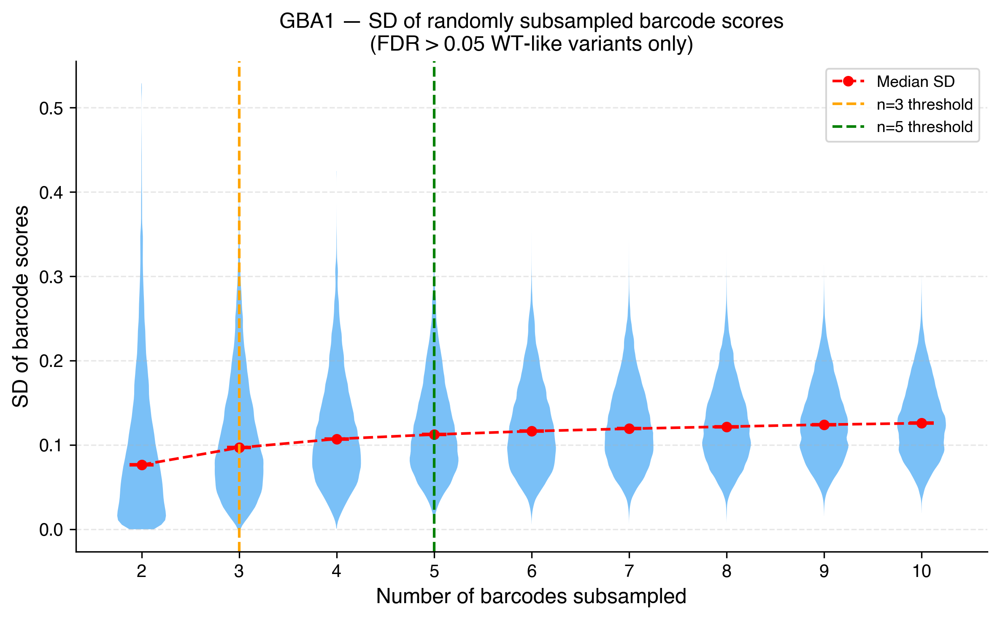

In [80]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(42)
N_ITERATIONS = 100

# ── GBA1 has one library: gba1_r1 ────────────────────────────────────────────
# barcode scores are in bc_score['gba1_r1'] column
# FDR values are in variants_score_dict['gba1_r1']['FDRvalues']

library      = 'gba1_r1'
score_col    = 'gba1_r1'   # barcode score column in bc_score

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

df_barcodes = bc_score.copy()
df_barcodes = df_barcodes[
    ~df_barcodes['aa_substitutions'].isin(['wildtype', 'synonymous']) &
    ~df_barcodes['aa_substitutions'].str.endswith('*') &
    ~df_barcodes['aa_substitutions'].str.startswith('*')
].dropna(subset=[score_col])

# ── 2. Only keep FDR > 0.05 variants (WT-like) ───────────────────────────────
wt_like_variants = set(
    variants_score_dict[library][
        variants_score_dict[library]['FDR'] > 0.05
    ]['aa_substitutions']
)
df_barcodes = df_barcodes[
    df_barcodes['aa_substitutions'].isin(wt_like_variants)
]

# ── 3. Group barcode scores per variant ───────────────────────────────────────
grouped = (
    df_barcodes
    .groupby('aa_substitutions')[score_col]
    .apply(list)
)

print(f"Total WT-like variants with barcode data: {len(grouped)}")
print(f"Variants with ≥1 barcode:  {(grouped.apply(len) >= 1).sum()}")
print(f"Variants with ≥2 barcodes: {(grouped.apply(len) >= 2).sum()}")
print(f"Variants with ≥3 barcodes: {(grouped.apply(len) >= 3).sum()}")
print(f"Variants with ≥5 barcodes: {(grouped.apply(len) >= 5).sum()}")

# ── 4. Subsampling loop ───────────────────────────────────────────────────────
all_sd_data = []

for n in range(2, 11):
    eligible = grouped[grouped.apply(len) >= n]
    
    for variant, scores in eligible.items():
        for _ in range(N_ITERATIONS):
            sample = np.random.choice(scores, size=n, replace=False)
            all_sd_data.append({
                'n_barcodes': n,
                'SD': np.std(sample, ddof=1)
            })

df_plot = pd.DataFrame(all_sd_data)

# ── 5. Violin plot ────────────────────────────────────────────────────────────
positions = list(range(2, 11))

parts = ax.violinplot(
    [df_plot[df_plot['n_barcodes'] == n]['SD'].values for n in positions],
    positions=positions,
    showmedians=True,
    showextrema=False
)

for pc in parts['bodies']:
    pc.set_facecolor('#2196F3')
    pc.set_alpha(0.6)
parts['cmedians'].set_color('red')
parts['cmedians'].set_linewidth(2)

# Median trend line
medians = [df_plot[df_plot['n_barcodes'] == n]['SD'].median() for n in positions]
ax.plot(positions, medians, 'r--o', linewidth=1.5, markersize=5, label='Median SD')

# Threshold lines
ax.axvline(x=3, color='orange', linestyle='--', linewidth=1.5, label='n=3 threshold')
ax.axvline(x=5, color='green',  linestyle='--', linewidth=1.5, label='n=5 threshold')

ax.set_title('GBA1 — SD of randomly subsampled barcode scores\n(FDR > 0.05 WT-like variants only)', fontsize=12)
ax.set_xlabel('Number of barcodes subsampled', fontsize=12)
ax.set_ylabel('SD of barcode scores', fontsize=12)
ax.set_xticks(positions)
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# ── 6. Print summary matching Parkin format ───────────────────────────────────
print(f"\n=== {library} — Median SD per subsampled n ===")
for n in positions:
    subset    = df_plot[df_plot['n_barcodes'] == n]
    n_eligible = len(grouped[grouped.apply(len) >= n])
    print(f"  n={n}: median SD={subset['SD'].median():.3f}, "
          f"variants eligible={n_eligible}")

plt.tight_layout()
plt.savefig('results/barcode_threshold_violin_GBA1.pdf', bbox_inches='tight')
plt.savefig('results/barcode_threshold_violin_GBA1.png', dpi=300, bbox_inches='tight')
plt.show()


=== GBA1 barcode count summary ===
Total variants:              9886
Mean barcodes per variant:   10.6
Median barcodes per variant: 8
Variants with <3 barcodes:  1279 (12.9%)
Variants with ≥3 barcodes:  8607 (87.1%)
Variants with ≥5 barcodes:  6995 (70.8%)
Variants with ≥10 barcodes: 4005 (40.5%)


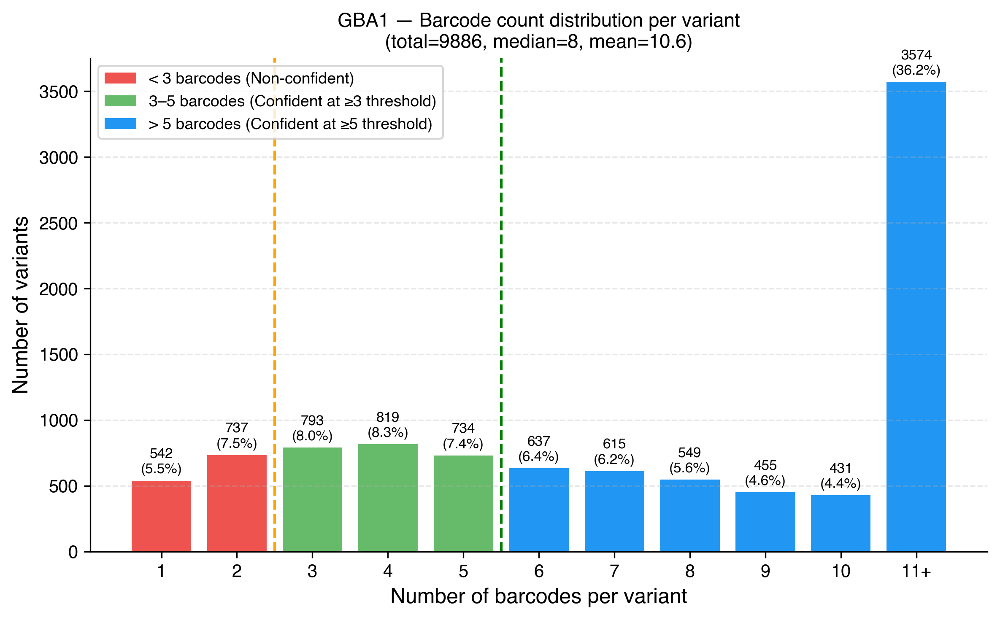

In [81]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Exclude wildtype, synonymous, stop codons
df_bc = bc_score.copy()
df_bc = df_bc[
    ~df_bc['aa_substitutions'].isin(['wildtype', 'synonymous']) &
    ~df_bc['aa_substitutions'].str.endswith('*') &
    ~df_bc['aa_substitutions'].str.startswith('*')
].dropna(subset=['gba1_r1'])

# Count barcodes per variant
counts = df_bc.groupby('aa_substitutions').size()

# Bin into 1, 2, 3 ... 10, 11+
labels = [str(i) for i in range(1, 11)] + ['11+']
binned = pd.cut(counts, bins=[0,1,2,3,4,5,6,7,8,9,10,999], labels=labels, right=True)
bar_data = binned.value_counts().reindex(labels, fill_value=0)

total = len(counts)
colors = ['#EF5350' if int(l.replace('+','99')) < 3 
          else '#66BB6A' if int(l.replace('+','99')) < 6 
          else '#2196F3' for l in labels]

bars = ax.bar(labels, bar_data.values, color=colors,
              edgecolor='white', linewidth=0.5)

# Add count and percentage labels on bars
for bar, val in zip(bars, bar_data.values):
    if val > 0:
        pct = 100 * val / total
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + total*0.003,
                f'{val}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=8)

ax.axvline(x=1.5, color='orange', linestyle='--',
           linewidth=1.5, label='n=3 threshold')
ax.axvline(x=4.5, color='green',  linestyle='--',
           linewidth=1.5, label='n=5 threshold')

ax.set_xlabel('Number of barcodes per variant', fontsize=12)
ax.set_ylabel('Number of variants', fontsize=12)
ax.set_title(f'GBA1 — Barcode count distribution per variant\n'
             f'(total={total}, median={counts.median():.0f}, '
             f'mean={counts.mean():.1f})',
             fontsize=11)
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#EF5350', label='< 3 barcodes (Non-confident)'),
    Patch(facecolor='#66BB6A', label='3–5 barcodes (Confident at ≥3 threshold)'),
    Patch(facecolor='#2196F3', label='> 5 barcodes (Confident at ≥5 threshold)'),
]
ax.legend(handles=legend_elements, fontsize=9)

print(f"\n=== GBA1 barcode count summary ===")
print(f"Total variants:              {total}")
print(f"Mean barcodes per variant:   {counts.mean():.1f}")
print(f"Median barcodes per variant: {counts.median():.0f}")
print(f"Variants with <3 barcodes:  {(counts < 3).sum()} ({100*(counts<3).mean():.1f}%)")
print(f"Variants with ≥3 barcodes:  {(counts >= 3).sum()} ({100*(counts>=3).mean():.1f}%)")
print(f"Variants with ≥5 barcodes:  {(counts >= 5).sum()} ({100*(counts>=5).mean():.1f}%)")
print(f"Variants with ≥10 barcodes: {(counts >= 10).sum()} ({100*(counts>=10).mean():.1f}%)")

plt.tight_layout()
plt.savefig('results/barcode_count_distribution_GBA1.pdf', bbox_inches='tight')
plt.savefig('results/barcode_count_distribution_GBA1.png', dpi=300, bbox_inches='tight')
plt.show()

In [82]:
wt_scores = bc_score[bc_score['aa_substitutions'] == 'wildtype']['gba1_r1']

print(f"Wildtype: n={len(wt_scores)} barcodes, "
      f"mean={wt_scores.mean():.3f}, "
      f"median={wt_scores.median():.3f}\n")

for variant in ['T408M', 'R502C']:
    scores = bc_score[bc_score['aa_substitutions'] == variant]['gba1_r1'].tolist()
    n = len(scores)
    print(f"{variant}: {n} barcodes")
    print(f"  scores: {[round(s,3) for s in scores]}")
    print(f"  mean:   {np.mean(scores):.3f}")
    print(f"  median: {np.median(scores):.3f}")
    fdr = variants_score_dict[library].loc[
        variants_score_dict[library]['aa_substitutions'] == variant, 'FDR'
    ].values
    print(f"  FDR:    {fdr[0]:.4f}" if len(fdr) > 0 else "  FDR: not found")
    print()

Wildtype: n=47733 barcodes, mean=0.700, median=0.703

T408M: 4 barcodes
  scores: [0.753, 0.627, 0.762, 0.683]
  mean:   0.706
  median: 0.718
  FDR:    0.9316

R502C: 9 barcodes
  scores: [0.728, 0.773, 0.62, 0.616, 0.629, 0.653, 0.706, 0.689, 0.689]
  mean:   0.678
  median: 0.689
  FDR:    0.6190



wt mean: 0.7004074619195831
synonymous mean: 0.6998708676394139
  mannwhitneyu between synonymous and wildtype variants (gba1_r1):
  Number of synonymous variants: 6326
  Number of wildtype variants: 47733
  mannwhitneyu-statistic: 149480768.5000
  P-value: 0.1988
aa_substitutions
*537A     2
*537C     4
*537D     1
*537F     4
*537G    12
         ..
Y79R     19
Y79S     33
Y79T     17
Y79V     17
Y79W      9
Length: 10425, dtype: int64


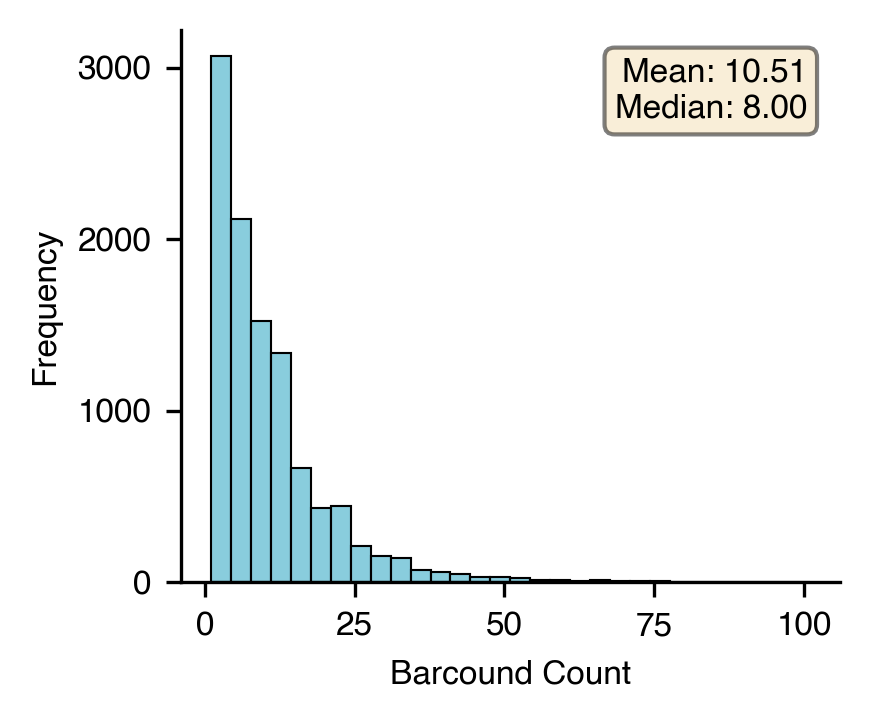

In [156]:
# Create figure with a single subplot
fig, ax = plt.subplots(1, 1, figsize=(3, 2.5))

library = 'gba1_r1'
title = 'gba1_r1'

temp_df = barcode_scored[library]
temp_df_syn_score = list(temp_df[temp_df['variant_class'].isin(['synonymous'])]['barcode_weighted_avg'])
temp_df_wt_score = list(temp_df[temp_df['variant_class'].isin(['wildtype'])]['barcode_weighted_avg'])

# Perform t-test
print(f'wt mean: {np.mean(temp_df_wt_score)}')
print(f'synonymous mean: {np.mean(temp_df_syn_score)}')
t_stat, p_value = stats.mannwhitneyu(temp_df_syn_score, temp_df_wt_score)

print(f"  mannwhitneyu between synonymous and wildtype variants ({library}):")
print(f"  Number of synonymous variants: {len(temp_df_syn_score)}")
print(f"  Number of wildtype variants: {len(temp_df_wt_score)}")
print(f"  mannwhitneyu-statistic: {t_stat:.4f}")
print(f"  P-value: {p_value:.4f}")

temp_df = temp_df[~temp_df['variant_class'].isin(['wildtype', 'synonymous'])]
counts = temp_df.groupby('aa_substitutions').size()

mean_count = counts.mean()
median_count = counts.median()
print(counts)

# Plot histogram
sns.histplot(counts, bins=30, ax=ax, color='#61BDD2')
ax.set_xlabel("Barcound Count", fontsize=8)
ax.set_ylabel("Frequency", fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

plt.yticks(fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


# Add statistics text
ax.text(0.95, 0.95, f'Mean: {mean_count:.2f}\nMedian: {median_count:.2f}',
        transform=ax.transAxes, verticalalignment='top',
        horizontalalignment='right', fontsize=8,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# plot heatmaps
## first format dataframes, pivoting to dfs to have positions in rows and 20 amino acids list in columns

In [87]:
geneseq='atggagttttcaagtccttccagagaggaatgtcccaagcctttgagtagggtaagcatcatggctggcagcctcacaggattgcttctacttcaggcagtgtcgtgggcatcaggtgcccgcccctgcatccctaaaagcttcggctacagctcggtggtgtgtgtctgcaatgccacatactgtgactcctttgaccccccgacctttcctgcccttggtaccttcagccgctatgagagtacacgcagtgggcgacggatggagctgagtatggggcccatccaggctaatcacacgggcacaggcctgctactgaccctgcagccagaacagaagttccagaaagtgaagggatttggaggggccatgacagatgctgctgctctcaacatccttgccctgtcaccccctgcccaaaatttgctacttaaatcgtacttctctgaagaaggaatcggatataacatcatccgggtacccatggccagctgtgacttctccatccgcacctacacctatgcagacacccctgatgatttccagttgcacaacttcagcctcccagaggaagataccaagctcaagatacccctgattcaccgagccctgcagttggcccagcgtcccgtttcactccttgccagcccctggacatcacccacttggctcaagaccaatggagcggtgaatgggaaggggtcactcaagggacagcccggagacatctaccaccagacctgggccagatactttgtgaagttcctggatgcctatgctgagcacaagttacagttctgggcagtgacagctgaaaatgagccttctgctgggctgttgagtggataccccttccagtgcctgggcttcacccctgaacatcagcgagacttcattgcccgtgacctaggtcctaccctcgccaacagtactcaccacaatgtccgcctactcatgctggatgaccaacgcttgctgctgccccactgggcaaaggtggtactgacagacccagaagcagctaaatatgttcatggcattgctgtacattggtacctggactttctggctccagccaaagccaccctaggggagacacaccgcctgttccccaacaccatgctctttgcctcagaggcctgtgtgggctccaagttctgggagcagagtgtgcggctaggctcctgggatcgagggatgcagtacagccacagcatcatcacgaacctcctgtaccatgtggtcggctggaccgactggaaccttgccctgaaccccgaaggaggacccaattgggtgcgtaactttgtcgacagtcccatcattgtagacatcaccaaggacacgttttacaaacagcccatgttctaccaccttggccacttcagcaagttcattcctgagggctcccagagagtggggctggttgccagtcagaagaacgacctggacgcagtggcactgatgcatcccgatggctctgctgttgtggtcgtgctaaaccgctcctctaaggatgtgcctcttaccatcaaggatcctgctgtgggcttcctggagacaatctcacctggctactccattcacacctacctgtggcgtcgccagtga'
aa_seq = Seq(geneseq).translate()
aa_seq

AA_LIST=sfmap_normal.AA_LIST

def get_PosWTaaVARaa(aa_substitutions):
        pos = int(aa_substitutions[1:-1])
        wt_aa = aa_substitutions[:1]
        variant_aa = aa_substitutions[-1:]
        return wt_aa, pos, variant_aa

def pivot_df(df):

    df['wt_aa'], df['position'], df['variant_aa'] = zip(*df['aa_substitutions'].apply(get_PosWTaaVARaa))
    

    #pivot df for heatmapt plotting
    df_score=pd.pivot_table(df,
                   index='position', 
                   columns='variant_aa', 
                   values='variant_score').reset_index()
    
    df_score.columns.name = None

    df_empty = pd.DataFrame(
    index=range(1, len(aa_seq)+1),  # positions 1 .. len(aa_seq)-1
    columns=AA_LIST
    ).reset_index()

    # Rename the index column to 'position'
    df_empty = df_empty.rename(columns={"index": "position"})

    df_filled = df_empty.merge(df_score, on="position", how="left", suffixes=('', '_y'))

    # Fill NaNs in df_empty with pivoted values
    for col in AA_LIST:
        df_filled[col] = df_filled[col].combine_first(df_filled[col + "_y"])
        df_filled.drop(columns=[col + "_y"], inplace=True)
    
    df_filled.sort_values('position', ascending=True, inplace=True)
    
    df_filled = df_filled.rename_axis(None, axis=1)
    df_filled.reset_index(drop=True, inplace=True)


    #check if there is missing positions in df
    aa_range = range(1, 537)
    position_set = set(df_filled.position)

    missing_elements = [item for item in aa_range if item not in position_set]
    if len(missing_elements) > 0:
        print("Missing positions from df:", missing_elements)
    
    '''
    if 'FDRvalues' in df.columns: #this will only work for average of replicates variant scores where they have FDR_values not for individual replicates
        df_se=pd.pivot_table(df,
                       index='position', 
                       columns='variant_aa', 
                       values='FDRvalues').reset_index()

        df_se.sort_values('position', ascending=True, inplace=True)


        #check if there is missing positions in df
        position_set = set(df_se.position)

        missing_elements = [item for item in aa_range if item not in position_set]
        if len(missing_elements) > 1:
            print("Missing positions from df:", missing_elements)
    '''
    df_filled['median_score']=df_filled[AA_LIST].median(axis=1)
    df_filled['mean_score']=df_filled[AA_LIST].mean(axis=1)
    return df_filled


## pivot average variant scores and store in variantsScore_melt dictionary

In [88]:


variantsScore_melt={}
for library in variants_score_dict.keys(): 
    
    df_singles=variants_score_dict[library]
    
    df_singles=df_singles[~df_singles['aa_substitutions'].isin(['synonymous','wildtype'])].reset_index(drop=True)
    df_singles.rename(columns={'gba1_r1': 'variant_score'}, inplace=True)
    
    df_melt=pivot_df(df_singles)
    
    
    variantsScore_melt[library]=df_melt
    variants_score_dict[library]=df_singles

    df_melt['wt_aa'] = df_melt['position'].apply(lambda x: aa_seq[x - 1] if pd.notnull(x) and x > 0 else None)

    df_melt.to_csv('gba1_app/data/variants_scores.csv', index=False)
    df_melt.to_csv('data/variants_scores.csv', index=False)

In [89]:
# Save without modifying df_melt
df_melt.assign(
    median_score=df_melt['median_score']
)[['wt_aa', 'median_score']].to_csv(
    '../ssdraw/position_wtAA_medianScore.txt',
    sep='\t',
    index=False,
    header=False
)
df_melt['median_score'].max()

0.05376964536230258

In [90]:
aa_list = df_melt['wt_aa'].tolist()
aa_string = ''.join(aa_list)

print(aa_string)

MEFSSPSREECPKPLSRVSIMAGSLTGLLLLQAVSWASGARPCIPKSFGYSSVVCVCNATYCDSFDPPTFPALGTFSRYESTRSGRRMELSMGPIQANHTGTGLLLTLQPEQKFQKVKGFGGAMTDAAALNILALSPPAQNLLLKSYFSEEGIGYNIIRVPMASCDFSIRTYTYADTPDDFQLHNFSLPEEDTKLKIPLIHRALQLAQRPVSLLASPWTSPTWLKTNGAVNGKGSLKGQPGDIYHQTWARYFVKFLDAYAEHKLQFWAVTAENEPSAGLLSGYPFQCLGFTPEHQRDFIARDLGPTLANSTHHNVRLLMLDDQRLLLPHWAKVVLTDPEAAKYVHGIAVHWYLDFLAPAKATLGETHRLFPNTMLFASEACVGSKFWEQSVRLGSWDRGMQYSHSIITNLLYHVVGWTDWNLALNPEGGPNWVRNFVDSPIIVDITKDTFYKQPMFYHLGHFSKFIPEGSQRVGLVASQKNDLDAVALMHPDGSAVVVVLNRSSKDVPLTIKDPAVGFLETISPGYSIHTYLWRRQ*


## plot heatmaps, select average or single replicates

In [91]:
import sys
sys.modules.pop("sfmap_normal", None)
import sfmap_normal
for library in variantsScore_melt.keys():
    
    #if library[-3:] == 'avg': continue #turn this on if you want only plot replictes
    #if library[-3:] != 'avg': continue #turn this on if you want only plot averages
    
    df_score=variantsScore_melt[library]
    
    for i, j in enumerate(aa_seq):
        df_score.at[i, j] = 0
    
    
    pdf = PdfPages(f'results/figures/heatmaps/{library}_heatmap_.pdf')

    df_score.reset_index(drop=True, inplace=True)


    vmin = -0.8
    vmax = 0.5
    
    print (f'plotting heatmap for {library}, wait...')
    # Call the sfmap_plot function
    sfmap_normal.sfmap_plot(df_score[AA_LIST], pdf, "scores", aa_seq, (5,133),
            #df_se=df_se[AA_LIST],
            sfmap_name= name_map[library] ,
            show_colorbar=True,
            show_positions=True,
            show_variants=True,
            show_wt=True,
            aa_list=AA_LIST,
            aa_label_groups=[],
            vmin=vmin,
            vmax=vmax        )
    # Close the pdf object
    pdf.close()

    print ('done!')

plotting heatmap for gba1_r1, wait...
done!


In [92]:
# Select columns
dfg=variantsScore_melt['gba1_r1']

cols = dfg.loc[:, "*":"median_score"]

# --- Spearman correlation with median score ---
spearman_corr = cols.corr(method="spearman")["median_score"]
spearman_sorted = spearman_corr.sort_values(ascending=False)
print("=== SPEARMAN correlations with median score ===")
print(spearman_sorted)

print("\n")

# --- Pearson correlation with median score ---
pearson_corr = cols.corr(method="pearson")["median_score"]
pearson_sorted = pearson_corr.sort_values(ascending=False)
print("=== PEARSON correlations with median score ===")
print(pearson_sorted)

=== SPEARMAN correlations with median score ===
median_score    1.000000
R               0.818528
Q               0.765516
K               0.754392
E               0.750116
L               0.728929
V               0.715695
T               0.715218
W               0.706886
G               0.703833
S               0.701810
H               0.700305
A               0.695174
N               0.690887
M               0.687518
Y               0.675185
F               0.672882
D               0.651920
C               0.649646
I               0.625652
P               0.603489
*               0.202513
Name: median_score, dtype: float64


=== PEARSON correlations with median score ===
median_score    1.000000
R               0.838843
K               0.772938
Q               0.762572
L               0.754104
E               0.749641
T               0.741772
S               0.739510
G               0.735979
A               0.735060
V               0.725970
M               0.720178
W               0.

Significant (FDR<0.05):
count    413.000000
mean       9.152542
std        6.347041
min        1.000000
25%        5.000000
50%        8.000000
75%       12.000000
max       46.000000
Name: barcode_count, dtype: float64

Non-significant (FDR>=0.05):
count    91.000000
mean      2.538462
std       1.641867
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       9.000000
Name: barcode_count, dtype: float64

% of non-significant nonsense variants with <3 barcodes: 58%
Mann-Whitney U (sig > nonsig barcode_count): p = 4.78e-37


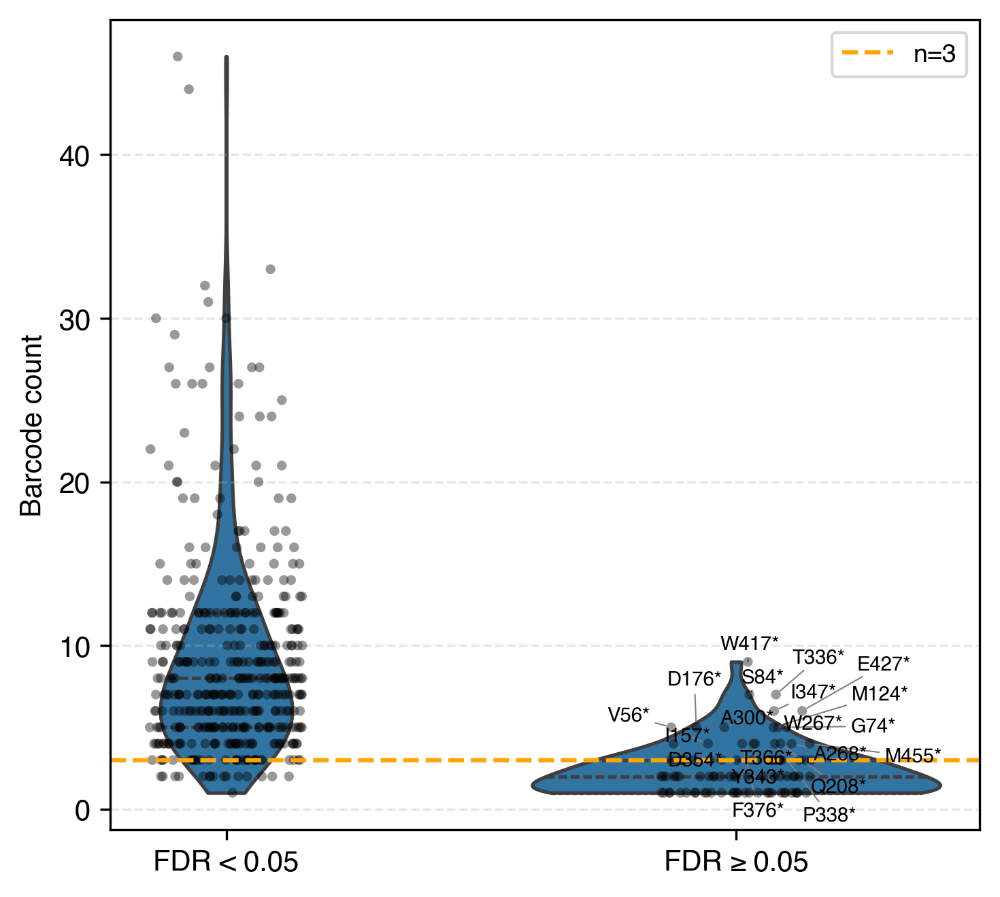

In [93]:
variants_score_dict_no21 = variants_score_dict['gba1_r1'].copy()
variants_score_dict_no21 = variants_score_dict_no21[variants_score_dict_no21['position'] > 21]

stop = variants_score_dict_no21[
    variants_score_dict_no21['aa_substitutions'].str.endswith('*', na=False)
]

stop_sig = stop[stop['FDR'] < 0.05]
stop_nonsig = stop[stop['FDR'] >= 0.05]

print("Significant (FDR<0.05):")
print(stop_sig['barcode_count'].describe())
print("\nNon-significant (FDR>=0.05):")
print(stop_nonsig['barcode_count'].describe())

low_bc_frac = (stop_nonsig['barcode_count'] < 3).mean()
print(f"\n% of non-significant nonsense variants with <3 barcodes: {low_bc_frac*100:.0f}%")

from scipy.stats import mannwhitneyu
stat, p = mannwhitneyu(stop_sig['barcode_count'], stop_nonsig['barcode_count'], alternative='greater')
print(f"Mann-Whitney U (sig > nonsig barcode_count): p = {p:.2e}")

# --- plot ---

stop = stop.copy()
stop['significant'] = np.where(stop['FDR'] < 0.05, 'FDR < 0.05', 'FDR ≥ 0.05')

order = ['FDR < 0.05', 'FDR ≥ 0.05']
x_pos = {cat: i for i, cat in enumerate(order)}

fig, ax = plt.subplots(figsize=(5, 4.5))

sns.violinplot(data=stop, x='significant', y='barcode_count',
                order=order, cut=0, inner='quartile', ax=ax, zorder=1)

# manual jitter, so we know each point's exact plotted coordinates
rng = np.random.default_rng(0)
stop['x_jitter'] = stop['significant'].map(x_pos) + rng.uniform(-0.15, 0.15, size=len(stop))

ax.scatter(stop['x_jitter'], stop['barcode_count'], color='black', alpha=0.4, s=12, zorder=2, edgecolors='none')

ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels(order)
ax.set_xlabel('')
ax.set_ylabel('Barcode count')

# annotate points in the right (non-significant) violin with >=4 barcodes
to_label = stop[(stop['significant'] == 'FDR ≥ 0.05') & (stop['barcode_count'] >= 4)]

texts = [
    ax.text(row['x_jitter'], row['barcode_count'], row['aa_substitutions'], fontsize=7)
    for _, row in to_label.iterrows()
]

adjust_text(
    texts, ax=ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
)
plt.grid(True, alpha=0.3, linestyle='--', axis='y')
plt.axhline(y=3, color='orange', linestyle='--', linewidth=1.5, label='n=3')
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig('FigS_nonsense_barcode_by_FDR_annotated.pdf')
plt.show()

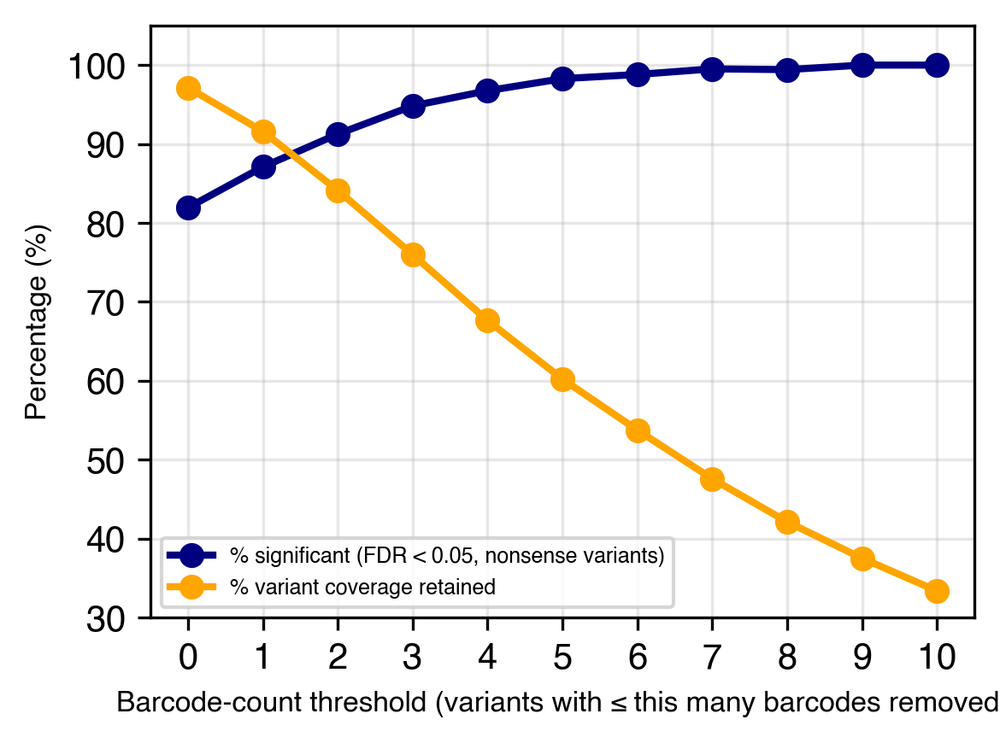

Restricting the analysis to variants with ≥3 barcodes increased the fraction of significant nonsense variants from 81.9% to 91.3%, while reducing the fraction of variants retained from 97.1% to 84.1%.


In [222]:
from matplotlib.ticker import MultipleLocator

TOTAL_EXPECTED = 516 * 20   # 516 positions x 20 possible changes each (19 aa + stop) = 10320
MAX_THRESHOLD = 10

variants_score_dict_no21 = variants_score_dict['gba1_r1'].copy()
variants_score_dict_no21 = variants_score_dict_no21[variants_score_dict_no21['position'] > 21]

stop = variants_score_dict_no21[
    variants_score_dict_no21['aa_substitutions'].str.endswith('*', na=False)
]

thresholds = list(range(0, MAX_THRESHOLD + 1))   # 0 = baseline, nothing removed
pct_sig_list = []
coverage_list = []

for t in thresholds:
    # % significant: still computed on stop-codon variants only
    filtered_stop = stop[stop['barcode_count'] > t]
    pct_sig = (filtered_stop['FDR'] < 0.05).sum() / len(filtered_stop) * 100 if len(filtered_stop) else float('nan')
    pct_sig_list.append(pct_sig)

    # coverage: unique amino-acid changes (ALL types, incl. stop) retained,
    # out of the full expected library of 516 positions x 20 changes
    filtered_all = variants_score_dict_no21[variants_score_dict_no21['barcode_count'] > t]
    n_changes_covered = filtered_all['aa_substitutions'].nunique()
    coverage_list.append((n_changes_covered / TOTAL_EXPECTED) * 100)

fig, ax = plt.subplots(figsize=(4, 3))

ax.plot(thresholds, pct_sig_list, color='navy', marker='o', linewidth=2,
        label='% significant (FDR < 0.05, nonsense variants)')
ax.plot(thresholds, coverage_list, color='orange', marker='o', linewidth=2,
        label='% variant coverage retained')

ax.set_xlabel('Barcode-count threshold (variants with ≤ this many barcodes removed)', fontsize=8)
ax.set_ylabel('Percentage (%)', fontsize=8)
ax.set_xticks(thresholds)
ax.set_xlim(-0.5, MAX_THRESHOLD+0.5)
ax.set_ylim(30, 105)
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.legend(loc='lower left', fontsize=6)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/bc_Count_and_MutCoverage.pdf")
plt.show()

# ≥3 barcodes means removing variants with 0–2 barcodes (threshold t = 2)
baseline_i = thresholds.index(0)
three_bc_i = thresholds.index(2)

print(
    "Restricting the analysis to variants with ≥3 barcodes increased the "
    f"fraction of significant nonsense variants from {pct_sig_list[baseline_i]:.1f}% "
    f"to {pct_sig_list[three_bc_i]:.1f}%, while reducing the fraction of variants "
    f"retained from {coverage_list[baseline_i]:.1f}% to "
    f"{coverage_list[three_bc_i]:.1f}%."
)

## color structure

In [137]:
pdb_file = "input_files/2NSX.pdb"
for record in SeqIO.parse(pdb_file, "pdb-atom"):
    print("chain: " + record.id.split(":")[1])
    print(record.seq)
    
    
def pdb_to_csv(pdb):
    df_pdb = pd.DataFrame(columns=["id", "atom_no", "atom", "res", "chain", "res_no",
                               "x", "y", "z", "factor_a", "bfactor", "atom_center"])
    with open(pdb) as pdbfile:
        i = 0
        for line in pdbfile:
            if line[:4] == 'ATOM' or line[:6] == "HETATM":
                splitted_line = [line[:6], line[6:11], line[12:16], line[17:20], line[21], line[22:26],
                             line[30:38], line[38:46], line[46:54], line[54:60], line[60:66], line[66:78]]
                df_pdb.loc[i] = splitted_line
                i += 1
    df_id = df_pdb["id"].str.strip()
    df_atom_no = df_pdb["atom_no"].str.strip()
    df_atom = df_pdb["atom"].str.strip()
    df_res = df_pdb["res"].str.strip()
    df_chain = df_pdb["chain"].str.strip()
    df_res_no = df_pdb["res_no"].str.strip()
    df_res_no = df_res_no.astype(int)
    df_x = df_pdb["x"].str.strip()
    df_y = df_pdb["y"].str.strip()
    df_z = df_pdb["z"].str.strip()
    df_factor_a = df_pdb["factor_a"].str.strip()
    df_bfactor = df_pdb["bfactor"].str.strip()
    df_bfactor = df_bfactor.astype(float)
    df_atom_center = df_pdb["atom_center"].str.strip()
    df = pd.concat([df_id, df_atom_no, df_atom, df_res, df_chain, df_res_no,
                   df_x, df_y, df_z, df_factor_a, df_bfactor, df_atom_center], axis = 1)
    return df  

def domain_partitioner(df_csv):
    Selected_columns=["id", "atom_no", "atom", "res", "chain", "res_no","x", "y", "z", "factor_a", "bfactor", "atom_center"]
    df_A = pd.DataFrame(columns=Selected_columns)
    df_C = pd.DataFrame(columns=Selected_columns)
    df_D = pd.DataFrame(columns=Selected_columns)
    df_E = pd.DataFrame(columns=Selected_columns)
    df_F = pd.DataFrame(columns=Selected_columns)
    df_G = pd.DataFrame(columns=Selected_columns)
    
    
    
    ix = 0
    for c in range(len(df_csv["id"])):
        #domain A
        if df_csv["chain"][c]=="A":
            df_A.loc[ix] = df_csv.iloc[c]  
        #domain C
        elif df_csv["chain"][c]=="C":
            df_C.loc[ix] = df_csv.iloc[c]  
        #domain D
        elif df_csv["chain"][c]=="D":
            df_D.loc[ix] = df_csv.iloc[c] 
        #domain E
        elif df_csv["chain"][c]=="E":
            df_E.loc[ix] = df_csv.iloc[c]
        #domain A
        elif df_csv["chain"][c]=="F":
            df_F.loc[ix] = df_csv.iloc[c]
        elif df_csv["chain"][c]=="G":
            df_G.loc[ix] = df_csv.iloc[c]
        
  
            
        ix = ix+1  
    return df_A, df_C, df_D, df_E, df_F, df_G

def bfactor_overwriter_6PXV(pdb, data):
    df_csv = pdb_to_csv(pdb)
    
   
    df_csv['res_no'] = df_csv.apply(lambda row:  row['res_no']+39, axis=1)
   
    
    result_df = df_csv.copy()
    #==============================
    
    a, c, d, e,f,g = domain_partitioner(result_df)

 
    #this is to adjust residue numbering in pdb file
    df_data = data
    df_a = a.merge(df_data, left_on = "res_no", right_on = "position")
    df_c = c.merge(df_data, left_on = "res_no", right_on = "position")


    df_a = df_a[["id", "atom_no", "atom", "res", "chain", "res_no","x", "y", "z", "factor_a", "median_score", "atom_center"]]
    df_c = df_c[["id", "atom_no", "atom", "res", "chain", "res_no","x", "y", "z", "factor_a", "median_score", "atom_center"]]

    
    df_d=d.rename({'bfactor':'median_score'}, axis=1)
    df_e=e.rename({'bfactor':'median_score'}, axis=1)
    df_f=f.rename({'bfactor':'median_score'}, axis=1)
    df_g=g.rename({'bfactor':'median_score'}, axis=1)
    
 

    df = pd.concat([df_a, df_c, df_d, df_e, df_f, df_g], axis = 0)
    
    print("Process completed")
    return df



##############################################
df_exp = variantsScore_melt['gba1_r1']


df_exp = df_exp[['position','median_score']]

df_end=bfactor_overwriter_6PXV(pdb = pdb_file, data = df_exp)


df_end.to_csv('results/PDB/2NSX.csv', index=False, header=False)

df_end['res_no']=df_end['res_no']-39
df_end.to_csv('results/PDB/2NSX_correctedResNo.csv', index=False, header=False)


# define the AWK command
!awk 'BEGIN{OFS=FS=","}{$7=sprintf("%.3f",$7)}1{$8=sprintf("%.3f",$8)}1{$9=sprintf("%.3f",$9)}1' results/PDB/2NSX.csv | awk 'BEGIN {FS =","; OFS=""} { if(length($3) == 4 ) {pad = sprintf("%s", " ")} else {pad = sprintf("%2s", " ")} } { if(length($3) == 4 ) {pad2 = sprintf("%s", " ")} else {pad2 = sprintf("%s", "")} } {printf "%-6s%5s%s%-4s%s%3s%2s%4s%12s%8s%8s%6s%6s%12s\n", $1, $2, pad, $3, pad2, $4, $5, $6, $7, $8, $9, $10, $11, $12}' > results/PDB/2NSX.pdb
!awk 'BEGIN{OFS=FS=","}{$7=sprintf("%.3f",$7)}1{$8=sprintf("%.3f",$8)}1{$9=sprintf("%.3f",$9)}1' results/PDB/2NSX_correctedResNo.csv | awk 'BEGIN {FS =","; OFS=""} { if(length($3) == 4 ) {pad = sprintf("%s", " ")} else {pad = sprintf("%2s", " ")} } { if(length($3) == 4 ) {pad2 = sprintf("%s", " ")} else {pad2 = sprintf("%s", "")} } {printf "%-6s%5s%s%-4s%s%3s%2s%4s%12s%8s%8s%6s%6s%12s\n", $1, $2, pad, $3, pad2, $4, $5, $6, $7, $8, $9, $10, $11, $12}' > results/PDB/2NSX_correctedResNo.pdb



chain: A
ARPCIPKSFGYSSVVCVCNATYCDSFDPPTFPALGTFSRYESTRSGRRMELSMGPIQANHTGTGLLLTLQPEQKFQKVKGFGGAMTDAAALNILALSPPAQNLLLKSYFSEEGIGYNIIRVPMASCDFSIRTYTYADTPDDFQLHNFSLPEEDTKLKIPLIHRALQLAQRPVSLLASPWTSPTWLKTNGAVNGKGSLKGQPGDIYHQTWARYFVKFLDAYAEHKLQFWAVTAENEPSAGLLSGYPFQCLGFTPEHQRDFIARDLGPTLANSTHHNVRLLMLDDQRLLLPHWAKVVLTDPEAAKYVHGIAVHWYLDFLAPAKATLGETHRLFPNTMLFASEACVGSKFWEQSVRLGSWDRGMQYSHSIITNLLYHVVGWTDWNLALNPEGGPNWVRNFVDSPIIVDITKDTFYKQPMFYHLGHFSKFIPEGSQRVGLVASQKNDLDAVALMHPDGSAVVVVLNRSSKDVPLTIKDPAVGFLETISPGYSIHTYLWHRQ
Process completed


In [ ]:
dom1=[40-66, 422-453]
dom2=[69-114, 470-536]
signal_peptide=[1-39]
som3=[115-420,455-469]

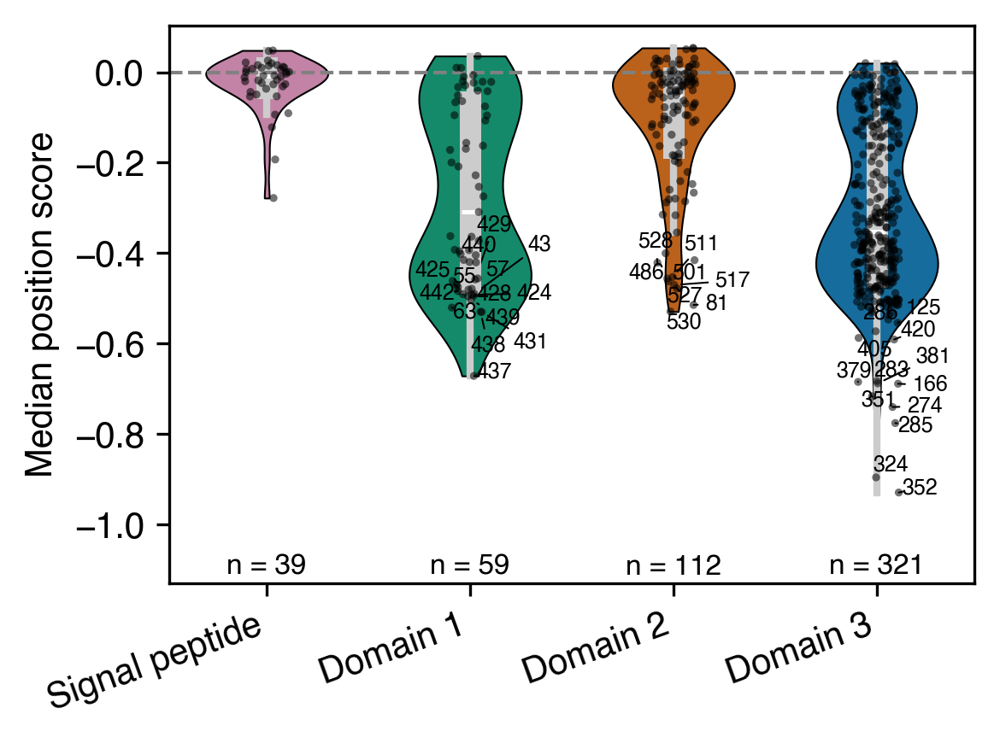

In [257]:
import numpy as np

region_colors = {
    'Signal peptide': '#CC79A7',
    'Domain 2':       '#D55E00',
    'Domain 1':       '#009E73',
    'Domain 3':       '#0072B2',
}

rng = np.random.default_rng(0)  # fixed seed = reproducible jitter
jitter_width = 0.22

plot_df = plot_df.copy()
plot_df['x_base'] = plot_df['region'].map(lambda r: region_order.index(r))
plot_df['x_jitter'] = plot_df['x_base'] + rng.uniform(-jitter_width / 2, jitter_width / 2, size=len(plot_df))

plt.figure(figsize=(4, 3))

sns.violinplot(
    data=plot_df,
    x='region',
    y='median_score',
    order=region_order,
    palette=region_colors,
    width=0.6,
    inner='box',
    inner_kws=dict(box_width=6, whis_width=2, color='0.8'),
    linecolor='black',
    linewidth=0.5,
    cut=0
)

# manual "stripplot" using the jitter we control
plt.scatter(
    plot_df['x_jitter'], plot_df['median_score'],
    color='black', alpha=0.55, s=5, zorder=3,
    edgecolors='none'
)

annotation_thresholds = {
    'Domain 1': -0.47,
    'Domain 2': -0.42,
    'Domain 3': -0.55,
}

texts = []
for _, row in plot_df.iterrows():
    threshold = annotation_thresholds.get(row['region'])
    if threshold is not None and row['median_score'] < threshold:
        text = plt.text(
            row['x_jitter'], row['median_score'],
            str(int(row['position'])),
            fontsize=6, color='k'
        )
        texts.append(text)

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='k', lw=0.5)
)

plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.xlabel('')
plt.ylabel('Median position score')
plt.xticks(rotation=20, ha='right')

counts = plot_df.groupby('region')['median_score'].count().reindex(region_order)
ax = plt.gca()
y_min, y_max = ax.get_ylim()
label_y = y_min - 0.08 * (y_max - y_min)
for i, n in enumerate(counts):
    ax.text(i, label_y, f'n = {n}', ha='center', va='top', fontsize=8)
plt.ylim(label_y - 0.06 * (y_max - y_min), y_max)

plt.tight_layout()
plt.show()

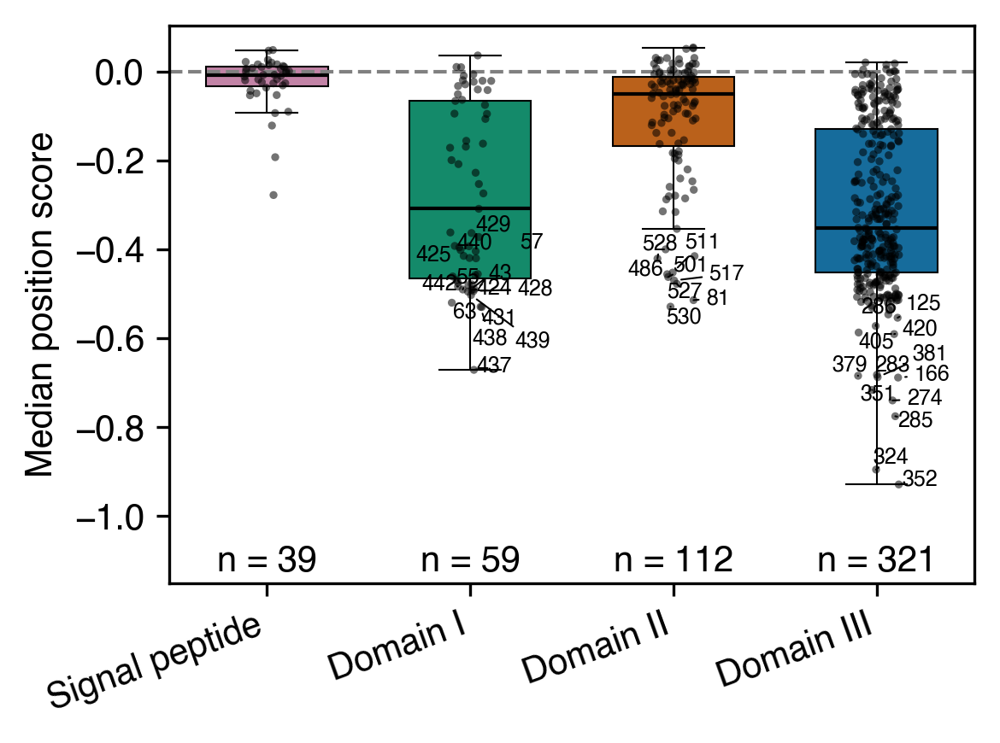

In [274]:
import numpy as np

region_colors = {
    'Signal peptide': '#CC79A7',
    'Domain II':       '#D55E00',
    'Domain I':       '#009E73',
    'Domain III':       '#0072B2',
}

rng = np.random.default_rng(0)  # fixed seed = reproducible jitter
jitter_width = 0.22

plot_df = plot_df.copy()
plot_df['region'] = plot_df['region'].replace({
    'Domain 1': 'Domain I',
    'Domain 2': 'Domain II',
    'Domain 3': 'Domain III',
})

region_order = ['Signal peptide', 'Domain I', 'Domain II', 'Domain III']

plot_df['x_base'] = plot_df['region'].map(lambda r: region_order.index(r))
plot_df['x_jitter'] = plot_df['x_base'] + rng.uniform(
    -jitter_width / 2,
    jitter_width / 2,
    size=len(plot_df)
)
plt.figure(figsize=(4, 3))

sns.boxplot(
    data=plot_df,
    x='region',
    y='median_score',
    order=region_order,
    palette=region_colors,
    width=0.6,
    linewidth=0.5,
    fliersize=0,  # outliers are already shown by the manual jittered scatter below
    boxprops=dict(edgecolor='black'),
    medianprops=dict(color='black', linewidth=1),
    whiskerprops=dict(color='black', linewidth=0.5),
    capprops=dict(color='black', linewidth=0.5),
)

# manual "stripplot" using the jitter we control
plt.scatter(
    plot_df['x_jitter'], plot_df['median_score'],
    color='black', alpha=0.55, s=5, zorder=3,
    edgecolors='none'
)

annotation_thresholds = {
    'Domain I': -0.47,
    'Domain II': -0.42,
    'Domain III': -0.55,
}

texts = []
for _, row in plot_df.iterrows():
    threshold = annotation_thresholds.get(row['region'])
    if threshold is not None and row['median_score'] < threshold:
        text = plt.text(
            row['x_jitter'], row['median_score'],
            str(int(row['position'])),
            fontsize=6, color='k'
        )
        texts.append(text)

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='k', lw=0.5)
)

plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.xlabel('')
plt.ylabel('Median position score')
plt.xticks(rotation=20, ha='right')

#this section add pvalues to the plot
''' 
# Two-sided Mann–Whitney U tests and comparison brackets
comparisons = [
    ('Signal peptide', 'Domain I'),
    ('Signal peptide', 'Domain II'),
    ('Signal peptide', 'Domain III'),
    ('Domain I', 'Domain II'),
    ('Domain II', 'Domain III'),
]

ax = plt.gca()
_, current_ymax = ax.get_ylim()
y_range = current_ymax - ax.get_ylim()[0]

bracket_step = 0.075 * y_range
bracket_height = 0.018 * y_range
first_bracket_y = current_ymax + 0.04 * y_range

for level, (group1, group2) in enumerate(comparisons):
    values1 = plot_df.loc[plot_df['region'] == group1, 'median_score'].dropna()
    values2 = plot_df.loc[plot_df['region'] == group2, 'median_score'].dropna()

    stat, p_value = mannwhitneyu(
        values1,
        values2,
        alternative='two-sided'
    )

    x1 = region_order.index(group1)
    x2 = region_order.index(group2)
    y = first_bracket_y + level * bracket_step

    # Bracket line
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + bracket_height, y + bracket_height, y],
        color='black',
        linewidth=0.8,
        clip_on=False
    )

    # Display exact p-value
    p_label = f'p = {p_value:.2g}'
    ax.text(
        (x1 + x2) / 2,
        y + bracket_height,
        p_label,
        ha='center',
        va='bottom',
        fontsize=6,
        clip_on=False
    )

# Leave space above plot for all six comparisons
ax.set_ylim(top=first_bracket_y + len(comparisons) * bracket_step + 0.06 * y_range)
'''

counts = plot_df.groupby('region')['median_score'].count().reindex(region_order)
ax = plt.gca()
y_min, y_max = ax.get_ylim()
label_y = y_min - 0.08 * (y_max - y_min)
for i, n in enumerate(counts):
    ax.text(i, label_y, f'n = {n}', ha='center', va='top', fontsize=10)
plt.ylim(label_y - 0.08 * (y_max - y_min), y_max)

plt.savefig("results/figures/median_score_by_region_boxplot.pdf", bbox_inches='tight', dpi=300)

plt.tight_layout()
plt.show()

# plot domains
## residues from 1 to 269

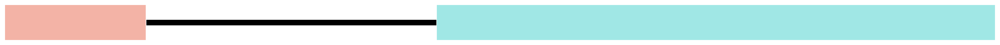

In [95]:
import matplotlib.pyplot as plt

# define box coordinates (x, y, width, height, color)
boxes = [
    (0, 0, 39, 1, '#F3B3A6'),   # 1 -> rectangle
    (40, 0, 77, 1, 'w'),        # 2 -> line
    (118, 0, 328, 1, '#A0E7E5'),# 3 -> rectangle
    (446, 0, 24, 1, '#DACF6D'), # 4 -> line
    (470, 0, 61, 1, '#FBE7C6'), # 5 -> rectangle
    (532, 0, 4, 1, '#61BDD2')   # 6 -> line
]

box_names = ['', '', '', '', '', '']

# create figure and axis for residues 1-269
fig, ax = plt.subplots(figsize=(20, 1))

# add rectangles and lines
for i, (box, name) in enumerate(zip(boxes, box_names), start=1):
    x, y, w, h, color = box
    if i in [1, 3, 5]:
        # draw filled rectangle
        rect = plt.Rectangle((x, y), w, h, color=color)
        ax.add_patch(rect)
    else:
        # draw black horizontal line
        ax.plot([x, x + w], [y + h/2, y + h/2], color='black', linewidth=8)

    # add label if exists
    if name:
        text_x = x + w / 2
        text_y = y + h / 2
        ax.text(text_x, text_y, name, va='center', ha='center',
                color='black', fontsize=48, weight='bold')

# axis styling for first part
ax.set_xlim(1, 269)
ax.set_ylim(0, 1)
ax.axis('off')

plt.tight_layout()
plt.savefig("results/figures/GBA1_domains_part1.pdf", bbox_inches='tight')
plt.show()

## residues from 270 to the end

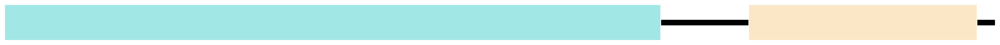

In [96]:
import matplotlib.pyplot as plt

# define box coordinates (x, y, width, height, color)
boxes = [
    (1, 0, 39, 1, '#F3B3A6'),   # 1 -> rectangle
    (40, 0, 78, 1, 'w'),        # 2 -> line
    (118, 0, 328, 1, '#A0E7E5'),# 3 -> rectangle
    (447, 0, 22, 1, '#DACF6D'), # 4 -> line
    (470, 0, 61, 1, '#FBE7C6'), # 5 -> rectangle
    (532, 0, 4, 1, '#61BDD2')   # 6 -> line
]

box_names = ['', '', '', '', '', '']

# create figure and axis for residues 270-end
fig, ax = plt.subplots(figsize=(20, 1))

# add rectangles and lines
for i, (box, name) in enumerate(zip(boxes, box_names), start=1):
    x, y, w, h, color = box
    if i in [1, 3, 5]:
        # draw filled rectangle
        rect = plt.Rectangle((x, y), w, h, color=color)
        ax.add_patch(rect)
    else:
        # draw black horizontal line
        ax.plot([x, x + w], [y + h/2, y + h/2], color='black', linewidth=8)

    # add label if exists
    if name:
        text_x = x + w / 2
        text_y = y + h / 2
        ax.text(text_x, text_y, name, va='center', ha='center',
                color='black', fontsize=48, weight='bold')

# axis styling for second part
ax.set_xlim(270, 536)
ax.set_ylim(0, 1)
ax.axis('off')

plt.tight_layout()
plt.savefig("results/figures/GBA1_domains_part2.pdf", bbox_inches='tight')
plt.show()

# plot median scores across the protein sequence







In [97]:
df = variantsScore_melt[library]

vmin=-0.5
vmax=0.4

fig, ax = plt.subplots(figsize=(80, 2))

# Plot the heatmap (mean score per position)
heatmap_data = df[['position', 'median_score']].pivot_table(index='position', values='median_score')
heatmap_data = heatmap_data.reset_index(drop=True)

# Filter data for positions 0-269
heatmap_data_part1 = heatmap_data.iloc[0:269]

# Create a heatmap with the data
sns.heatmap(heatmap_data_part1.T, cmap='RdBu_r', ax=ax, vmin=vmin, vmax=vmax, cbar=False)

# Remove all ticks and labels
ax.tick_params(top=False, bottom=False, left=False, right=False,
               labeltop=False, labelbottom=False, labelleft=False, labelright=False)

# Remove y-axis label
ax.set_ylabel('')

# Set x-axis limits to show only positions 0-269
ax.set_xlim(0, 270)

# Save the figure to a file
plt.tight_layout()
fig.savefig(f"results/figures/GBA1_meanScore_part1_0-269.pdf", dpi=600)
plt.show()
df = variantsScore_melt[library]

vmin=-0.5
vmax=0.4

fig, ax = plt.subplots(figsize=(80, 2))

# Plot the heatmap (mean score per position)
heatmap_data = df[['position', 'median_score']].pivot_table(index='position', values='median_score')
heatmap_data = heatmap_data.reset_index(drop=True)

# Filter data for positions 270 to end
heatmap_data_part2 = heatmap_data.iloc[269:]

# Create a heatmap with the data
sns.heatmap(heatmap_data_part2.T, cmap='RdBu_r', ax=ax, vmin=vmin, vmax=vmax, cbar=False)

# Remove all ticks and labels
ax.tick_params(top=False, bottom=False, left=False, right=False,
               labeltop=False, labelbottom=False, labelleft=False, labelright=False)

# Remove y-axis label
ax.set_ylabel('')

# Save the figure to a file
plt.tight_layout()
fig.savefig(f"results/figures/GBA1_meanScore_part2_270-end.pdf", dpi=600)
plt.show()

In [100]:
# Step 1: Count barcodes per amino acid substitution
variant_counts = df_bcScore_data.groupby('aa_substitutions').size()

# Step 2: Reference variant scores DataFrame
var_scores = variants_score_dict['gba1_r1']

# Step 3: Loop through all variants and collect results
results = []

for variant in variant_counts.index:
    count = variant_counts[variant]

    try:
        var_fdr = var_scores[var_scores['aa_substitutions'] == variant]['FDR'].values[0]
        score = var_scores[var_scores['aa_substitutions'] == variant]['variant_score'].values[0]
    except IndexError:
        var_fdr = float('nan')
        score = float('nan')

    var_fdr_ther = ''
    if pd.notna(var_fdr) and var_fdr > 0.05:
        var_fdr_ther = "no difference from WT"

    results.append({
        'aa_substitutions': variant,
        'barcode_count': count,
        'FDRvalue': var_fdr,
        'variant_score': score,
        'FDR_interpretation': var_fdr_ther
    })

# Step 4: Save to CSV
results_df = pd.DataFrame(results)
results_df.to_csv("GBA1_variants_withBCcount_FDRvalues.csv", index=False)
print("Saved to GBA1_variants_withBCcount_FDRvalues.csv")

Saved to GBA1_variants_withBCcount_FDRvalues.csv


Columns in variants_score_dict['gba1_r1'] DataFrame:
['aa_substitutions', 'variant_score', 'FDR', 'barcode_count', 'confidence', 'wt_aa', 'position', 'variant_aa']


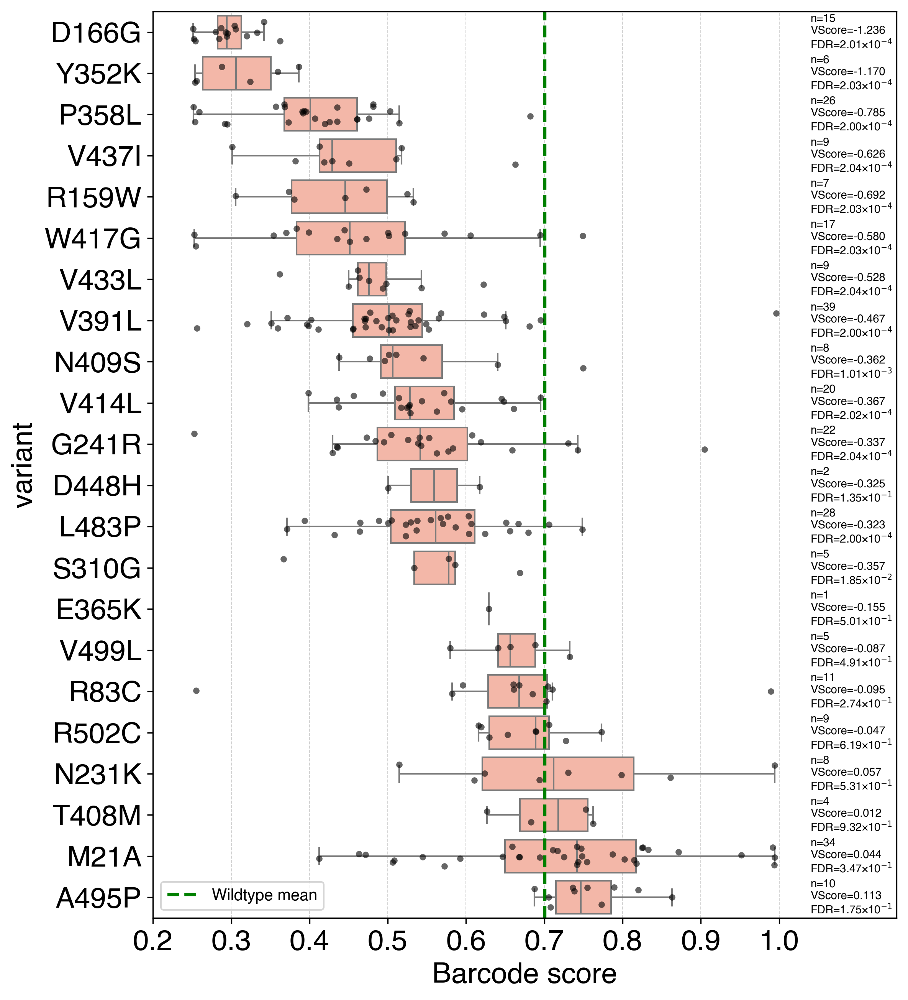

In [138]:
# --- Setup: Selected variants ---
selected_variants = [
    "R159W", "G241R", "V414L", "V433L", "D448H", "L483P", "R502C", "S310G",
    "N409S", "W417G", "V437I", "V499L", "E365K", "R83C", "N231K", "R342H",
    "P358L", "V391L", "T408M", "A495P", "M1A", "M21A", "D166G", "Y352K",
]


# --- Step 1: Filter data to selected variants ---
bc_score = df_bcScore_data.copy()
sel_vars = bc_score[bc_score['aa_substitutions'].isin(selected_variants)].copy()

# --- Step 2: Order by median score ---
order = (
    sel_vars
    .groupby('aa_substitutions')['gba1_r1 Gcase flowSeq']
    .median()
    .sort_values()
    .index
)

# --- Step 3: Counts per variant ---
counts = sel_vars['aa_substitutions'].value_counts()

# --- Step 4: Pull variant scores and FDR from variants_score_dict['gba1_r1'] ---
print("Columns in variants_score_dict['gba1_r1'] DataFrame:")
print(variants_score_dict['gba1_r1'].columns.tolist())

var_scores_df = variants_score_dict['gba1_r1']
variant_info = var_scores_df[var_scores_df['aa_substitutions'].isin(selected_variants)]

variant_scores = dict(zip(variant_info['aa_substitutions'], variant_info['variant_score']))  # confirm this column name
fdr_values = dict(zip(variant_info['aa_substitutions'], variant_info['FDR']))  # matches your working code1

for aa in order:
    if aa not in variant_scores:
        print(f"Warning: {aa} not found in variants_score_dict['gba1_r1'] DataFrame")
        variant_scores[aa] = np.nan
    if aa not in fdr_values:
        fdr_values[aa] = np.nan

# --- Step 5: Plot ---
plt.figure(figsize=(8, max(5, len(order) * 0.4)))

ax = sns.boxplot(
    data=sel_vars,
    y='aa_substitutions',
    x='gba1_r1 Gcase flowSeq',
    order=order,
    showfliers=False,
    color='#ffb09c'
)

sns.stripplot(
    data=sel_vars,
    y='aa_substitutions',
    x='gba1_r1 Gcase flowSeq',
    order=order,
    color='black',
    size=4,
    jitter=0.25,
    alpha=0.6
)

def format_fdr_scientific(fdr_value):
    """Format FDR value in scientific notation like 2.03×10^-3"""
    if pd.isna(fdr_value):
        return "N/A"
    elif fdr_value == 0:
        return "0"
    else:
        sci_str = f"{fdr_value:.2e}"
        coeff, exp = sci_str.split('e')
        coeff = float(coeff)
        exp = int(exp)
        return f"{coeff:.2f}×10$^{{{exp}}}$"

for i, aa in enumerate(order):
    n = counts[aa]
    vs = variant_scores.get(aa, np.nan)
    fdr = fdr_values.get(aa, np.nan)

    if pd.isna(vs) or pd.isna(fdr):
        annotation = f'n={n}\nVscore=N/A\nFDR=N/A'
    else:
        fdr_formatted = format_fdr_scientific(fdr)
        annotation = f'n={n}\nVScore={vs:.3f}\nFDR={fdr_formatted}'

    ax.text(
        x=1.04,
        y=i,
        s=annotation,
        va='center',
        ha='left',
        fontsize=7,
        linespacing=1.2
    )

plt.axvline(
    x=bc_score[bc_score['variant_class'] == 'wildtype']['gba1_r1 Gcase flowSeq'].mean(),
    color='green',
    linestyle='--',
    linewidth=2,
    label='Wildtype mean'
)

plt.legend(loc='lower left')
plt.xlim(0.22, 1.15)  # check this fits your gba1_r1 score range4,

plt.grid(True, color='lightgrey', linewidth=0.5, linestyle='--', axis='x')

plt.xlabel('Barcode score', fontsize=18)
plt.ylabel('variant', fontsize=18)
plt.xticks(np.arange(0.2, 1.01, 0.1), size=18)
plt.xticks(size=18)
plt.yticks(size=18)

plt.tight_layout()
plt.savefig('results/figures/misc/selected_vars_boxplot_gba1_r1.pdf')
plt.show()

sel_vars_export = sel_vars[['barcode', 'codon_substitutions', 'aa_substitutions', 'gba1_r1 Gcase flowSeq']]
sel_vars_export.to_csv('results/FigS_selected_variants.csv', index=False)

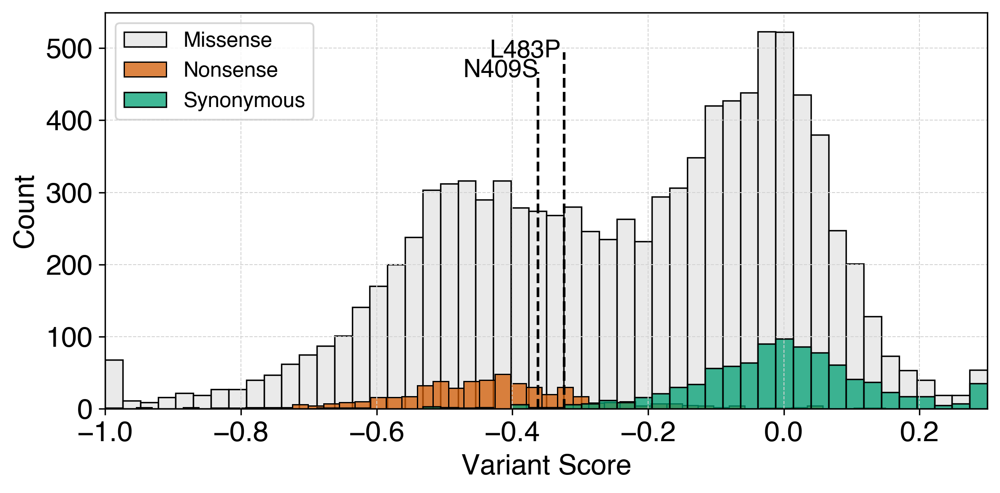

In [ ]:
df_plot=variants_score_dict['gba1_r1'].copy()

# Filter selected variants (make sure formatting matches your df)
variants_of_interest = ['N409S','L483P']  # <-- remove "p." if not in df
selected_variants = df_plot[df_plot['aa_substitutions'].isin(variants_of_interest)].copy()
selected_variants.rename(columns={'gba1_r1': 'variant_score'}, inplace=True)

plt.figure(figsize=(8,4))

# Clip variant scores correctly
df_plot_clipped = df_plot.copy()
df_plot_clipped['variant_score'] = df_plot_clipped['variant_score'].clip(lower=-1, upper=0.3)

syn_score_clipped = syn_score.copy()
syn_score_clipped['variant_score'] = syn_score_clipped['gba1_r1'].clip(lower=-1, upper=0.3)

# Histograms
sns.histplot(df_plot_clipped.loc[~df_plot_clipped['aa_substitutions'].str.endswith('*'), 'variant_score'],
             bins=50, color='#e4e4e4', label='Missense', alpha=0.75)

sns.histplot(df_plot_clipped.loc[df_plot_clipped['aa_substitutions'].str.endswith('*'), 'variant_score'],
             bins=50, color='#d25b03', label='Nonsense', alpha=0.75)

sns.histplot(syn_score_clipped['variant_score'], bins=50, color='#00a073',
             label='Synonymous', alpha=0.75)

# Overlay vertical lines for specific variants
y_max = plt.ylim()[1]
y_positions = [0.9, 0.85, 0.8, 0.75]

for i, (_, row) in enumerate(selected_variants.iterrows()):
    x_score = max(row['variant_score'], -1)  
    plt.vlines(x=x_score, ymin=0, ymax=y_positions[i]*y_max, 
               color='black', linestyle='--', linewidth=1.5)
    plt.text(x_score - 0.11, y_positions[i]*y_max*0.97,  
             row['aa_substitutions'], va='bottom', ha='left', fontsize=14)

plt.xlabel('Variant Score', fontsize=16)
plt.ylabel('Count', fontsize=16)
plt.xticks(size=16)
plt.yticks(size=16)
plt.legend(fontsize=12)
plt.grid(True, color='lightgrey', linewidth=0.5, linestyle='--')
plt.xlim(-1, 0.3)
plt.savefig('results/figures/misc/variant_score_distribution.pdf', bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

In [ ]:
HGVS_df = pd.read_csv('input_files/processed_variants_retry_network_errors.csv')

HGVS_df = HGVS_df[
    HGVS_df['barcode'].isin(list(barcode_scored['gba1_r1']['barcode']))
].reset_index(drop=True)


# -----------------------------
# Load data
# -----------------------------
HGVS_df = HGVS_df.copy()  # safety if this is a slice

# -----------------------------
# Helper cleaning + aggregation functions
# -----------------------------
def clean_series(series):
    """Remove NaN and empty strings."""
    return series.replace('', pd.NA).dropna()

def safe_mode(series):
    """Return most frequent value or <NA> if empty."""
    s = clean_series(series)
    if s.empty:
        return pd.NA
    return s.value_counts().idxmax()

def safe_counts(series):
    """Return value:count dict, empty dict if no values."""
    s = clean_series(series)
    if s.empty:
        return {}
    return dict(Counter(s))

# -----------------------------
# Groupby aggregation
# -----------------------------
HGVS_df = (
    HGVS_df
    .groupby('aa_substitutions')
    .agg(
        hgvs_genome_mode=(
            'hgvs_genome',
            safe_mode
        ),
        hgvs_transcript_mode=(
            'hgvs_transcript',
            safe_mode
        ),
        hgvs_genome_counts=(
            'hgvs_genome',
            safe_counts
        ),
        hgvs_transcript_counts=(
            'hgvs_transcript',
            safe_counts
        )
    )
    .reset_index()
)

# -----------------------------
# Inspect result
# -----------------------------

# add VEP annotations and save final df to share
VEP = pd.read_csv('input_files/P04062_VEP_BenLivesey_Dec2025.csv')
VEP.rename(columns={'variant': 'aa_substitutions'}, inplace=True)
# lots of Nan values in 'MutationAssessor', 'AFFIPred' so dropping for now
VEP.drop(['MutationAssessor', 'AFFIPred'], axis=1, inplace=True)

HGVS_df_=HGVS_df.copy()
temp_df=variants_score_dict['gba1_r1'].copy()
# Group bc_score by aa_substitutions and count
barcode_counts = bc_score.groupby('aa_substitutions').size().reset_index(name='barcode_count')
# Merge with temp_df
temp_df = temp_df.merge(barcode_counts, on='aa_substitutions', how='left')

temp_df=temp_df.merge(HGVS_df_, on='aa_substitutions', how='left')
temp_df.drop(['wt_aa', 'position', 'variant_aa'], axis=1, inplace=True)
temp_df.merge(VEP, how='left', on='aa_substitutions')
temp_df=temp_df.merge(VEP, how='left', on='aa_substitutions')
temp_df['aa_substitutions']=temp_df['aa_substitutions'].apply(one_to_three_mut)
temp_df.rename(columns={'aa_substitutions': 'HGVS_protein'}, inplace=True)
temp_df.to_csv('results/GBA1_HGVS_df.csv', index=False)

temp_df


KeyboardInterrupt: 

In [ ]:
bc_score

,barcode,aa_substitutions,codon_substitutions,gba1_r1
0,TAAGTCGCTGCGCGGATGTCGTTTTTTTTT,wildtype,,0.644729
1,TTGTTTAGCTGTCAACCCCCCGTTTTTTTT,wildtype,,0.675546
2,AACGTTCAGCACCTACAGGGATGTTTTTTT,A175R,GCA175AGG,0.659218
3,TCTATCGAACCGATGACAGACTTGTTTTTT,D63S,GAC63TCT,0.655001
4,AACCTGTAATGGTGTTTTGCATTGTTTTTT,S19F,AGC19TTT,0.744301
...,...,...,...,...
163637,AGGCGGAGTGATGGTAAAATCCGAAAAAAA,S84K,AGT84AAG,0.604353
163638,TGAGTTGGGATAGCGCTGTTCTCAAAAAAA,wildtype,,0.807947
163639,GGGATAGATAGTAGAAGCACTTAAAAAAAA,wildtype,,0.476397
163640,AGGGCTGGTTTTATTACGAGACAAAAAAAA,G103R,GGC103AGG,0.698222


In [ ]:
yt=variants_score_dict['gba1_r1']

# Bin into 5 bins with equal counts, labeled 1–5
yt['bin_number'] = pd.qcut(yt['variant_score'], q=5, labels=[1, 2, 3, 4, 5])

# Optional: print the bin edges
bin_edges = pd.qcut(yt['variant_score'], q=5).cat.categories
print("Bin edges (equal-count bins):")
print(bin_edges)

# Save to CSV
yt.to_csv("binned_results.csv", index=False)

print("\nSaved to binned_results.csv ✅")
print(yt)



Bin edges (equal-count bins):
IntervalIndex([ (-1.466, -0.485],  (-0.485, -0.321],   (-0.321, -0.13],
               (-0.13, -0.00689],  (-0.00689, 0.51]],
              dtype='interval[float64, right]')

Saved to binned_results.csv ✅
      aa_substitutions  variant_score FDRvalues wt_aa  position variant_aa  \
0                *537A       0.000640  0.978313     *       537          A   
1                *537C      -0.069523  0.608776     *       537          C   
2                *537D      -0.375972  0.199108     *       537          D   
3                *537F      -0.101721    0.4726     *       537          F   
4                *537G      -0.028951  0.716924     *       537          G   
...                ...            ...       ...   ...       ...        ...   
10420             Y79R      -0.319634  0.000201     Y        79          R   
10421             Y79S      -0.251390  0.000202     Y        79          S   
10422             Y79T      -0.131260   0.06729     Y        79

# MDSgne variants analysis

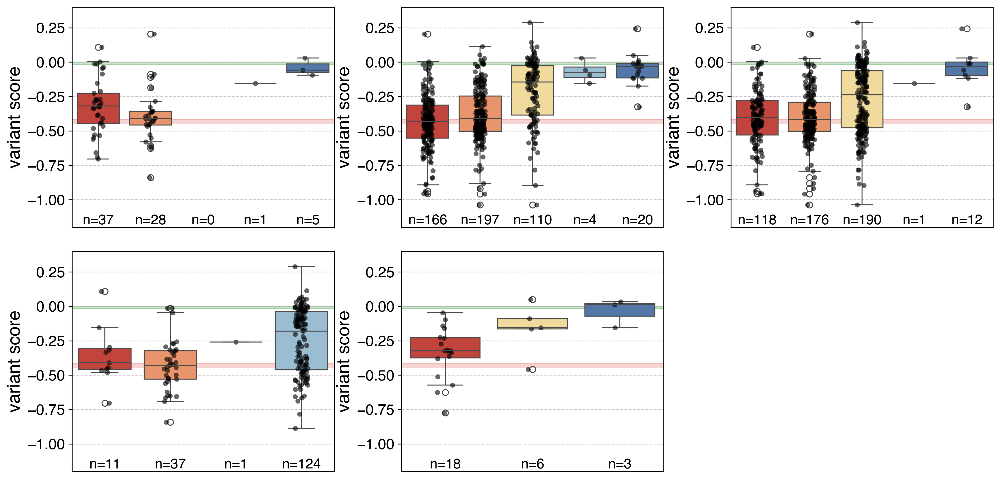

In [ ]:
# Mapping 3-letter to 1-letter amino acids
aa3_to_1 = {
    'Ala': 'A', 'Arg': 'R', 'Asn': 'N', 'Asp': 'D',
    'Cys': 'C', 'Gln': 'Q', 'Glu': 'E', 'Gly': 'G',
    'His': 'H', 'Ile': 'I', 'Leu': 'L', 'Lys': 'K',
    'Met': 'M', 'Phe': 'F', 'Pro': 'P', 'Ser': 'S',
    'Thr': 'T', 'Trp': 'W', 'Tyr': 'Y', 'Val': 'V'
}

import re

def aa_sub_to_short(s):
    if not isinstance(s, str):
        return None  # skip non-string entries (e.g., NaN)
    
    match = re.match(r'p\.([A-Z][a-z]{2})(\d+)([A-Z][a-z]{2}|\*)$', s)
    if match:
        ref, pos, alt = match.groups()
        if ref in aa3_to_1:
            alt_letter = '*' if alt == '*' else aa3_to_1.get(alt)
            if alt_letter:
                return f"{aa3_to_1[ref]}{pos}{alt_letter}"
    return None  # Non-standard or unmatched variant

stop_codons = var_scores[var_scores['aa_substitutions'].str.endswith('*', na=False)]

# Extract the scores
scores = stop_codons['variant_score'].dropna()

# Compute mean and 95% confidence interval
mean = scores.mean()
sem = stats.sem(scores)  # standard error of the mean
ci_stop = sem * stats.t.ppf((1 + 0.95) / 2., len(scores)-1)  # 95% CI


# Apply function
#df generated by Sophie
mds=pd.read_csv('input_files/Variant_Selection_Sophie_2.csv')

#variants shared by Centogene (30/Sep/2025)
centogene_df=pd.read_csv('input_files/centogene.csv')

mds=mds[mds['Variant type'].isin(['missense','nonsense'])]

mds=mds.merge(centogene_df, on='mut_p', how='outer')
mds['mut_p'].apply(aa_sub_to_short)
mds['aa_substitutions'] = mds['mut_p'].apply(aa_sub_to_short)

var_scores=variants_score_dict['gba1_r1']

mds=pd.merge(mds, var_scores, on='aa_substitutions', how='outer')

mds.rename(columns={'gba1_r1': 'Variant score'}, inplace=True)

# Define your columns
cols = ['ACMGclassification Browser',
        'ACMG Classification Varsome',
        'Genetic Classification',
        'Clinical severity',
        'Centogene'] 

# Custom order for ACMG-related classifications
acmg_order = ['Pathogenic', 'Likely Pathogenic', 'VUS', 'Benign', 'Likely Benign']

# Custom order for Clinical severity
severity_order = ['Severe (Null)', 'Severe', 'VUS', 'Unknown']

# Custom order for Clinical severity
cnetogene_order = ['Pathogenic', 'VUS', 'Risk factor']

# Custom color palette matching categories
palette_acmg = {
    'Pathogenic': '#d73027',
    'Likely Pathogenic': '#fc8d59',
    'VUS': '#fee090',
    'Benign': '#91bfdb',
    'Likely Benign': '#4575b4'
}

palette_severity = {
    'Severe (Null)': '#d73027',
    'Severe': '#fc8d59',
    'VUS': '#fee090',
    'Unknown': '#91bfdb'
}

palette_centogene = {
    'Pathogenic': '#d73027',
    'VUS': '#fee090',
    'Risk factor': '#4575b4'
}

# Create 2x2 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(14, 7 ))
axes = axes.flatten()

# After plotting all columns
for k in range(len(cols), len(axes)):
    axes[k].set_visible(False)  # hide empty subplot

# Loop through the columns and plot
for i, col in enumerate(cols):
    if col == 'Clinical severity':
        order = severity_order
        palette = palette_severity
    elif col == 'Centogene':
        order = cnetogene_order
        palette = palette_centogene
    else:
        order = acmg_order
        palette = palette_acmg

    # Boxplot
    sns.boxplot(
        x=col,
        y='variant_score',   # numeric column
        data=mds,
        order=order,
        palette=palette,
        ax=axes[i],
        showcaps=True,
        boxprops={'zorder': 2},
        whiskerprops={'zorder': 2}
    )

    # Datapoints
    sns.stripplot(
        x=col,
        y='variant_score',
        data=mds,
        color='black',
        order=order,
        ax=axes[i],
        jitter=True,
        dodge=True,
        alpha=0.6,
        zorder=2
    )
    axes[i].set_ylim(-1.2, 0.4)  # Add this line
    # Add sample size (n=) just above x-axis ticks
    counts = mds[col].value_counts()
    for j, category in enumerate(order):
        n = counts.get(category, 0)
        axes[i].text(
            j,   # x position
            axes[i].get_ylim()[0],  # baseline (x-axis)
            f"n={n}",
            ha='center', va='bottom', fontsize=14, color='black', 
        )

    
    axes[i].set_ylabel('variant score')
    axes[i].set_xlabel(' ')
    # Remove x-axis ticks if not needed
    axes[i].set_xticks([])

    axes[i].tick_params(axis='x', rotation=30)
    axes[i].yaxis.grid(True, linestyle="--", alpha=0.7)


    axes[i].set_ylabel('variant score', size=18)
    axes[i].set_xlabel(' ')
    # Remove x-axis ticks if not needed
    axes[i].set_xticks([])
    axes[i].tick_params(axis='y', labelsize=15)

    
    axes[i].axhspan(
    mean - ci_stop,  # lower bound
    mean + ci_stop,  # upper bound
    color='#d73027',
    alpha=0.2)

    axes[i].axhspan(
    -0.018,  # lower bound
    0.001,  # upper bound
    color='green',
    alpha=0.2
)


  
    

plt.tight_layout()
plt.savefig('results/figures/misc/variant_classifications_vs_scores.pdf', bbox_inches='tight')
plt.show()

In [ ]:
 mean + ci_stop

np.float64(-0.4154639084857154)

In [ ]:
ACMG_class=mds
ACMG_class=ACMG_class[['aa_substitutions','variant_score','ACMG Classification Varsome']]
ACMG_class.rename(columns={'ACMG Classification Varsome':'class', 'variant_score':'score', 'aa_substitutions':'variant'}, inplace=True)
ACMG_class['gene']='GBA1'
ACMG_class['class'] = ACMG_class['class'].replace({
    'Likely Pathogenic': 'P',
    'Pathogenic': 'P',
    'Likely Benign': 'B',
    'Benign': 'B'
})
# Replace everything else with empty string
ACMG_class['class'] = ACMG_class['class'].where(ACMG_class['class'].isin(['P', 'B']), '')
ACMG_class=ACMG_class[~ACMG_class['score'].isna()]

ACMG_class.to_csv('results/figures/misc/GBA1_ACMG_classifications_acmgScaler.csv', index=False)


gnetic_class=mds
gnetic_class=gnetic_class[['aa_substitutions','variant_score','Genetic Classification']]
gnetic_class.rename(columns={'Genetic Classification':'class', 'variant_score':'score', 'aa_substitutions':'variant'}, inplace=True)
gnetic_class['gene']='GBA1'

gnetic_class['class'] = gnetic_class['class'].replace({
    'Likely Pathogenic': 'P',
    'Pathogenic': 'P',
    'Likely Benign': 'B',
    'Benign': 'B'
})
# Replace everything else with empty string
gnetic_class['class'] = gnetic_class['class'].where(gnetic_class['class'].isin(['P', 'B']), '')
gnetic_class=gnetic_class[~gnetic_class['score'].isna()]


gnetic_class.to_csv('results/figures/misc/Genetic_Classification_acmgScaler.csv', index=False)

In [ ]:
from sklearn.metrics import roc_auc_score
from pathlib import Path

def calc_evidence_strength(curr_df, cate="P", evidence_col_name="score_evidence"):
    # Reformat evidence names if needed
    if "Pathogenic-Supporting" in curr_df[evidence_col_name].values:
        print("Reformatting evidence names...")
        map_new_old = {
            "Benign-VeryStrong": "b_very_strong",
            "Benign-Strong": "b_strong",
            "Benign-Moderate": "b_moderate",
            "Benign-Supporting": "b_supporting",
            "Pathogenic-Supporting": "p_supporting",
            "Pathogenic-Moderate": "p_moderate",
            "Pathogenic-Strong": "p_strong",
            "Pathogenic-VeryStrong": "p_very_strong"
        }
        curr_df[evidence_col_name] = curr_df[evidence_col_name].replace(map_new_old)
    
    # Summarize counts
    curr_df_sum = curr_df.groupby(evidence_col_name).size().reset_index(name='count')
    
    score_table = {"very_strong": 8, "strong": 4, "moderate": 2, "supporting": 1}
    
    score = 0
    valid_cates = ["p"] if cate.lower() == "p" else ["b"]
    
    for c in valid_cates:
        for strength in ["very_strong", "strong", "moderate", "supporting"]:
            curr_type = f"{c}_{strength}"
            if curr_type in curr_df_sum[evidence_col_name].values:
                count = int(curr_df_sum[curr_df_sum[evidence_col_name] == curr_type]['count'])
                score += count * score_table[strength]
    
    score /= len(curr_df)
    return score

def load_calibration_calc_auroc_evidence_strength(df_paths, 
                                                  evidence_col_name="score_evidence",
                                                  mode="mavedb", VUS_name="U",
                                                  prefer_clinvarb=True, db="mavedb",
                                                  reference_vep_path=None,
                                                  reference_dms=None,
                                                  reference_dms_type="clinvarb",
                                                  use_intersect_variants=False,
                                                  thres=None):
    res_list = []
    
    for f in df_paths:
        filename = Path(f).name
        curr_id = filename.split("_")[0] if mode == "ben" else filename
        
        # Load dataframe
        curr_df = pd.read_csv(f)
        # Extract wt, pos, mut from ID_short
        curr_df['wt'] = curr_df['ID_short'].str.extract(r'^([A-Z])')
        curr_df['pos'] = curr_df['ID_short'].str.extract(r'([0-9]+)').astype(int)
        curr_df['mut'] = curr_df['ID_short'].str.extract(r'([A-Z])$')
        
        # Filter out VUS
        curr_df_bp = curr_df[curr_df['class'] != VUS_name]
        
        # AUROC
        if curr_df_bp['class'].nunique() > 1:
            y_true = curr_df_bp['class'].map({'B':0, 'P':1}).values
            y_score = curr_df_bp['score'].values
            curr_auroc = roc_auc_score(y_true, y_score)
            if curr_auroc < 0.5:
                curr_auroc = 1 - curr_auroc
        else:
            curr_auroc = np.nan
        
        # Count labels
        curr_bn = (curr_df_bp['class'] == 'B').sum()
        curr_pn = (curr_df_bp['class'] == 'P').sum()
        
        # Evidence strength
        curr_es_b = calc_evidence_strength(curr_df, cate="B", evidence_col_name=evidence_col_name)
        curr_es_p = calc_evidence_strength(curr_df, cate="P", evidence_col_name=evidence_col_name)
        curr_es_all = curr_es_b + curr_es_p
        
        # Append result
        res_list.append({
            "id": curr_id,
            "auroc": curr_auroc,
            "es.p": curr_es_p,
            "es.b": curr_es_b,
            "es": curr_es_all,
            "filename": filename,
            "n.b": curr_bn,
            "n.p": curr_pn,
            "n.all": curr_bn + curr_pn
        })
    
    res_df = pd.DataFrame(res_list)
    return res_df

# Example usage:
res_path = Path.home() / "Desktop" / "gba1_acmgscaler_scaled"
# Get all files and sort by name
file_list = sorted(res_path.glob("*"), key=lambda x: x.name)

# Process files
df_result = load_calibration_calc_auroc_evidence_strength(file_list, mode="ben")
print(df_result)
print(df_result)

Reformatting evidence names...
Reformatting evidence names...
        id     auroc      es.p      es.b       es  \
0     ACMG  0.936151  2.106029  0.436590  2.54262   
1  Genetic  0.927426  1.580042  0.419958  2.00000   

                                       filename  n.b  n.p  n.all  
0    ACMG_classifications_acmgScaler_scaled.csv   20  352    372  
1  Genetic_Classification_acmgScaler_scaled.csv    9  284    293  
        id     auroc      es.p      es.b       es  \
0     ACMG  0.936151  2.106029  0.436590  2.54262   
1  Genetic  0.927426  1.580042  0.419958  2.00000   

                                       filename  n.b  n.p  n.all  
0    ACMG_classifications_acmgScaler_scaled.csv   20  352    372  
1  Genetic_Classification_acmgScaler_scaled.csv    9  284    293  


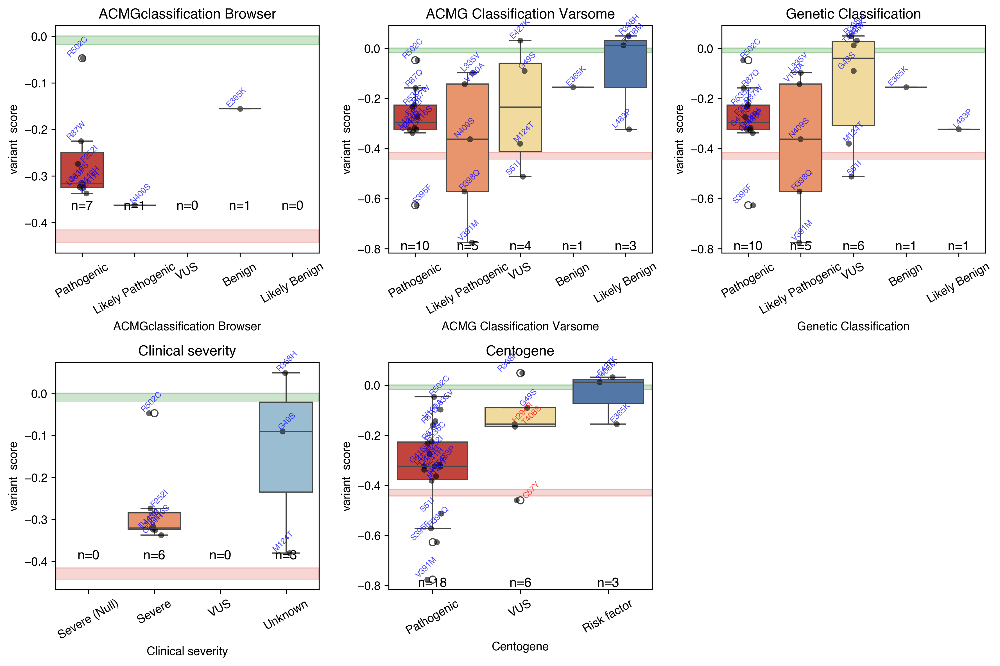

In [ ]:
'''# Mapping 3-letter to 1-letter amino acids
aa3_to_1 = {
    'Ala': 'A', 'Arg': 'R', 'Asn': 'N', 'Asp': 'D',
    'Cys': 'C', 'Gln': 'Q', 'Glu': 'E', 'Gly': 'G',
    'His': 'H', 'Ile': 'I', 'Leu': 'L', 'Lys': 'K',
    'Met': 'M', 'Phe': 'F', 'Pro': 'P', 'Ser': 'S',
    'Thr': 'T', 'Trp': 'W', 'Tyr': 'Y', 'Val': 'V'
}

import re

def aa_sub_to_short(s):
    if not isinstance(s, str):
        return None  # skip non-string entries (e.g., NaN)
    
    match = re.match(r'p\.([A-Z][a-z]{2})(\d+)([A-Z][a-z]{2}|\*)$', s)
    if match:
        ref, pos, alt = match.groups()
        if ref in aa3_to_1:
            alt_letter = '*' if alt == '*' else aa3_to_1.get(alt)
            if alt_letter:
                return f"{aa3_to_1[ref]}{pos}{alt_letter}"
    return None  # Non-standard or unmatched variant

stop_codons = var_scores[var_scores['aa_substitutions'].str.endswith('*', na=False)]

# Extract the scores
scores = stop_codons['variant_score'].dropna()

# Compute mean and 95% confidence interval
mean = scores.mean()
sem = stats.sem(scores)  # standard error of the mean
ci_stop = sem * stats.t.ppf((1 + 0.95) / 2., len(scores)-1)  # 95% CI


# Apply function
#df generated by Sophie
mds=pd.read_csv('input_files/Variant_Selection_Sophie_2.csv')

#variants shared by Centogene (30/Sep/2025)
centogene_df=pd.read_csv('input_files/centogene.csv')

mds=mds[mds['Variant type'].isin(['missense','nonsense'])]

mds=mds.merge(centogene_df, on='mut_p', how='outer')
mds['mut_p'].apply(aa_sub_to_short)
mds['aa_substitutions'] = mds['mut_p'].apply(aa_sub_to_short)

var_scores=variants_score_dict['gba1_r1']

mds=pd.merge(mds, var_scores, on='aa_substitutions', how='outer')

mds.rename(columns={'gba1_r1': 'Variant score'}, inplace=True)
'''
mds_Centogene = mds[~mds['Centogene'].isna()]


# Define your columns
cols = ['ACMGclassification Browser',
        'ACMG Classification Varsome',
        'Genetic Classification',
        'Clinical severity',
        'Centogene'] 

# Custom order for ACMG-related classifications
acmg_order = ['Pathogenic', 'Likely Pathogenic', 'VUS', 'Benign', 'Likely Benign']

# Custom order for Clinical severity
severity_order = ['Severe (Null)', 'Severe', 'VUS', 'Unknown']

# Custom order for Clinical severity
cnetogene_order = ['Pathogenic', 'VUS', 'Risk factor']

# Custom color palette matching categories
palette_acmg = {
    'Pathogenic': '#d73027',
    'Likely Pathogenic': '#fc8d59',
    'VUS': '#fee090',
    'Benign': '#91bfdb',
    'Likely Benign': '#4575b4'
}

palette_severity = {
    'Severe (Null)': '#d73027',
    'Severe': '#fc8d59',
    'VUS': '#fee090',
    'Unknown': '#91bfdb'
}

palette_centogene = {
    'Pathogenic': '#d73027',
    'VUS': '#fee090',
    'Risk factor': '#4575b4'
}

# Create 2x2 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

# After plotting all columns
for k in range(len(cols), len(axes)):
    axes[k].set_visible(False)  # hide empty subplot

# Loop through the columns and plot
for i, col in enumerate(cols):
    if col == 'Clinical severity':
        order = severity_order
        palette = palette_severity
    elif col == 'Centogene':
        order = cnetogene_order
        palette = palette_centogene
    else:
        order = acmg_order
        palette = palette_acmg

    # Boxplot
    sns.boxplot(
        x=col,
        y='variant_score',   # numeric column
        data=mds_Centogene,
        order=order,
        palette=palette,
        ax=axes[i],
        showcaps=True,
        boxprops={'zorder': 2},
        whiskerprops={'zorder': 2}
    )

    # Datapoints
    sns.stripplot(
        x=col,
        y='variant_score',
        data=mds_Centogene,
        color='black',
        order=order,
        ax=axes[i],
        jitter=True,
        dodge=True,
        alpha=0.6,
        zorder=2
    )

    # Add sample size (n=) just above x-axis ticks
    counts = mds_Centogene[col].value_counts()
    for j, category in enumerate(order):
        n = counts.get(category, 0)
        axes[i].text(
            j,   # x position
            axes[i].get_ylim()[0],  # baseline (x-axis)
            f"n={n}",
            ha='center', va='bottom', fontsize=11, color='black', 
        )
    # Annotate each point with aa_substitutions
    for j, category in enumerate(order):
        subset = mds_Centogene[mds_Centogene[col] == category]
        for k, row in subset.iterrows():
            x_pos = j + np.random.uniform(-0.15, 0.15)  # match jitter
            y_pos = row['variant_score']
            label = row['aa_substitutions']
            if label:  # only annotate non-None
                ftext_color = 'red' if label in ['H294R', 'C57Y', 'T408S'] else 'blue'
                axes[i].text(
                    x_pos, y_pos, label, fontsize=7, color=ftext_color,
                    rotation=45, ha='center', va='bottom', alpha=0.7
                )    

    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=30)
    
    axes[i].axhspan(
    mean - ci_stop,  # lower bound
    mean + ci_stop,  # upper bound
    color='#d73027',
    alpha=0.2)

    axes[i].axhspan(
    -0.018,  # lower bound
    0.001,  # upper bound
    color='green',
    alpha=0.2
)


plt.tight_layout()
plt.savefig('results/figures/misc/variant_classification_centogene_only.pdf', bbox_inches='tight')
plt.show()

In [ ]:
Lanore_df=pd.read_csv('input_files/Lanore_et_al_2025_supplementary_table.csv')
Lanore_df["aa_substitutions"] = Lanore_df["aa_substitutions"].str.replace(
    r"([A-Z])(\d+)([A-Z*])",
    lambda m: f"{m.group(1)}{int(m.group(2))+39}{m.group(3)}",
    regex=True
)

Lanore_df=Lanore_df.merge(var_scores, on='aa_substitutions', how='left')


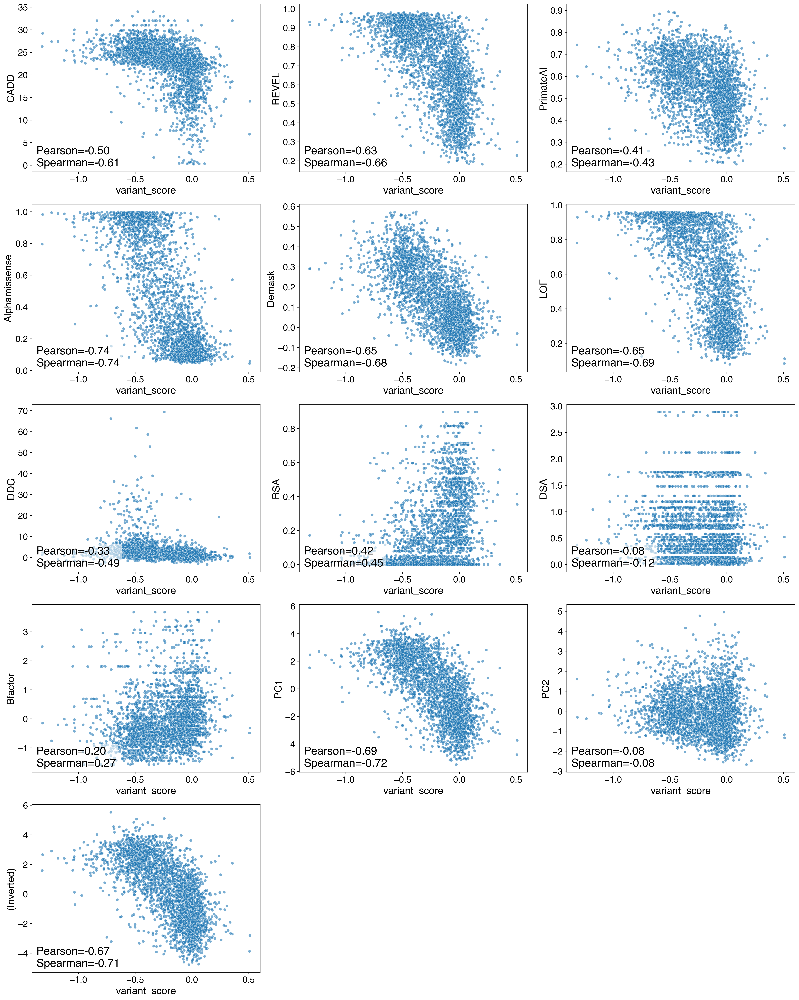

In [ ]:

# Select the relevant columns between "CADD" and "(Inverted)"
cols_to_compare = Lanore_df.loc[:, "CADD":"(Inverted)"].columns

# Prepare subplots (5 rows × 3 cols = 15, but we’ll only use 13)
fig, axes = plt.subplots(5, 3, figsize=(20, 25))
axes = axes.flatten()

for i, col in enumerate(cols_to_compare):
    ax = axes[i]
    
    # Compute Pearson and Spearman correlations
    pearson_corr = Lanore_df["variant_score"].corr(Lanore_df[col], method="pearson")
    spearman_corr = Lanore_df["variant_score"].corr(Lanore_df[col], method="spearman")
    
    # Scatter plot
    sns.scatterplot(
        data=Lanore_df,
        x="variant_score",
        y=col,
        ax=ax,
        s=25,
        alpha=0.6
    )
    
    # Axis labels with larger fonts
    ax.set_xlabel("variant_score", fontsize=18)
    ax.set_ylabel(col, fontsize=18)
    ax.tick_params(axis='both', labelsize=16)
    
    # Put correlation text inside bottom-left
    ax.text(
        0.02, 0.02,
        f"Pearson={pearson_corr:.2f}\nSpearman={spearman_corr:.2f}",
        transform=ax.transAxes,
        fontsize=20,
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')
    )

# Hide unused subplots (if fewer than 15)
for j in range(len(cols_to_compare), len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.savefig('results/figures/misc/Lanore_et_al_2025_correlation_plots.pdf', bbox_inches='tight')
plt.show()

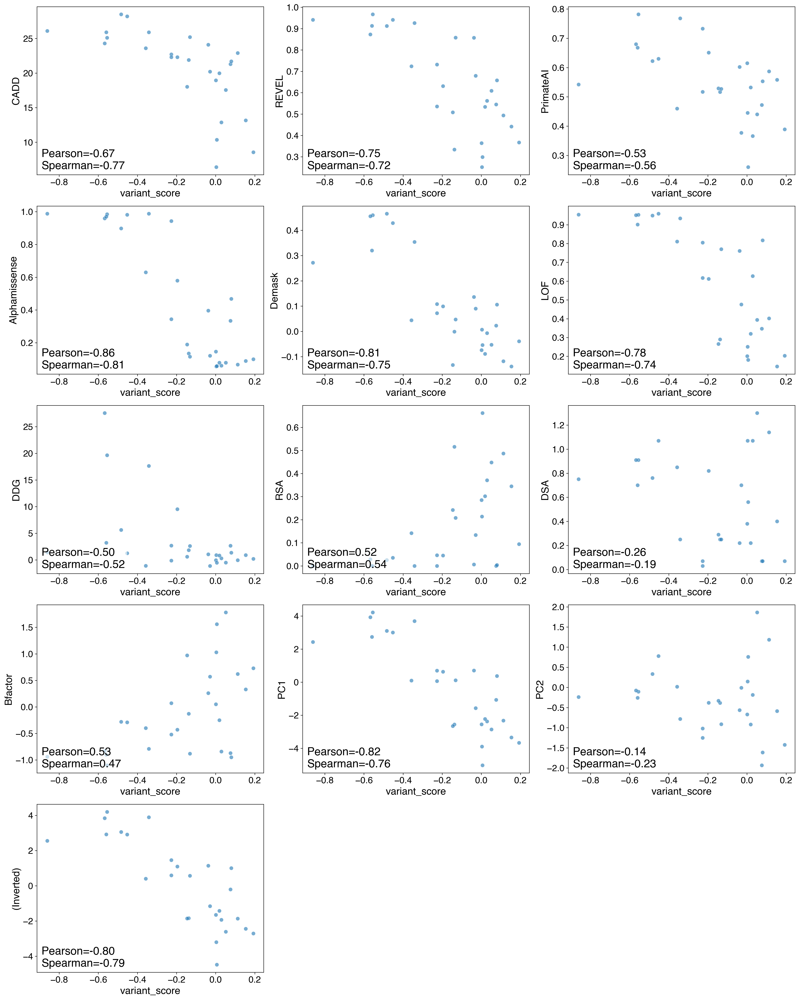

In [ ]:
Pakorna_variants=['P45S','S52L','F76L','G119R','G152R','M162I','C165Y','S276F','I299M','T306I',
 'D321A','L327P','W330G','E339K','E365D','T366A','K447R','P467S','E520Q','T530I',
 'Y50H','P68L','M124I','Q208R','P426L','A477T','M489I']

Lanore_df_withPakornaVariants=Lanore_df[Lanore_df['aa_substitutions'].isin(Pakorna_variants)]
# Select the relevant columns between "CADD" and "(Inverted)"
cols_to_compare = Lanore_df_withPakornaVariants.loc[:, "CADD":"(Inverted)"].columns

# Prepare subplots (5 rows × 3 cols = 15, but we’ll only use 13)
fig, axes = plt.subplots(5, 3, figsize=(20, 25))
axes = axes.flatten()

for i, col in enumerate(cols_to_compare):
    ax = axes[i]
    
    # Compute Pearson and Spearman correlations
    pearson_corr = Lanore_df_withPakornaVariants["variant_score"].corr(Lanore_df_withPakornaVariants[col], method="pearson")
    spearman_corr = Lanore_df_withPakornaVariants["variant_score"].corr(Lanore_df_withPakornaVariants[col], method="spearman")
    
    # Scatter plot
    sns.scatterplot(
        data=Lanore_df_withPakornaVariants,
        x="variant_score",
        y=col,
        ax=ax,
        s=50,
        alpha=0.6,
    )
    
    # Axis labels with larger fonts
    ax.set_xlabel("variant_score", fontsize=18)
    ax.set_ylabel(col, fontsize=18)
    ax.tick_params(axis='both', labelsize=16)
    
    # Put correlation text inside bottom-left
    ax.text(
        0.02, 0.02,
        f"Pearson={pearson_corr:.2f}\nSpearman={spearman_corr:.2f}",
        transform=ax.transAxes,
        fontsize=20,
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')
    )

# Hide unused subplots (if fewer than 15)
for j in range(len(cols_to_compare), len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
#plt.savefig('results/figures/misc/Lanore_et_al_2025_correlation_plots.pdf', bbox_inches='tight')
plt.show()

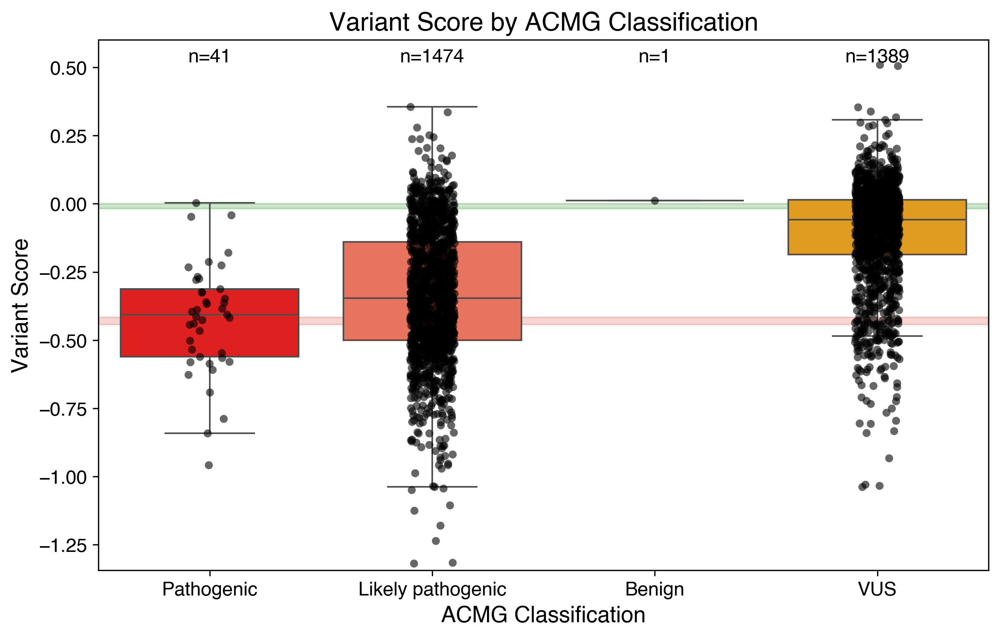

In [ ]:

# Drop NaNs in ACMG
df_plot = Lanore_df.dropna(subset=['ACMG']).copy()

# Define the desired order
acmg_order = ['Pathogenic','Likely pathogenic',  'Benign', 'VUS']

# Define custom colors
colors = ['#FF0000', '#FF6347',  '#90EE90', '#FFA500']

# Make ACMG a categorical type with the specified order
df_plot['ACMG'] = pd.Categorical(df_plot['ACMG'], categories=acmg_order, ordered=True)

# Create the boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    y='variant_score',
    x='ACMG',
    palette=colors,
    order=acmg_order,
    showcaps=True,
    #boxprops={'facecolor':'None'},
    showfliers=False
)

# Overlay individual points
sns.stripplot(
    data=df_plot,
    y='variant_score',
    x='ACMG',
    order=acmg_order,
    color='black',
    size=5,
    jitter=True,
    alpha=0.6
)

# Add n= counts on top of each box
group_counts = df_plot['ACMG'].value_counts().reindex(acmg_order)
for i, count in enumerate(group_counts):
    plt.text(i, df_plot['variant_score'].max() + 0.02*df_plot['variant_score'].max(),
             f"n={count}", ha='center', fontsize=12)

plt.xlabel('ACMG Classification', fontsize=14)
plt.ylabel('Variant Score', fontsize=14)
plt.title('Variant Score by ACMG Classification', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(bottom=df_plot['variant_score'].min() - 0.05*df_plot['variant_score'].max())  # adjust lower limit



plt.axhspan(
    mean - ci_stop,  # lower bound
    mean + ci_stop,  # upper bound
    color='#d73027',
    alpha=0.2)


plt.axhspan(
    -0.018,  # lower bound
    0.001,  # upper bound
    color='green',
    alpha=0.2
)
plt.show()

In [ ]:
Pokorna_df=pd.read_csv('input_files/Pokorna_et_el_2023_gcaseActivity.csv')


Pokorna_df=Pokorna_df.merge(var_scores, on='aa_substitutions', how='left')
Pokorna_df.dropna(subset=['variant_score'], inplace=True)

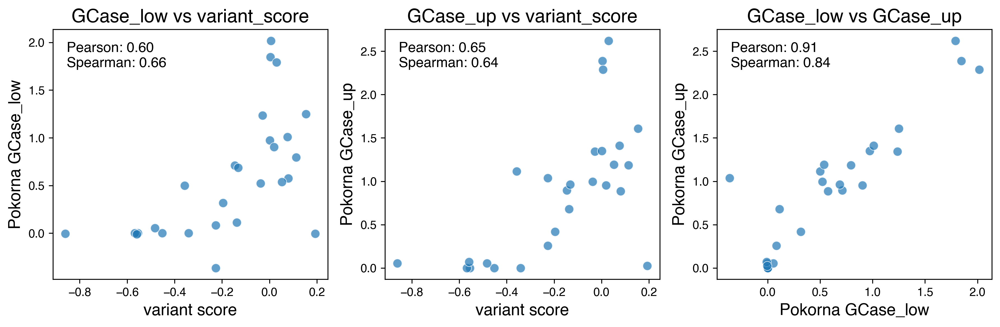

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Define plotting pairs and labels
plot_info = [
    ('variant_score', 'GCase_low', 'GCase_low vs variant_score', 'variant score', 'Pokorna GCase_low'),
    ('variant_score', 'GCase_up', 'GCase_up vs variant_score', 'variant score', 'Pokorna GCase_up'),
    ('GCase_low', 'GCase_up', 'GCase_low vs GCase_up', 'Pokorna GCase_low', 'Pokorna GCase_up')
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Loop over subplots
for i, (x_col, y_col, title, xlabel, ylabel) in enumerate(plot_info):
    sns.scatterplot(data=Pokorna_df, x=x_col, y=y_col, ax=axes[i], s=60, alpha=0.7)
    axes[i].set_title(title, fontsize=16)
    axes[i].set_xlabel(xlabel, fontsize=14)
    axes[i].set_ylabel(ylabel, fontsize=14)
    
    pearson_val, spearman_val = pearsonr(Pokorna_df[x_col], Pokorna_df[y_col]), spearmanr(Pokorna_df[x_col], Pokorna_df[y_col])
    axes[i].text(0.05, 0.95, f"Pearson: {pearson_val[0]:.2f}\nSpearman: {spearman_val.correlation:.2f}", 
                 transform=axes[i].transAxes, verticalalignment='top', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
Pokorna_df['aa_substitutions'].tolist()

['P45S',
 'S52L',
 'F76L',
 'G119R',
 'G152R',
 'M162I',
 'C165Y',
 'S276F',
 'I299M',
 'T306I',
 'D321A',
 'L327P',
 'W330G',
 'E339K',
 'E365D',
 'T366A',
 'K447R',
 'P467S',
 'E520Q',
 'T530I',
 'Y50H',
 'P68L',
 'M124I',
 'Q208R',
 'P426L',
 'A477T',
 'M489I']

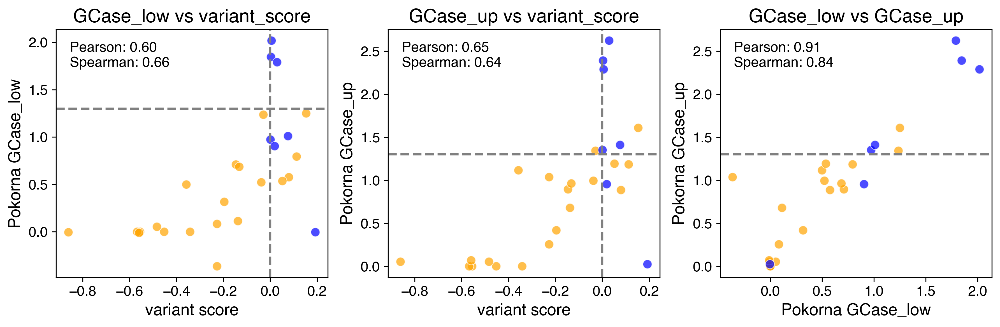

In [ ]:
import matplotlib.patches as mpatches
# Define plotting pairs and labels
plot_info = [
    ('variant_score', 'GCase_low', 'GCase_low vs variant_score', 'variant score', 'Pokorna GCase_low'),
    ('variant_score', 'GCase_up', 'GCase_up vs variant_score', 'variant score', 'Pokorna GCase_up'),
    ('GCase_low', 'GCase_up', 'GCase_low vs GCase_up', 'Pokorna GCase_low', 'Pokorna GCase_up')
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Define colors
color_map = {'Predicted benign': 'blue', 'Predicted GD-causing': 'orange'}

# Loop over subplots
for i, (x_col, y_col, title, xlabel, ylabel) in enumerate(plot_info):
    sns.scatterplot(data=Pokorna_df, x=x_col, y=y_col, hue='Category', palette=color_map, ax=axes[i], s=60, alpha=0.7, legend=False)
    axes[i].set_title(title, fontsize=16)
    axes[i].set_xlabel(xlabel, fontsize=14)
    axes[i].set_ylabel(ylabel, fontsize=14)
    axes[i].tick_params(axis='x', labelsize=12)
    axes[i].tick_params(axis='y', labelsize=12)

    if i < 2:
        axes[i].axvline(0, color='gray', linestyle='--', linewidth=2)
    #WT GCase activity is around 1.3 for Pakora et al.
    axes[i].axhline(1.3, color='gray', linestyle='--', linewidth=2)

    
    pearson_val, spearman_val = pearsonr(Pokorna_df[x_col], Pokorna_df[y_col]), spearmanr(Pokorna_df[x_col], Pokorna_df[y_col])
    axes[i].text(0.05, 0.95, f"Pearson: {pearson_val[0]:.2f}\nSpearman: {spearman_val.correlation:.2f}", 
                 transform=axes[i].transAxes, verticalalignment='top', fontsize=12)



plt.tight_layout()
plt.show()

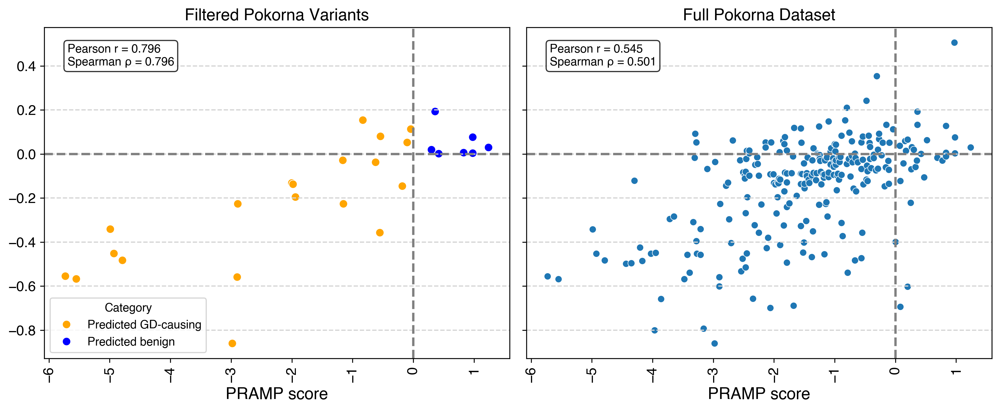

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load and adjust Pakorna_full
Pakorna_full = pd.read_csv('input_files/Pokorna_et_el_2023_gcaseActivity_fullData.csv')
Pakorna_full["aa_substitutions"] = Pakorna_full["aa_substitutions"].str.replace(
    r"([A-Z])(\d+)([A-Z*])",
    lambda m: f"{m.group(1)}{int(m.group(2))+39}{m.group(3)}",
    regex=True
)
Pakorna_full = Pakorna_full.merge(var_scores, on='aa_substitutions', how='left')

# Filtered dataframe using Pokorna_df and take Category from it
Pakorna_filtered = Pakorna_full.merge(
    Pokorna_df[['aa_substitutions', 'Category']],  # only aa_substitutions + Category
    on='aa_substitutions',
    how='inner'
)

# Function to calculate correlations
def calc_corr(df):
    df_clean = df[['variant_score', 'PRAMP score']].dropna()
    pearson_corr, pearson_p = stats.pearsonr(df_clean['variant_score'], df_clean['PRAMP score'])
    spearman_corr, spearman_p = stats.spearmanr(df_clean['variant_score'], df_clean['PRAMP score'])
    return pearson_corr, pearson_p, spearman_corr, spearman_p

# Side-by-side scatterplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# --- Full dataset ---
pearson_corr, pearson_p, spearman_corr, spearman_p = calc_corr(Pakorna_full)
sns.scatterplot(data=Pakorna_full, x='PRAMP score', y='variant_score', ax=axes[1])
axes[1].axhline(0, color='gray', linestyle='--', linewidth=2)
axes[1].axvline(0, color='gray', linestyle='--', linewidth=2)

axes[1].set_title('Full Pokorna Dataset', fontsize=14)
axes[1].set_xlabel('PRAMP score', fontsize=14)
axes[1].set_ylabel('Variant Score', fontsize=14)
axes[1].tick_params(axis='x', labelsize=12, rotation=90)
axes[1].tick_params(axis='y', labelsize=12)
axes[1].text(0.05, 0.95, f'Pearson r = {pearson_corr:.3f}\nSpearman ρ = {spearman_corr:.3f}', 
             transform=axes[1].transAxes, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
axes[1].grid(True, which='major', axis='y', color='lightgrey', linestyle='--', linewidth=1)

# --- Filtered dataset with Category coloring ---
color_map = {'Predicted benign': 'blue', 'Predicted GD-causing': 'orange'}
pearson_corr, pearson_p, spearman_corr, spearman_p = calc_corr(Pakorna_filtered)
sns.scatterplot(
    data=Pakorna_filtered, x='PRAMP score', y='variant_score',
    hue='Category', palette=color_map, ax=axes[0], s=50
)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=2)
axes[0].axvline(0, color='gray', linestyle='--', linewidth=2)

axes[0].set_title('Filtered Pokorna Variants', fontsize=14)
axes[0].set_xlabel('PRAMP score', fontsize=14)
axes[0].set_ylabel('')  # shared y-axis
axes[0].tick_params(axis='x', labelsize=12, rotation=90)
axes[0].tick_params(axis='y', labelsize=12)
axes[0].text(0.05, 0.95, f'Pearson r = {pearson_corr:.3f}\nSpearman ρ = {spearman_corr:.3f}', 
             transform=axes[0].transAxes, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
axes[0].grid(True, which='major', axis='y', color='lightgrey', linestyle='--', linewidth=1)


plt.tight_layout()
plt.show()

KeyError: 'residue_number'

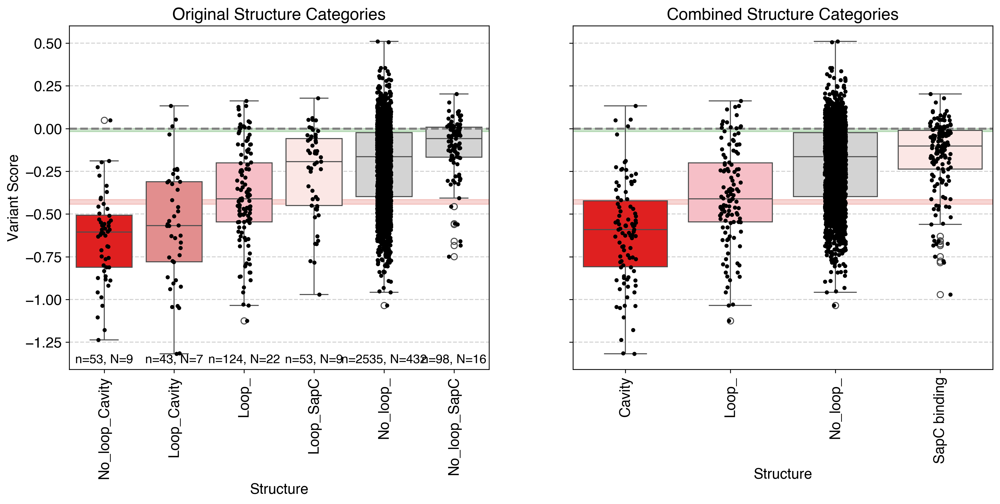

In [ ]:
# Reload Lanore_structural to avoid cumulative changes
Lanore_structural = pd.read_csv('input_files/Lanore_SharedStructural.csv')
Lanore_structural["aa_substitutions"] = Lanore_structural["aa_substitutions"].str.replace(
    r"([A-Z])(\d+)([A-Z*])",
    lambda m: f"{m.group(1)}{int(m.group(2))+39}{m.group(3)}",
    regex=True
)
# Merge with var_scores again
Lanore_structural = Lanore_structural.merge(var_scores, on='aa_substitutions', how='left')

# Extract numeric residue positions from aa_substitutions
Lanore_structural["position"] = Lanore_structural["aa_substitutions"].str.extract(r'(\d+)').astype(int)

# First plot order (without SapC_critical)
structure_order_first = ['No_loop_Cavity', 'Loop_Cavity', 'Loop_', 'Loop_SapC', 'No_loop_', 'No_loop_SapC']
colors_first = ['red', 'lightcoral', 'lightpink', 'mistyrose', 'lightgrey', 'lightgrey']

# Second plot order (combined categories, without SapC_critical)
Lanore_structural['structure_combined'] = Lanore_structural['structure'].replace({
    'No_loop_Cavity': 'Cavity',
    'Loop_Cavity': 'Cavity',
    'Loop_SapC': 'SapC binding',
    'No_loop_SapC': 'SapC binding'
})
structure_order_second = ['Cavity', 'Loop_', 'No_loop_', 'SapC binding']
colors_second = ['red', 'lightpink', 'lightgrey', 'mistyrose']

# Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# --- First plot ---
ax1 = axes[0]
sns.boxplot(
    data=Lanore_structural,
    y='variant_score',
    x='structure',
    order=structure_order_first,
    palette=colors_first,
    ax=ax1
)
sns.stripplot(
    data=Lanore_structural,
    y='variant_score',
    x='structure',
    order=structure_order_first,
    color='black',
    size=4,
    jitter=True,
    ax=ax1
)
ax1.axhspan(mean - ci_stop, mean + ci_stop, color='#d73027', alpha=0.2)
ax1.axhspan(-0.018, 0.001, color='green', alpha=0.2)

ax1.set_title('Original Structure Categories', fontsize=16)
ax1.axhline(0, color='gray', linestyle='--', linewidth=2)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, fontsize=14)
ax1.set_xlabel('Structure', fontsize=14)
ax1.set_ylabel('Variant Score', fontsize=14)
ax1.tick_params(axis='y', labelsize=14)
ax1.grid(True, which='major', axis='y', color='lightgrey', linestyle='--', linewidth=1)

for i, structure in enumerate(structure_order_first):
    df_subset = Lanore_structural[Lanore_structural['structure'] == structure]
    n = len(df_subset)
    N = df_subset['position'].nunique()
    ax1.text(i, ax1.get_ylim()[0] + 0.09, f'n={n}, N={N}', ha='center', va='top', fontsize=12, fontweight='bold')

# --- Second plot ---
ax2 = axes[1]
sns.boxplot(
    data=Lanore_structural,
    y='variant_score',
    x='structure_combined',
    order=structure_order_second,
    palette=colors_second,
    ax=ax2
)
sns.stripplot(
    data=Lanore_structural,
    y='variant_score',
    x='structure_combined',
    order=structure_order_second,
    color='black',
    size=4,
    jitter=True,
    ax=ax2
)
ax2.axhspan(mean - ci_stop, mean + ci_stop, color='#d73027', alpha=0.2)
ax2.axhspan(-0.018, 0.001, color='green', alpha=0.2)

ax2.set_title('Combined Structure Categories', fontsize=16)
ax2.axhline(0, color='gray', linestyle='--', linewidth=2)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90, fontsize=14)
ax2.set_xlabel('Structure', fontsize=14)
ax2.set_ylabel('Variant Score', fontsize=14)
ax2.tick_params(axis='y', labelsize=14)
ax2.grid(True, which='major', axis='y', color='lightgrey', linestyle='--', linewidth=1)

for i, structure in enumerate(structure_order_second):
    df_subset = Lanore_structural[Lanore_structural['structure_combined'] == structure]
    n = len(df_subset)
    N = df_subset['residue_number'].nunique()
    ax2.text(i, ax2.get_ylim()[0] + 0.09, f'n={n}, N={N}', ha='center', va='top', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

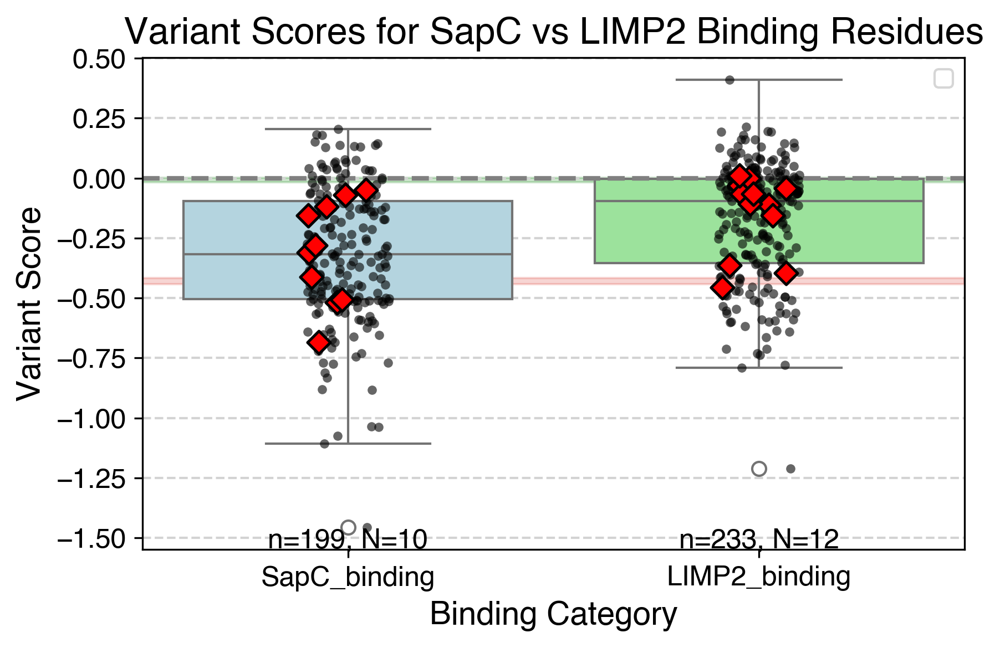

SapC binding residues statistics:
  Number of variants: 199
  Number of unique residues: 10
  Mean variant score: -0.3177
  Median variant score: -0.3177

LIMP2 binding residues statistics:
  Number of variants: 233
  Number of unique residues: 12
  Mean variant score: -0.1789
  Median variant score: -0.0963

--- Statistical comparison against total variant scores ---
SapC vs Total: U = 893882.50, p = 8.1990e-04
LIMP2 vs Total: U = 1410802.50, p = 2.3805e-05


In [ ]:

from scipy.stats import mannwhitneyu, wilcoxon

# --- Define the residue positions ---
GBA1_SapC_residues = [315, 348, 340, 350, 353, 357, 373, 370, 395, 444]
positions_plus39 = [p + 39 for p in GBA1_SapC_residues]

gba1_limp2_binding_residues = [91, 94, 95, 96, 130, 151, 156, 388, 391, 395, 406, 409]
positions_limp2_plus39 = [p + 39 for p in gba1_limp2_binding_residues]

# --- Filter var_scores for each set of positions ---
sapc_variants = var_scores[var_scores["position"].isin(positions_plus39)].copy()
limp2_variants = var_scores[var_scores["position"].isin(positions_limp2_plus39)].copy()

# Add category labels
sapc_variants["category"] = "SapC_binding"
limp2_variants["category"] = "LIMP2_binding"

# Combine both categories
combined_df = pd.concat([sapc_variants, limp2_variants], ignore_index=True)

# --- Boxplot ---
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=combined_df,
    x='category',
    y='variant_score',
    palette=['lightblue', 'lightgreen']
)
sns.stripplot(
    data=combined_df,
    x='category',
    y='variant_score',
    color='black',
    size=4,
    jitter=True,
    alpha=0.6
)

# --- Add per-position median points ---
median_per_pos = combined_df.groupby(['category', 'position'])['variant_score'].median().reset_index()
sns.stripplot(
    data=median_per_pos,
    x='category',
    y='variant_score',
    marker='D',
    size=7,
    color='red',
    edgecolor='black',
    linewidth=1.2,
    label='Median per position'
)

# --- Add reference lines ---
plt.axhline(0, color='gray', linestyle='--', linewidth=2)
plt.axhspan(mean - ci_stop, mean + ci_stop, color='#d73027', alpha=0.2)
plt.axhspan(-0.018, 0.001, color='green', alpha=0.2)

# --- Customize the plot ---
plt.title('Variant Scores for SapC vs LIMP2 Binding Residues', fontsize=16)
plt.xlabel('Binding Category', fontsize=14)
plt.ylabel('Variant Score', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, which='major', axis='y', color='lightgrey', linestyle='--', linewidth=1)
plt.legend('')

# --- Add sample size annotations ---
for i, category in enumerate(['SapC_binding', 'LIMP2_binding']):
    df_subset = combined_df[combined_df['category'] == category]
    n = len(df_subset)
    N = df_subset['position'].nunique()
    plt.text(i, plt.ylim()[0] + 0.09, f'n={n}, N={N}', ha='center', va='top', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# --- Summary statistics ---
print("SapC binding residues statistics:")
print(f"  Number of variants: {len(sapc_variants)}")
print(f"  Number of unique residues: {sapc_variants['position'].nunique()}")
print(f"  Mean variant score: {sapc_variants['variant_score'].mean():.4f}")
print(f"  Median variant score: {sapc_variants['variant_score'].median():.4f}")

print("\nLIMP2 binding residues statistics:")
print(f"  Number of variants: {len(limp2_variants)}")
print(f"  Number of unique residues: {limp2_variants['position'].nunique()}")
print(f"  Mean variant score: {limp2_variants['variant_score'].mean():.4f}")
print(f"  Median variant score: {limp2_variants['variant_score'].median():.4f}")

# --- Statistical tests against total distribution ---
total_scores = var_scores['variant_score']

print("\n--- Statistical comparison against total variant scores ---")

# Mann–Whitney U test (non-parametric, independent)
u_sapc, p_sapc = mannwhitneyu(sapc_variants['variant_score'], total_scores, alternative='two-sided')
u_limp2, p_limp2 = mannwhitneyu(limp2_variants['variant_score'], total_scores, alternative='two-sided')

print(f"SapC vs Total: U = {u_sapc:.2f}, p = {p_sapc:.4e}")
print(f"LIMP2 vs Total: U = {u_limp2:.2f}, p = {p_limp2:.4e}")

# Optionally, if the distributions are paired (less common here), you can try Wilcoxon:
# w_sapc, p_sapc_w = wilcoxon(sapc_variants['variant_score'].sample(len(total_scores), replace=True).values, total_scores.values)
# w_limp2, p_limp2_w = wilcoxon(limp2_variants['variant_score'].sample(len(total_scores), replace=True).values, total_scores.values)

In [ ]:
var_scores

NameError: name 'var_scores' is not defined

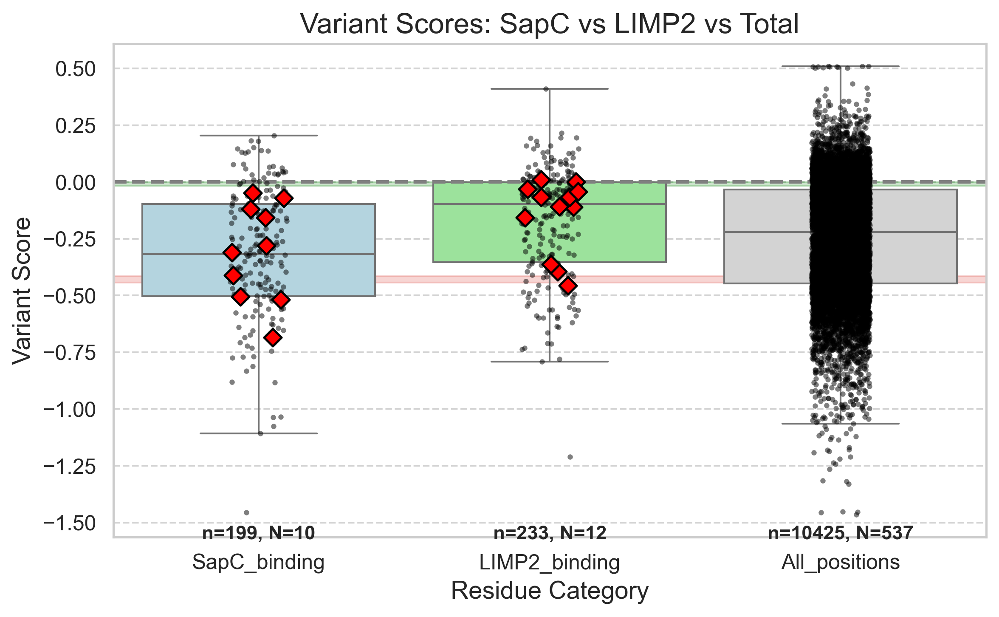

=== Summary Statistics ===

SapC binding residues:
  Number of variants: 199
  Unique residues: 10
  Mean variant score: -0.3177
  Median variant score: -0.3177

LIMP2 binding residues:
  Number of variants: 233
  Unique residues: 12
  Mean variant score: -0.1789
  Median variant score: -0.0963

All binding residues:
  Number of variants: 10425
  Unique residues: 537
  Mean variant score: -0.2481
  Median variant score: -0.2210

=== Mann–Whitney U Tests ===
SapC vs Total:  U = 893882.50,   p = 8.1990e-04
LIMP2 vs Total: U = 1410802.50,  p = 2.3805e-05
SapC vs LIMP2:  U = 16336.00, p = 1.2000e-07


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from adjustText import adjust_text

# --- Define the residue positions ---
GBA1_SapC_residues = [315, 348, 340, 350, 353, 357, 373, 370, 395, 444]
positions_plus39 = [p + 39 for p in GBA1_SapC_residues]

gba1_limp2_binding_residues = [91, 94, 95, 96, 130, 151, 156, 388, 391, 395, 406, 409]
positions_limp2_plus39 = [p + 39 for p in gba1_limp2_binding_residues]

# --- Filter var_scores for each set of positions ---
sapc_variants = var_scores[var_scores["position"].isin(positions_plus39)].copy()
limp2_variants = var_scores[var_scores["position"].isin(positions_limp2_plus39)].copy()

# Add category labels
sapc_variants["category"] = "SapC_binding"
limp2_variants["category"] = "LIMP2_binding"

# Combine both categories
combined_df = pd.concat([sapc_variants, limp2_variants], ignore_index=True)

# Add total dataset for comparison
total_df = var_scores.copy()
total_df["category"] = "All_positions"

# Combine everything
plot_df = pd.concat([combined_df, total_df], ignore_index=True)

# --- Boxplot with total distribution ---
plt.figure(figsize=(8, 5))
sns.set(style="whitegrid")

palette = {"SapC_binding": "lightblue", "LIMP2_binding": "lightgreen", "All_positions": "lightgrey"}

sns.boxplot(
    data=plot_df,
    x="category",
    y="variant_score",
    palette=palette,
    showfliers=False
)

sns.stripplot(
    data=plot_df,
    x="category",
    y="variant_score",
    color="black",
    size=3,
    jitter=True,
    alpha=0.5
)

# --- Add per-position median points for SapC and LIMP2 ---
median_per_pos = combined_df.groupby(['category', 'position'])['variant_score'].median().reset_index()
sns.stripplot(
    data=median_per_pos,
    x='category',
    y='variant_score',
    marker='D',
    size=7,
    color='red',
    edgecolor='black',
    linewidth=1.2,
    label='Median per position'
)

# --- Add reference lines ---
plt.axhline(0, color='gray', linestyle='--', linewidth=2)
plt.axhspan(mean - ci_stop, mean + ci_stop, color='#d73027', alpha=0.2)
plt.axhspan(-0.018, 0.001, color='green', alpha=0.2)

# --- Customize the plot ---
plt.title('Variant Scores: SapC vs LIMP2 vs Total', fontsize=16)
plt.xlabel('Residue Category', fontsize=14)
plt.ylabel('Variant Score', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([], [], frameon=False)
plt.grid(True, which='major', axis='y', color='lightgrey', linestyle='--', linewidth=1)

# --- Add sample size annotations ---
for i, category in enumerate(['SapC_binding', 'LIMP2_binding', 'All_positions']):
    df_subset = plot_df[plot_df['category'] == category]
    n = len(df_subset)
    N = df_subset['position'].nunique()
    plt.text(i, plt.ylim()[0] + 0.05, f'n={n}, N={N}', ha='center', va='top', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# --- Summary statistics ---
print("=== Summary Statistics ===")
for name, df in [("SapC", sapc_variants), ("LIMP2", limp2_variants), ("All", var_scores)]:
    print(f"\n{name} binding residues:")
    print(f"  Number of variants: {len(df)}")
    print(f"  Unique residues: {df['position'].nunique()}")
    print(f"  Mean variant score: {df['variant_score'].mean():.4f}")
    print(f"  Median variant score: {df['variant_score'].median():.4f}")

# --- Statistical tests ---
total_scores = var_scores['variant_score']

print("\n=== Mann–Whitney U Tests ===")
u_sapc, p_sapc = mannwhitneyu(sapc_variants['variant_score'], total_scores, alternative='two-sided')
u_limp2, p_limp2 = mannwhitneyu(limp2_variants['variant_score'], total_scores, alternative='two-sided')
u_sapc_limp2, p_sapc_limp2 = mannwhitneyu(sapc_variants['variant_score'], limp2_variants['variant_score'], alternative='two-sided')

print(f"SapC vs Total:  U = {u_sapc:.2f},   p = {p_sapc:.4e}")
print(f"LIMP2 vs Total: U = {u_limp2:.2f},  p = {p_limp2:.4e}")
print(f"SapC vs LIMP2:  U = {u_sapc_limp2:.2f}, p = {p_sapc_limp2:.4e}")

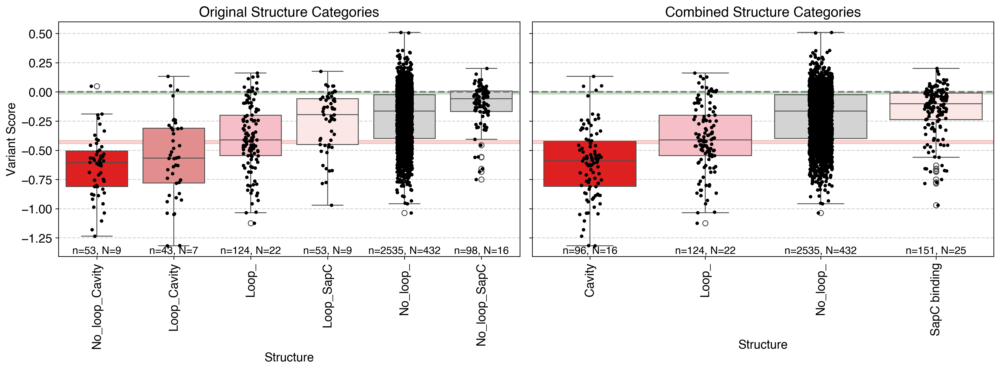

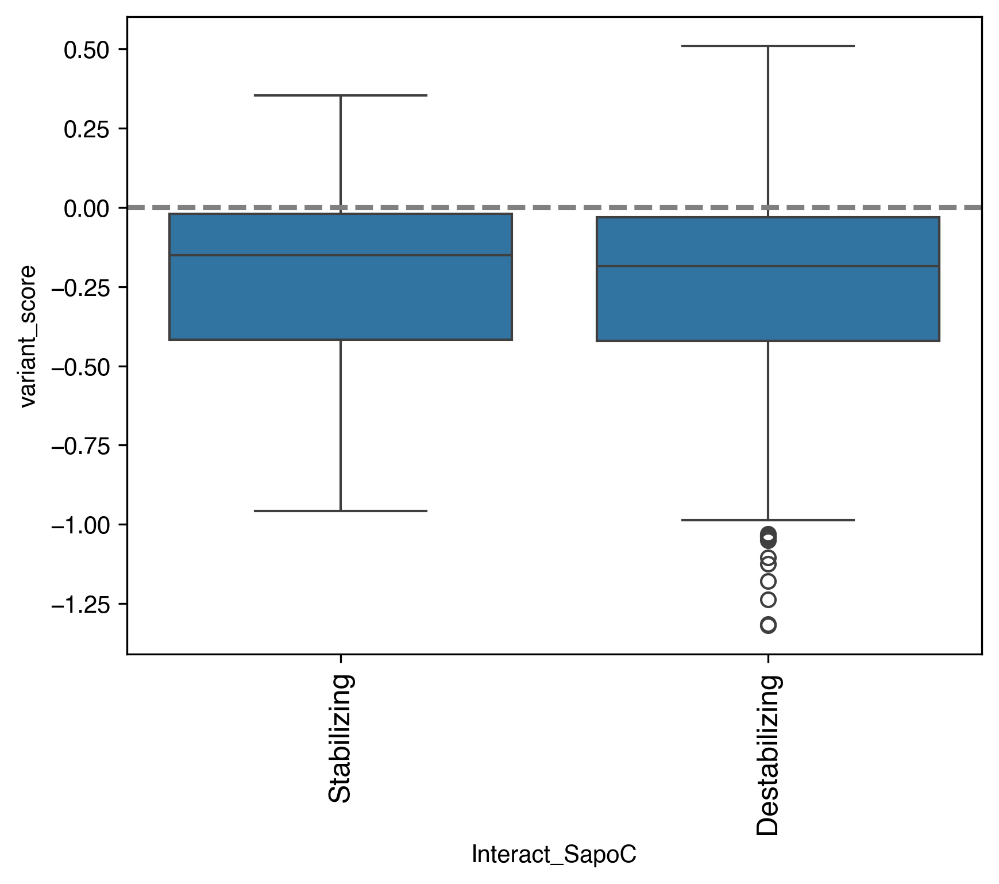

In [ ]:
Lanore_structural = pd.read_csv('input_files/Lanore_SharedStructural.csv')


Lanore_structural["aa_substitutions"] = Lanore_structural["aa_substitutions"].str.replace(
    r"([A-Z])(\d+)([A-Z*])",
    lambda m: f"{m.group(1)}{int(m.group(2))+39}{m.group(3)}",
    regex=True
)
Lanore_structural
Lanore_structural = Lanore_structural.merge(var_scores, on='aa_substitutions', how='left')

sns.boxplot(
    data=Lanore_structural,
    y='variant_score',
    x='Interact_SapC'
)
plt.xticks(rotation=90, size=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=2)

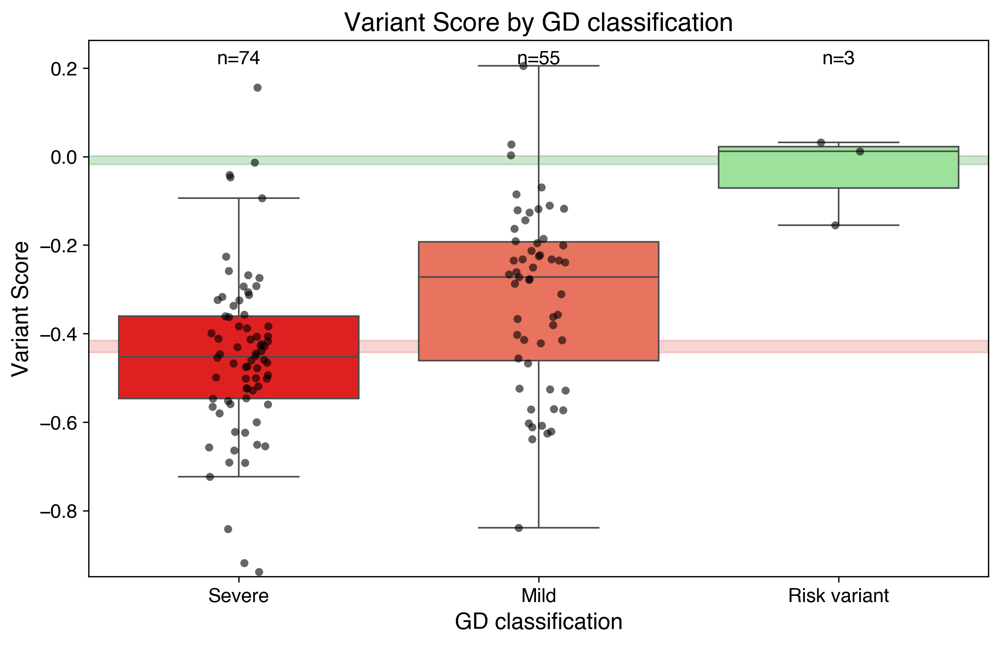

In [ ]:
Lanore_df['GD classification'].unique()


# Drop NaNs in ACMG
df_plot = Lanore_df.dropna(subset=['GD classification']).copy()

# Define the desired order
acmg_order = ['Severe','Mild',  'Risk variant']

# Define custom colors
colors = ['#FF0000', '#FF6347',  '#90EE90']

# Make ACMG a categorical type with the specified order
df_plot['GD classification'] = pd.Categorical(df_plot['GD classification'], categories=acmg_order, ordered=True)

# Create the boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    y='variant_score',
    x='GD classification',
    palette=colors,
    order=acmg_order,
    showcaps=True,
    #boxprops={'facecolor':'None'},
    showfliers=False
)

# Overlay individual points
sns.stripplot(
    data=df_plot,
    y='variant_score',
    x='GD classification',
    order=acmg_order,
    color='black',
    size=5,
    jitter=True,
    alpha=0.6
)

# Add n= counts on top of each box
group_counts = df_plot['GD classification'].value_counts().reindex(acmg_order)
for i, count in enumerate(group_counts):
    plt.text(i, df_plot['variant_score'].max() + 0.02*df_plot['variant_score'].max(),
             f"n={count}", ha='center', fontsize=12)

plt.xlabel('GD classification', fontsize=14)
plt.ylabel('Variant Score', fontsize=14)
plt.title('Variant Score by GD classification', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(bottom=df_plot['variant_score'].min() - 0.05*df_plot['variant_score'].max())  # adjust lower limit



plt.axhspan(
    mean - ci_stop,  # lower bound
    mean + ci_stop,  # upper bound
    color='#d73027',
    alpha=0.2)


plt.axhspan(
    -0.018,  # lower bound
    0.001,  # upper bound
    color='green',
    alpha=0.2
)
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Drop NaNs in ACMG
df_plot = Lanore_df.dropna(subset=['ACMG']).copy()

# Define the desired order
acmg_order = ['Pathogenic','Likely pathogenic',  'Benign', 'VUS']

# Define custom colors
colors = ['#FF0000', '#FF6347',  '#90EE90', '#FFA500']

# Make ACMG a categorical type with the specified order
df_plot['ACMG'] = pd.Categorical(df_plot['ACMG'], categories=acmg_order, ordered=True)

# Create the boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    y='variant_score',
    x='ACMG',
    palette=colors,
    order=acmg_order,
    showcaps=True,
    #boxprops={'facecolor':'None'},
    showfliers=False
)

# Overlay individual points
sns.stripplot(
    data=df_plot,
    y='variant_score',
    x='ACMG',
    order=acmg_order,
    color='black',
    size=5,
    jitter=True,
    alpha=0.6
)

# Add n= counts on top of each box
group_counts = df_plot['ACMG'].value_counts().reindex(acmg_order)
for i, count in enumerate(group_counts):
    plt.text(i, df_plot['variant_score'].max() + 0.02*df_plot['variant_score'].max(),
             f"n={count}", ha='center', fontsize=12)

plt.xlabel('ACMG Classification', fontsize=14)
plt.ylabel('Variant Score', fontsize=14)
plt.title('Variant Score by ACMG Classification', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(bottom=df_plot['variant_score'].min() - 0.05*df_plot['variant_score'].max())  # adjust lower limit



plt.axhspan(
    mean - ci_stop,  # lower bound
    mean + ci_stop,  # upper bound
    color='#d73027',
    alpha=0.2)


plt.axhspan(
    -0.018,  # lower bound
    0.001,  # upper bound
    color='green',
    alpha=0.2
)
plt.show()

np.float64(0.013608483533698167)

<Axes: ylabel='variant_score'>

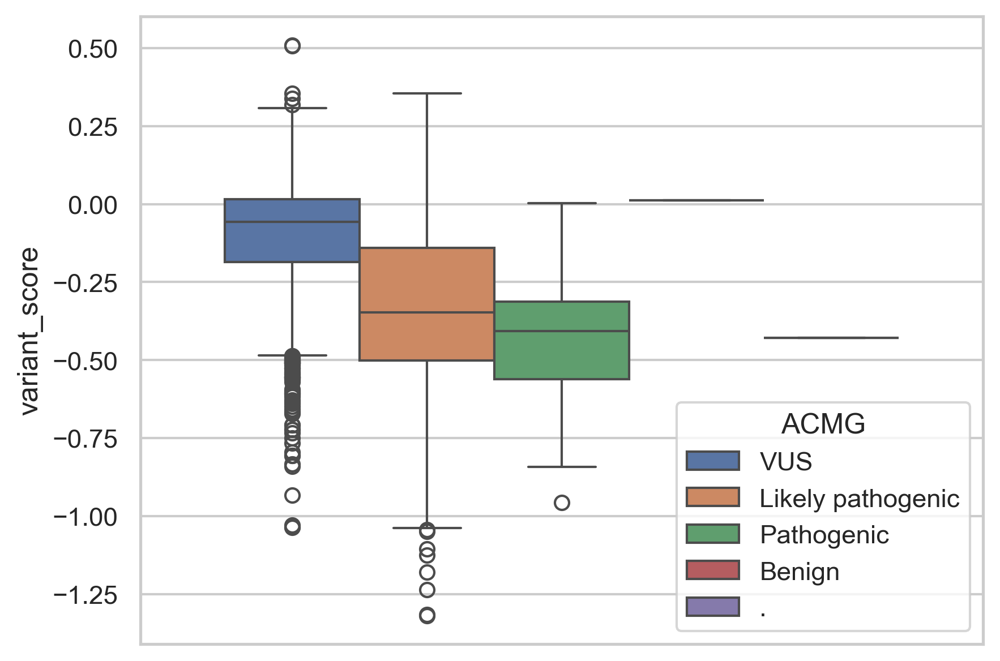

In [ ]:
sns.boxplot(data=Lanore_df,  y='variant_score', hue='ACMG')

In [ ]:
barcode_scored

{'gba1_r1':          index library                         barcode  variant_call_support  \
 0            0    GBA1  TAAGTCGCTGCGCGGATGTCGTTTTTTTTT                    13   
 1            1    GBA1  TTGTTTAGCTGTCAACCCCCCGTTTTTTTT                    44   
 2            2    GBA1  AACGTTCAGCACCTACAGGGATGTTTTTTT                    29   
 3            3    GBA1  TCTATCGAACCGATGACAGACTTGTTTTTT                    18   
 4            4    GBA1  AACCTGTAATGGTGTTTTGCATTGTTTTTT                     1   
 ...        ...     ...                             ...                   ...   
 163637  163637    GBA1  AGGCGGAGTGATGGTAAAATCCGAAAAAAA                    29   
 163638  163638    GBA1  TGAGTTGGGATAGCGCTGTTCTCAAAAAAA                    11   
 163639  163639    GBA1  GGGATAGATAGTAGAAGCACTTAAAAAAAA                     9   
 163640  163640    GBA1  AGGGCTGGTTTTATTACGAGACAAAAAAAA                    46   
 163641  163641    GBA1  TATTAAGCGAAAGACCAGCGGAAAAAAAAA                    18   
 
         number

Number of likely gain-of-function variants: 92


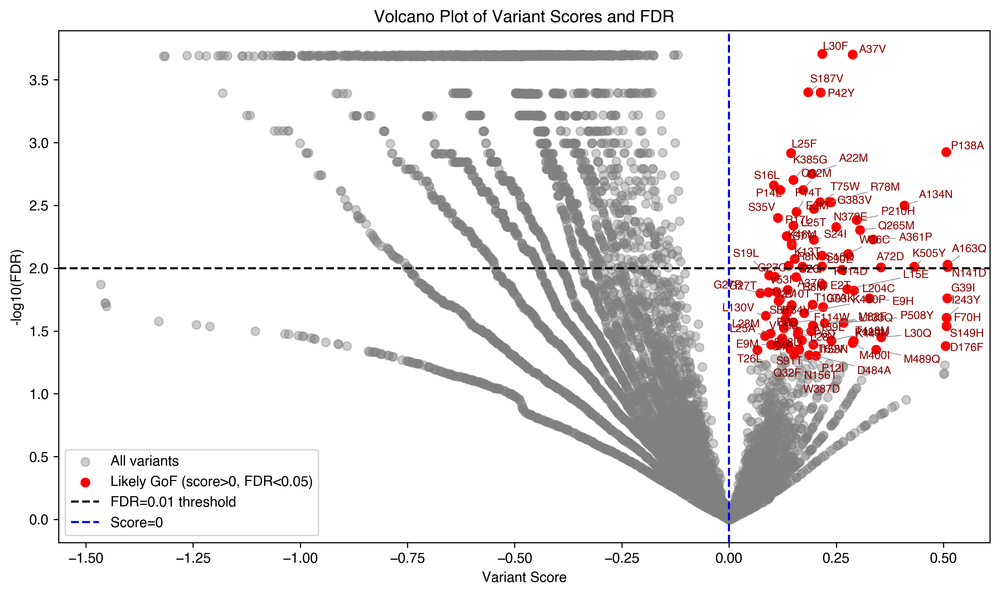

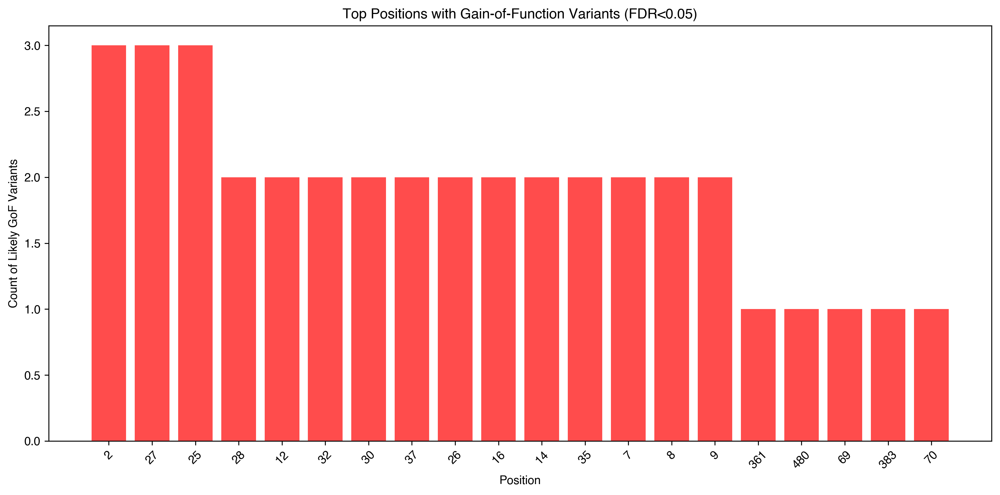

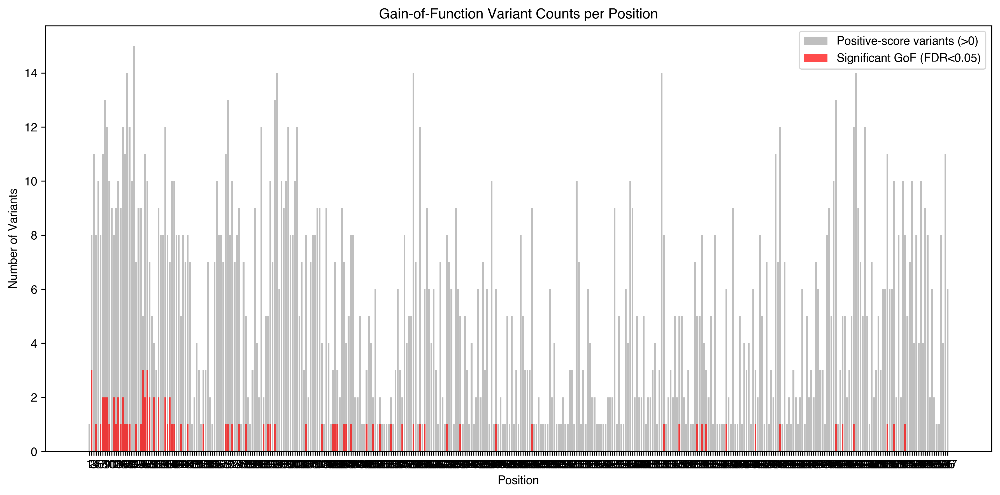

,aa_substitutions,variant_score,FDRvalues,wt_aa,position,variant_aa,bin_number,barcode_count
2,A163Q,0.509661,0.009372,A,163,Q,5,1
48,N141D,0.509644,0.009771,N,141,D,5,1
22,G39I,0.508496,0.017348,G,39,I,5,1
26,I243Y,0.507342,0.024726,I,243,Y,5,1
17,F70H,0.506824,0.028714,F,70,H,5,1
...,...,...,...,...,...,...,...,...
20,G27T,0.091490,0.015479,G,27,T,5,49
33,L130V,0.085071,0.023814,L,130,V,5,49
37,L25A,0.084029,0.034462,L,25,A,5,45
19,G27R,0.072794,0.015781,G,27,R,5,73


In [ ]:
df=variants_score_dict[library]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FDRcutoff=0.05
# ======================================
# 1️⃣ Load Data
# ======================================

# Replace with your actual file path
# df = pd.read_csv("your_data.csv", sep="\t")  
# For demonstration, assuming df is already loaded
# Example columns: ['aa_substitutions', 'variant_score', 'FDRvalues', 'wt_aa', 'position', 'variant_aa']

# Ensure numeric types
df['variant_score'] = pd.to_numeric(df['variant_score'], errors='coerce')
df['FDRvalues'] = pd.to_numeric(df['FDRvalues'], errors='coerce')

# ======================================
# 2️⃣ Filter for likely Gain-of-Function variants
# ======================================

gof_variants = df[(df['variant_score'] > 0) & (df['FDRvalues'] < FDRcutoff)]

print(f"Number of likely gain-of-function variants: {len(gof_variants)}")

# ======================================
# 3️⃣ Summarize by position
# ======================================

# Count of GoF variants per position
position_gof_counts = (
    gof_variants.groupby('position')
    .size()
    .reset_index(name='gof_variant_count')
)

# Count of *all* positive-score variants (regardless of FDR)
position_positive_counts = (
    df[df['variant_score'] > 0]
    .groupby('position')
    .size()
    .reset_index(name='positive_variant_count')
)

# Merge both for comparison
position_summary = pd.merge(position_positive_counts, position_gof_counts, on='position', how='outer').fillna(0)

# ======================================
# 4️⃣ Plotting
# ======================================

# ---- (a) Volcano plot ----
plt.figure(figsize=(10, 6))
plt.scatter(df['variant_score'], -np.log10(df['FDRvalues']), color='gray', alpha=0.4, label='All variants')
plt.scatter(gof_variants['variant_score'], -np.log10(gof_variants['FDRvalues']),
            color='red', label=f'Likely GoF (score>0, FDR<{FDRcutoff})')
# Annotate top GoF variants (by FDR)
top_gof = gof_variants#.nsmallest(50, 'FDRvalues')  # top 30 most significant


    
texts = []
for _, row in top_gof.iterrows():
    texts.append(plt.text(row['variant_score'], -np.log10(row['FDRvalues']),
                          row['aa_substitutions'], fontsize=8, color='darkred'))
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.axhline(-np.log10(0.01), color='black', linestyle='--', label='FDR=0.01 threshold')
plt.axvline(0, color='blue', linestyle='--', label='Score=0')
plt.xlabel('Variant Score')
plt.ylabel('-log10(FDR)')
plt.title('Volcano Plot of Variant Scores and FDR')
plt.legend()
plt.tight_layout()
plt.show()

# ---- (b) Bar plot of GoF counts per position ----
top_positions = position_summary.sort_values('gof_variant_count', ascending=False).head(20)

plt.figure(figsize=(12, 6))
plt.bar(top_positions['position'].astype(str), top_positions['gof_variant_count'], color='red', alpha=0.7)
plt.xlabel('Position')
plt.ylabel('Count of Likely GoF Variants')
plt.title(f'Top Positions with Gain-of-Function Variants (FDR<{FDRcutoff})')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ---- (c) Overlay both positive and significant counts ----
plt.figure(figsize=(12, 6))
plt.bar(position_summary['position'].astype(str), position_summary['positive_variant_count'],
        color='gray', alpha=0.5, label='Positive-score variants (>0)')
plt.bar(position_summary['position'].astype(str), position_summary['gof_variant_count'],
        color='red', alpha=0.7, label=f'Significant GoF (FDR<{FDRcutoff})')
plt.xlabel('Position')
plt.ylabel('Number of Variants')
plt.title('Gain-of-Function Variant Counts per Position')
plt.legend()
plt.tight_layout()
plt.show()

# ======================================
# 5️⃣ Optional: Save results
# ======================================
gof_variants.to_csv("likely_gain_of_function_variants.csv", index=False)
position_summary.to_csv("gof_position_summary.csv", index=False)


# Step 1: Extract your target subset (you already did this)
bc_scored_df = barcode_scored['gba1_r1']
bc_scored_df = bc_scored_df[bc_scored_df['barcode_weighted_avg'].notna()]
bc_scored_df_selected = bc_scored_df[
    bc_scored_df['aa_substitutions'].isin(list(top_gof['aa_substitutions']))
]

# Step 2: Count how many barcodes per aa_substitution
barcode_counts = (
    bc_scored_df_selected
    .groupby('aa_substitutions')
    .size()
    .reset_index(name='barcode_count')
)

# Step 3: Merge these counts into your top_gof DataFrame
top_gof = top_gof.merge(barcode_counts, on='aa_substitutions', how='left')

# Step 4: Fill NaNs (for variants with no barcode counts)
top_gof['barcode_count'] = top_gof['barcode_count'].fillna(0).astype(int)

# Step 5 (optional): sort for easy viewing
top_gof = top_gof.sort_values(by='barcode_count', ascending=False)

# ✅ Result: top_gof now has a new column 'barcode_count'
top_gof.sort_values(by='variant_score', ascending=False, inplace=True)
top_gof.to_csv("likely_gain_of_function_variants_with_barcode_counts.csv", index=False)
top_gof

In [ ]:
gof_variants = df[(df['variant_score'] > 0) & (df['FDRvalues'] < FDRcutoff)]
gof_variants

,aa_substitutions,variant_score,FDRvalues,wt_aa,position,variant_aa,bin_number
105,A134N,0.409252,0.003155,A,134,N,5
123,A139L,0.160798,0.031831,A,139,L,5
145,A163Q,0.509661,0.009372,A,163,Q,5
259,A22M,0.192937,0.001777,A,22,M,5
576,A361P,0.335979,0.005878,A,361,P,5
...,...,...,...,...,...,...,...
9154,T75W,0.211566,0.002966,T,75,W,5
9227,V18M,0.127926,0.030065,V,18,M,5
9745,V53I,0.110752,0.015403,V,53,I,5
9912,W36C,0.277784,0.007679,W,36,C,5


In [ ]:
top_gof['aa_substitutions'].tolist()

['A163Q',
 'N141D',
 'G39I',
 'P138A',
 'K505Y',
 'A134N',
 'A72D',
 'A361P',
 'E9H',
 'Q265M',
 'P210H',
 'L204C',
 'A37V',
 'W36C',
 'L15E',
 'P514D',
 'N372E',
 'G383V',
 'R78M',
 'E2T',
 'L30F',
 'S16Q',
 'L90E',
 'P42Y',
 'T75W',
 'S24I',
 'E2M',
 'T107A',
 'A22M',
 'S187V',
 'Q32M',
 'S7Q',
 'P14T',
 'T26I',
 'K13T',
 'R17L',
 'K385G',
 'K46M',
 'S7Y',
 'L25F',
 'R8N',
 'A37G',
 'L25T',
 'P14L',
 'S35V',
 'G27C',
 'S16L',
 'S19L',
 'G27T',
 'G27R']

In [ ]:
# Copyright (c) 2025 Vahid Aslanzadeh
# All rights reserved.
#
# This software is proprietary and confidential. No part of this code
# may be copied, modified, distributed, or used in any form without
# explicit written permission from the author.
#
# Author: Vahid Aslanzadeh
# Contact: vaslanzadeh@gmail.com

import os
import dash
import pandas as pd
import plotly.graph_objects as go
from dash import Input, Output, State, dcc, html
from plotly.colors import get_colorscale


# ========= Load CSVs ===========
data_directory = "data/"
data_files = {
    file: pd.read_csv(os.path.join(data_directory, file))
    for file in os.listdir(data_directory)
    if file.endswith(".csv")
}

# ========= Function to center zero (white) ===========
def generate_centered_colorscale(zmin, zmax, base_colorscale='RdBu_r'):
    colors = get_colorscale(base_colorscale)
    zero_position = (0 - zmin) / (zmax - zmin)

    new_colorscale = []
    for loc, color in colors:
        if loc <= 0.5:
            new_loc = loc * zero_position / 0.5
        else:
            new_loc = zero_position + ((loc - 0.5) * (1 - zero_position) / 0.5)
        new_colorscale.append([new_loc, color])
    return new_colorscale

# ========= App Setup ===========
app = dash.Dash(__name__)
app.title = "VEMViewer"

# ========= Layout ===========
app.layout = html.Div([
    html.H1("Variant effects score distribution and heatmap"),

    html.Label("Select a variant effect score dataset (csv format):"),
    dcc.Dropdown(
        id="file-dropdown",
        options=[{"label": file, "value": file} for file in data_files.keys()],
        multi=False
    ),

    html.Br(),
    
    # Search mutations section (kept before distribution plot)
    html.Label("Search mutations (e.g., C165Y, D166P):"),
    dcc.Input(id='mutation-input', type='text', debounce=True, style={'width': '150px'}),
    html.Div(id='mutation-output', style={'marginTop': '10px', 'fontWeight': 'bold'}),

    html.Br(),
    dcc.Graph(id="score-distribution"),
    
    # Min/Max controls moved after distribution plot
    html.Div([
        html.Div("Heatmap Colorbar Range", style={'marginBottom': '10px', 'fontWeight': 'normal'}),
        html.Div([
            html.Label("Min Score:", style={'marginRight': '10px'}),
            dcc.Input(id='zmin-input', type='number', value=-0.8, step=0.1, style={'marginRight': '20px'}),

            html.Label("Max Score:", style={'marginRight': '10px'}),
            dcc.Input(id='zmax-input', type='number', value=0.5, step=0.1),
        ], style={'marginTop': '10px', 'marginBottom': '20px'}),
    ]),

    dcc.Graph(id="heatmap"),

    # Footer
    html.Div(
        "© Vahid Aslanzadeh – All rights reserved",
        style={
            "textAlign": "center",
            "marginTop": "50px",
            "marginBottom": "20px",
            "fontSize": "12px",
            "color": "#888"
        }
    )
])
# ========= Heatmap Callback ===========
@app.callback(
    Output("heatmap", "figure"),
    Input("file-dropdown", "value"),
    Input("zmin-input", "value"),
    Input("zmax-input", "value")
)
def update_heatmap(file, zmin, zmax):
    # Guard clause for missing input
    if file is None or zmin is None or zmax is None:
        return go.Figure()

    # Make sure values are float
    try:
        zmin = float(zmin)
        zmax = float(zmax)
    except (TypeError, ValueError):
        return go.Figure()

    df = data_files[file]
    z_data = df.loc[:, "*":"Y"].values.T
    x_data = df["position"]
    y_labels = df.loc[:, "*":"Y"].columns

    hover_text = [
        [
            f"Mutation: {wt}{pos}{variant}<br>Mutation Score: {score:.2f}<br>Median Score: {median:.2f}"
            for pos, score, wt, median in zip(
                x_data,
                row,
                df["wt_aa"],
                df["median_score"]
            )
        ]
        for variant, row in zip(y_labels, z_data)
    ]

    colorscale = generate_centered_colorscale(zmin, zmax)

    heatmap_fig = go.Figure(data=go.Heatmap(
        z=z_data,
        x=x_data,
        y=y_labels,
        colorscale=colorscale,
        zmin=zmin,
        zmax=zmax,
        colorbar=dict(
            title=dict(
                text="variant score (log2)",
                side="right",
                font=dict(size=12)
            ),
            tickvals=[zmin, 0, zmax]
        ),
        hoverongaps=False,
        text=hover_text,
        hovertemplate="%{text}"
    ))

    heatmap_fig.update_layout(
        title=file,
        xaxis=dict(title="Position", showgrid=False),
        yaxis=dict(
            tickmode="array",
            tickvals=list(range(len(y_labels))),
            ticktext=y_labels,
            automargin=True,
            fixedrange=True,
            showgrid=False
        ),
        plot_bgcolor="grey",
    )

    return heatmap_fig
# ========= Mutation Lookup Callback ===========
@app.callback(
    Output("mutation-output", "children"),
    Input("mutation-input", "value"),
    State("file-dropdown", "value")
)
def lookup_mutation(mutation_str, file):
    if not mutation_str or file is None:
        return ""

    df = data_files[file]
    results = []

    try:
        mutations = [m.strip().upper() for m in mutation_str.split(",") if m.strip()]
        for m in mutations:
            if len(m) < 3:
                results.append(f"Invalid format: '{m}'")
                continue

            wt = m[0]
            variant = m[-1]
            try:
                pos = int(m[1:-1])
            except ValueError:
                results.append(f"Invalid position in: '{m}'")
                continue

            match = df[df["position"] == pos]

            if match.empty:
                results.append(f"{m}: Position {pos} not found.")
                continue

            row = match.iloc[0]
            actual_wt = row["wt_aa"]
            if wt != actual_wt:
                results.append(f"{m}: WT amino acid mismatch, expected {actual_wt}")
                continue

            if variant not in df.columns:
                results.append(f"{m}: Variant {variant} not found.")
                continue

            score = row[variant]
            median = row["median_score"]
            results.append(f"{m} → Variant Score: {score:.2f}, Position {m[:-1]} Median Score: {median:.2f}")

        return html.Ul([html.Li(r) for r in results])

    except Exception as e:
        return f"Error: {str(e)}"
@app.callback(
    Output("score-distribution", "figure"),
    Input("file-dropdown", "value"),
    Input("mutation-input", "value")
)
def update_distribution(file, mutation_str):
    if not file:
        return go.Figure()

    df = data_files[file]

    # Collect all variant scores and stop codon scores separately
    variant_cols = df.loc[:, "*":"Y"].columns
    all_scores = df[variant_cols].values.flatten()
    stop_scores = df["*"].values.flatten()

    # Clean: Remove NaNs
    all_scores = all_scores[~pd.isnull(all_scores)]
    stop_scores = stop_scores[~pd.isnull(stop_scores)]

    # Prepare figure
    fig = go.Figure()

    # Add histogram of all scores
    fig.add_trace(go.Histogram(
        x=all_scores,
        nbinsx=100,
        name='All Variant Scores',
        marker=dict(color='lightblue'),
        opacity=0.75
    ))

    # Add histogram of stop codon scores (overlaid)
    fig.add_trace(go.Histogram(
        x=stop_scores,
        nbinsx=100,
        name='Stop Codon Scores',
        marker=dict(color='red'),
        opacity=0.5
    ))

    # Overlay lines for mutation(s)
    if mutation_str:
        mutations = [m.strip().upper() for m in mutation_str.split(",") if m.strip()]
        for m in mutations:
            if len(m) < 3:
                continue

            wt = m[0]
            variant = m[-1]
            try:
                pos = int(m[1:-1])
            except:
                continue

            match = df[df["position"] == pos]
            if match.empty:
                continue

            row = match.iloc[0]
            if wt != row["wt_aa"] or variant not in df.columns:
                continue

            score = row[variant]
            fig.add_vline(
                x=score,
                line=dict(color="green", width=2, dash="dash"),
                annotation_text=m,
                annotation_position="top right"
            )

    # Update layout with x-axis tick settings
    fig.update_layout(
        title="Distribution of Variant Scores (Red = Stop Codons)",
        xaxis_title="Variant Score",
        yaxis_title="Count",
        bargap=0.05,
        showlegend=True,
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1
        ),
        height=300,
        xaxis=dict(
            tickmode='linear',
            tick0=-1.0,  # Starting point (adjust based on your data range)
            dtick=0.1,   # Interval between ticks
            showgrid=True,
            gridwidth=1,
            gridcolor='LightGrey'
        ),
        plot_bgcolor='white',  # Set plot background to white
        paper_bgcolor='white', # Set surrounding area background to white
        
    )
    
    # Add vertical line at 0 in black
    fig.add_vline(
        x=0, 
        line_width=1, 
        line_color="black"
    )

    return fig
# ========= Run ===========
if __name__ == "__main__":
    app.run(debug=True, port=int(os.getenv("PORT", 8051)), host="0.0.0.0")